# Riwayat Eksperimen Neural Book Recommender

**Neural network sudah bekerja; manfaat tambahan dan batas tuning dinilai
dari bukti setiap run.** Notebook ini membuka seluruh konfigurasi, epoch,
hasil dua benchmark awal, ablation regularisasi, tindak lanjut warm-up,
evaluasi pengembangan internal dengan dua split dan tiga seed training,
serta pembanding bias/MF yang dituning dan evaluasi ranking katalog penuh.
Run ketujuh menambahkan objective ranking dan metadata buku; rincian seluruh
kandidat/epoch run tersebut tersedia di [notebook 04](04_neural_ranking_experiments.ipynb).
Run kedelapan menguji encoder riwayat positif dan pembanding cosine, disertai
diagnosis pertukaran riwayat; lihat [notebook 05](05_neural_history_experiments.ipynb).
Semua kandidat, termasuk kontrol dan kandidat yang tidak terpilih, ditampilkan.
Angka dibaca dari JSON di repository; menjalankan
notebook ini tidak melakukan training atau evaluasi test tambahan.

Notebook [02_neural_book_recommender.ipynb](02_neural_book_recommender.ipynb)
memperagakan embedding, forward propagation, loss, backpropagation, dan Adam.
Output tersimpannya memakai subset smoke test yang berbeda dari benchmark utama
di sini. Hasil smoke test tidak digabung sebagai skor benchmark.

Jalankan `uv sync --dev`, buka notebook dari checkout proyek, lalu
**Restart & Run All**. Tidak memerlukan TensorFlow, GPU, CSV dataset asli,
akses Colab, atau folder checkpoint privat `artifacts/colab`.

In [1]:
from __future__ import annotations

import hashlib
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

root_override = os.environ.get("BOOK_RECOMMENDER_PROJECT_ROOT")
search_root = Path(root_override).resolve() if root_override else Path.cwd().resolve()
ROOT = next(
    (
        path
        for path in (search_root, *search_root.parents)
        if (path / "docs/evidence/neural_colab_t4_results.json").is_file()
    ),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Buka dari checkout proyek atau set BOOK_RECOMMENDER_PROJECT_ROOT.")
EVIDENCE = ROOT / "docs/evidence"
# Daftar eksplisit membuat sumber angka dan dependency stamp dapat diaudit.
EVIDENCE_FILES = {
    "original": "neural_colab_t4_results.json",
    "original_trace": "neural_colab_t4_first_step_trace.json",
    "original_manifest": "neural_colab_t4_run_manifest.json",
    "residual": "neural_colab_residual_results.json",
    "residual_manifest": "neural_colab_residual_run_manifest.json",
    "audit": "neural_followup_data_audit.json",
    "residual_signal": "neural_residual_signal_audit.json",
    "ablation": "neural_colab_ablation_results.json",
    "ablation_manifest": "neural_colab_ablation_run_manifest.json",
    "warmup": "neural_colab_warmup_results.json",
    "warmup_manifest": "neural_colab_warmup_run_manifest.json",
    "multiseed": "neural_colab_multiseed_results.json",
    "multiseed_manifest": "neural_colab_multiseed_run_manifest.json",
    "multiseed_posthoc": "neural_colab_multiseed_additional_comparisons.json",
    "comparator": "neural_colab_comparator_results.json",
    "comparator_manifest": "neural_colab_comparator_run_manifest.json",
    "ranking": "neural_colab_ranking_results.json",
    "ranking_manifest": "neural_colab_ranking_run_manifest.json",
    "history": "neural_colab_history_results.json",
    "history_manifest": "neural_colab_history_run_manifest.json",
    "personalization_diagnosis": "neural_personalization_diagnosis.json",
}
evidence = {
    key: json.loads((EVIDENCE / filename).read_text(encoding="utf-8"))
    for key, filename in EVIDENCE_FILES.items()
}
original, residual, audit = (evidence[key] for key in ("original", "residual", "audit"))
original_config, residual_config = original["configuration"], residual["configuration"]
candidates = residual["candidate_validation_results"]
selected_name = residual["selection"]["best_neural_candidate"]
pd.set_option("display.max_columns", 24)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.precision", 8)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.2})
display(
    pd.DataFrame(
        [
            {
                "sumber": filename,
                "SHA256 (newline dinormalisasi)": hashlib.sha256(
                    (EVIDENCE / filename).read_bytes().replace(b"\r\n", b"\n").replace(b"\r", b"\n")
                ).hexdigest(),
            }
            for filename in EVIDENCE_FILES.values()
        ]
    )
)

,sumber,SHA256 (newline dinormalisasi)
0,neural_colab_t4_results.json,a68a97a21d760556403fe9d9e11936df7971dbe4df4126338472ffd395e02e8e
1,neural_colab_t4_first_step_trace.json,0869c721ebd76a633ccfbdf625285734d9a992f598576d19c95be8395f607da3
2,neural_colab_t4_run_manifest.json,e231daa69e74b37b55b9361929fc77f02c5d4c6c122683ad66fae4d6e0aaa1f1
3,neural_colab_residual_results.json,41c56257f7f15ca33a284a40b5e12279edf917f5f5a39c8ffc16d0b140366444
4,neural_colab_residual_run_manifest.json,62a1245ce76e93e0b8960c08879138aba06bf46ee4bbb10dd5e2db6f3f11394b
5,neural_followup_data_audit.json,4e2edf670813e6d3f4db59a63b4606cfb61eb74e79a458ca3e60257e054e9454
6,neural_residual_signal_audit.json,527f400f5f0ebecd46de8e6ec40f6d9b20f8b6bb7a1da52eeaacf190638dc42b
7,neural_colab_ablation_results.json,ac4660297f2c4e72ad5d889c5c5055688458284d51565b072643e2745148067f
8,neural_colab_ablation_run_manifest.json,66e180735193594fdec0ae56640c48ba1622432958bfcfc6614221ae1fb6b957
9,neural_colab_warmup_results.json,38213452287a13ccd37850a38ecb7967d1a9d702e21211f5fef5766f760b5000


## Dua run benchmark awal dan keamanan hasil

Run residual memakai CSV input yang sama persis dengan run MLP. Karena test
sudah dilihat pada run pertama, run kedua merupakan eksperimen pengembangan
pada test yang dipakai ulang, bukan konfirmasi pada test baru yang tersembunyi.
Nama `serving_candidate` di JSON berarti kandidat pilihan dalam eksperimen;
model tersebut **belum dipromosikan ke aplikasi**.

In [2]:
run_rows = []
for label, result, manifest in (
    ("MLP awal", original, evidence["original_manifest"]),
    ("Bias + residual", residual, evidence["residual_manifest"]),
):
    completed = pd.Timestamp(result["completed_utc"]).tz_convert("Asia/Jakarta")
    run_rows.append(
        {
            "run": label,
            "session": manifest["session_name"],
            "selesai (Asia/Jakarta)": completed.isoformat(),
            "GPU": result["gpu"]["gpu_details"][0]["device_name"],
            "TensorFlow": result["gpu"]["tensorflow_version"],
            "durasi eksperimen (detik)": result["total_seconds"],
            "arsip terverifikasi": len(manifest["backups"]),
            "tes perangkat lunak lulus": manifest["runtime_tests"]["passed"],
            "runtime dihentikan": manifest["shutdown"]["stopped"],
            "sumber daya berbayar diizinkan": manifest.get("paid_resources_authorized", False),
        }
    )
display(pd.DataFrame(run_rows))
assert residual["dataset"]["input_bytes_match_original_experiment"]
assert residual["previous_published_original_nn"]["same_input_sha256_verified"]
assert not residual["selection"]["test_evaluated_at_selection"]
assert not evidence["residual_manifest"]["model_promotion_to_application"]
display(
    Markdown(
        "Verifikasi input: **CSV identik**. Seleksi kandidat residual dilakukan **sebelum "
        "evaluasi test pada run tersebut**. Status backup/shutdown di atas adalah catatan "
        "tersimpan, bukan pemeriksaan runtime secara langsung. Tes perangkat lunak "
        "menilai kebenaran implementasi; jumlah tes bukan ukuran kualitas rekomendasi."
    )
)

,run,session,selesai (Asia/Jakarta),GPU,TensorFlow,durasi eksperimen (detik),arsip terverifikasi,tes perangkat lunak lulus,runtime dihentikan,sumber daya berbayar diizinkan
0,MLP awal,book-recommendation-neural-20261013,2026-10-14T00:15:17.436623+07:00,Tesla T4,2.21.0,103.70799706,8,228,True,False
1,Bias + residual,book-recommendation-neural-20261014-residual,2026-10-14T00:59:23.175669+07:00,Tesla T4,2.21.0,94.48609467,16,260,True,False


Verifikasi input: **CSV identik**. Seleksi kandidat residual dilakukan **sebelum evaluasi test pada run tersebut**. Status backup/shutdown di atas adalah catatan tersimpan, bukan pemeriksaan runtime secara langsung. Tes perangkat lunak menilai kebenaran implementasi; jumlah tes bukan ukuran kualitas rekomendasi.

## Data mendukung pembelajaran, tetapi jarang dan cakupannya terbatas

Rating eksplisit 1–10 dinormalisasi menjadi `(rating - 1) / 9`. Nilai 0 pada
sumber data tidak dipakai sebagai rating negatif. Split dilakukan pada karya
kanonik per pengguna untuk menghindari kebocoran antar-edisi; katalog dan
vocabulary dibentuk dari train. Evaluasi rating neural hanya berlaku ketika
ID pengguna **dan** ISBN tersedia dalam train. Cold-start memakai fallback.

,ukuran,nilai
0,Rating mentah,1.14978000e+06
1,Interaksi implicit/rating 0 yang dikeluarkan,7.16109000e+05
2,Rating eksplisit mentah,4.33671000e+05
3,Rating eksplisit bersih dengan metadata,3.83843000e+05
4,Pasangan training,1.11875000e+05
5,Pengguna training,1.53120000e+04
6,ISBN training,5.00000000e+03
7,Kepadatan matriks (%),1.46127220e-01
8,Median rating per pengguna,3.00000000e+00
9,Pengguna dengan paling banyak 3 rating (%),5.25992685e+01


,validation,test
Pengguna dan ISBN dikenal,140,135
"Pengguna dikenal, ISBN baru",149,156
"Pengguna baru, ISBN dikenal",64,58
Pengguna dan ISBN baru,147,151


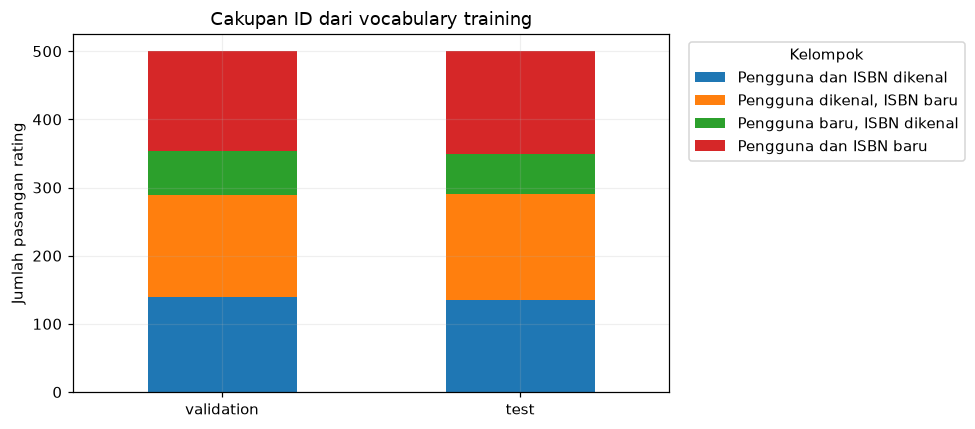

In [3]:
dataset = original["dataset"]
display(
    pd.DataFrame(
        [
            ("Rating mentah", dataset["raw_ratings_rows"]),
            (
                "Interaksi implicit/rating 0 yang dikeluarkan",
                dataset["implicit_interactions_excluded"],
            ),
            ("Rating eksplisit mentah", dataset["raw_explicit_rating_rows"]),
            (
                "Rating eksplisit bersih dengan metadata",
                dataset["clean_explicit_interactions_with_metadata"],
            ),
            ("Pasangan training", audit["train_pairs"]),
            ("Pengguna training", audit["train_users"]),
            ("ISBN training", audit["train_books"]),
            ("Kepadatan matriks (%)", 100 * audit["train_density"]),
            ("Median rating per pengguna", audit["median_ratings_per_user"]),
            (
                "Pengguna dengan paling banyak 3 rating (%)",
                100 * audit["users_at_most_3_ratings_fraction"],
            ),
            (
                "Pengguna dengan paling banyak 5 rating (%)",
                100 * audit["users_at_most_5_ratings_fraction"],
            ),
        ],
        columns=["ukuran", "nilai"],
    )
)
availability_names = {
    "both_known": "Pengguna dan ISBN dikenal",
    "known_user_unknown_book": "Pengguna dikenal, ISBN baru",
    "unknown_user_known_book": "Pengguna baru, ISBN dikenal",
    "both_unknown": "Pengguna dan ISBN baru",
}
coverage = pd.DataFrame(
    {
        split: {label: audit[split][key] for key, label in availability_names.items()}
        for split in ("validation", "test")
    }
)
assert (coverage.sum() == [audit["validation"]["pairs"], audit["test"]["pairs"]]).all()
display(coverage)
ax = coverage.T.plot.bar(stacked=True, figsize=(9, 4), rot=0)
ax.set(ylabel="Jumlah pasangan rating", title="Cakupan ID dari vocabulary training")
ax.legend(title="Kelompok", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## Konfigurasi dua run benchmark awal

MLP awal: `concat(user_embedding, book_embedding, user * book)` → Dense ReLU
32 → Dense ReLU 16 → sigmoid. Residual: baseline global + bias pengguna + bias
buku, ditambah `scale × MLP` dengan hidden LeakyReLU dan output linear yang
dimulai dari nol. Bias dihitung dari train dan dibekukan.

Semua neural memakai Adam, MSE rating ternormalisasi + L2, embedding 16,
hidden 32/16, learning rate 0.001, batch 1024, patience 3, dan seed 42.
Bias-only adalah kontrol tanpa training neural. L2 dan bentuk hidden tidak
berpengaruh pada prediksinya karena residual scale = 0.

Tabel ini menampilkan **4 konfigurasi neural yang dilatih + 1 kontrol**.
Baris “tidak dievaluasi” bukan skor nol: dua kandidat residual yang tidak
terpilih memang tidak dievaluasi pada test.

In [4]:
experiment_rows = [
    {
        "percobaan": "mlp_original",
        "keluarga": "MLP ReLU + sigmoid",
        "embedding": original_config["embedding_size"],
        "hidden": str(original_config["hidden_units"]),
        "learning_rate": original_config["learning_rate"],
        "batch": original_config["batch_size"],
        "L2": original_config["l2"],
        "residual_scale": None,
        "user/item shrinkage": "tidak berlaku",
        "seed": original_config["seed"],
        "epoch maksimum": original_config["requested_epochs"],
        "epoch selesai": original["training"]["epochs_completed"],
        "epoch terbaik": original["training"]["best_epoch"],
        "validation RMSE": min(row["val_rmse"] for row in original["training"]["history"]),
        "test RMSE (135)": original["rating_test"]["models"]["neural"]["rmse_rating_scale"],
        "status test": "dievaluasi pada run awal",
    }
]
for candidate in candidates:
    is_bias = candidate["kind"] == "bias_only"
    test_model = (
        "bias_only" if is_bias else "best_neural" if candidate["name"] == selected_name else None
    )
    experiment_rows.append(
        {
            "percobaan": candidate["name"],
            "keluarga": "kontrol bias-only" if is_bias else "bias + MLP LeakyReLU",
            "embedding": None if is_bias else residual_config["embedding_size"],
            "hidden": "tidak digunakan" if is_bias else str(residual_config["hidden_units"]),
            "learning_rate": None if is_bias else residual_config["learning_rate"],
            "batch": None if is_bias else residual_config["batch_size"],
            "L2": None if is_bias else candidate["l2"],
            "residual_scale": candidate["residual_scale"],
            "user/item shrinkage": f"{candidate['user_shrinkage']:g}/{candidate['item_shrinkage']:g}",
            "seed": residual_config["seed"],
            "epoch maksimum": 0 if is_bias else residual_config["max_neural_epochs_each"],
            "epoch selesai": candidate["epochs_completed"],
            "epoch terbaik": candidate["best_epoch"],
            "validation RMSE": candidate["validation"]["rmse_rating_scale"],
            "test RMSE (135)": (
                residual["rating_test"]["models"][test_model]["known_pairs"]["rmse_rating_scale"]
                if test_model
                else None
            ),
            "status test": "kontrol dievaluasi"
            if is_bias
            else "terpilih; dievaluasi"
            if test_model
            else "tidak dievaluasi",
        }
    )
experiments = pd.DataFrame(experiment_rows)
display(experiments.fillna("—"))
display(
    Markdown(
        f"Kandidat terpilih di antara empat kandidat run residual: **`{selected_name}`**. "
        "Pemilihan ini tidak memasukkan MLP dari run pertama sebagai kandidat baru "
        "dan tidak berarti residual mengalahkan MLP pada validation."
    )
)

,percobaan,keluarga,embedding,hidden,learning_rate,batch,L2,residual_scale,user/item shrinkage,seed,epoch maksimum,epoch selesai,epoch terbaik,validation RMSE,test RMSE (135),status test
0,mlp_original,MLP ReLU + sigmoid,16.0,"[32, 16]",0.001,1024.0,0.00001,—,tidak berlaku,42,8,5,2.0,1.62101792,1.50416735,dievaluasi pada run awal
1,bias_only_u0_i20,kontrol bias-only,—,tidak digunakan,—,—,—,0.0,0/20,42,0,0,—,1.74757269,1.40012861,kontrol dievaluasi
2,residual_u0_i20_s025,bias + MLP LeakyReLU,16.0,"[32, 16]",0.001,1024.0,0.00001,0.25,0/20,42,10,4,1.0,1.74660835,—,tidak dievaluasi
3,residual_u0_i20_s100,bias + MLP LeakyReLU,16.0,"[32, 16]",0.001,1024.0,0.00001,1.0,0/20,42,10,4,1.0,1.74678582,—,tidak dievaluasi
4,residual_u0_i20_s025_l2e4,bias + MLP LeakyReLU,16.0,"[32, 16]",0.001,1024.0,0.0001,0.25,0/20,42,10,4,1.0,1.74660387,1.40408569,terpilih; dievaluasi


Kandidat terpilih di antara empat kandidat run residual: **`residual_u0_i20_s025_l2e4`**. Pemilihan ini tidak memasukkan MLP dari run pertama sebagai kandidat baru dan tidak berarti residual mengalahkan MLP pada validation.

## Semua epoch, termasuk yang bukan checkpoint terbaik

RMSE dalam skala rating 1–10; MSE dalam skala normalisasi 0–1 dan tidak
termasuk penalti L2. Pada residual, objective optimisasi mini-batch memakai
output linear mentah + L2. Metrik train per epoch pada history, validation,
dan test memotong prediksi ke rentang rating valid sebelum dihitung.
Checkpoint terbaik dipulihkan setelah early stopping. Grafik setiap kandidat
memakai sumbu sendiri agar perubahan kecil terlihat; bandingkan angka tabel
untuk besaran absolut.

,percobaan,epoch,train_mse,train_rmse,val_mse,val_rmse,checkpoint terbaik
0,mlp_original,1,0.03051129,1.57207340,0.03488486,1.68097390,False
1,mlp_original,2,0.02414089,1.39836036,0.03244073,1.62101792,True
2,mlp_original,3,0.02273964,1.35717026,0.03307783,1.63685809,False
3,mlp_original,4,0.02218196,1.34042489,0.03429626,1.66673234,False
4,mlp_original,5,0.02186757,1.33089186,0.03433174,1.66759424,False
5,residual_u0_i20_s025,1,0.02276056,1.35779415,0.03766223,1.74660833,True
6,residual_u0_i20_s025,2,0.02276087,1.35780343,0.03771653,1.74786689,False
7,residual_u0_i20_s025,3,0.02275845,1.35773148,0.03768313,1.74709286,False
8,residual_u0_i20_s025,4,0.02275883,1.35774260,0.03767531,1.74691168,False
9,residual_u0_i20_s100,1,0.02275936,1.35775843,0.03766988,1.74678575,True


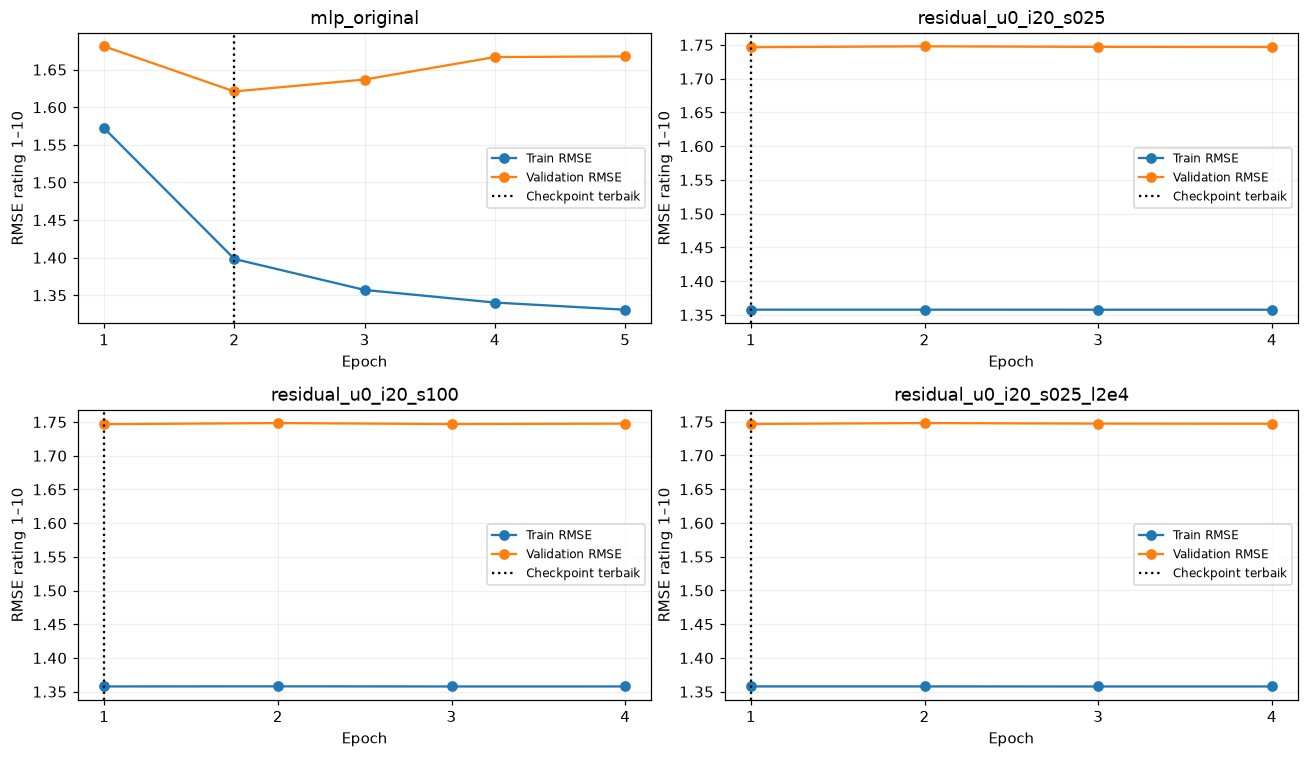

In [5]:
histories = {"mlp_original": original["training"]["history"]}
histories.update({c["name"]: c["history"] for c in candidates if c["history"]})
best_epochs = experiments.set_index("percobaan")["epoch terbaik"].to_dict()
epochs = pd.DataFrame(
    [
        {"percobaan": name, **record, "checkpoint terbaik": record["epoch"] == best_epochs[name]}
        for name, history in histories.items()
        for record in history
    ]
)
display(epochs)
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, (name, history) in zip(axes.flat, histories.items(), strict=True):
    frame = pd.DataFrame(history)
    ax.plot(frame["epoch"], frame["train_rmse"], "o-", label="Train RMSE")
    ax.plot(frame["epoch"], frame["val_rmse"], "o-", label="Validation RMSE")
    ax.axvline(best_epochs[name], color="black", linestyle=":", label="Checkpoint terbaik")
    ax.set(title=name, xlabel="Epoch", ylabel="RMSE rating 1–10", xticks=frame["epoch"])
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
assert (
    len(epochs)
    == original["training"]["epochs_completed"] + residual["training"]["total_neural_epochs"]
)

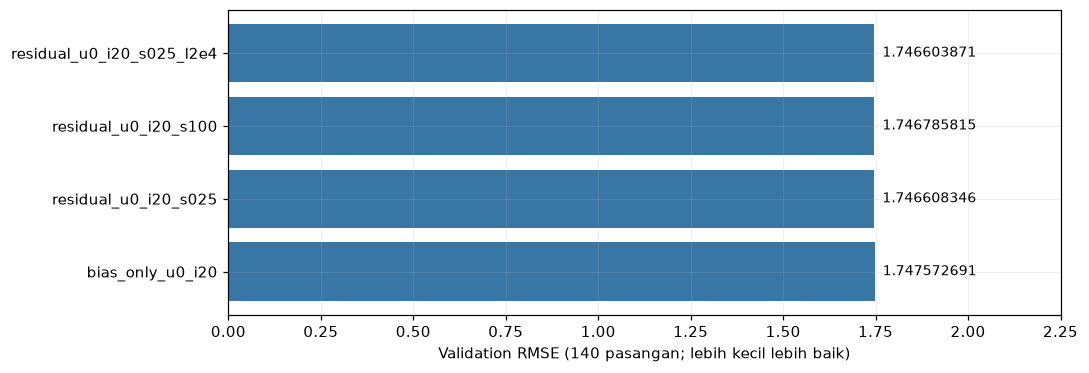

Dua kandidat residual teratas hanya berbeda **0.00000447 RMSE** pada 140 pasangan validation. Ini belum membuktikan nilai L2 terpilih optimal. MLP awal berhenti membaik setelah epoch 2; residual terbaik berada di epoch 1. Menambah epoch saja belum didukung hasil ini.

In [6]:
residual_validation = experiments[experiments["percobaan"] != "mlp_original"]
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.barh(residual_validation["percobaan"], residual_validation["validation RMSE"], color="#3876a5")
for index, value in enumerate(residual_validation["validation RMSE"]):
    ax.text(value, index, f"  {value:.9f}", va="center", fontsize=9)
ax.set(xlabel="Validation RMSE (140 pasangan; lebih kecil lebih baik)", xlim=(0, 2.25))
plt.tight_layout()
plt.show()
neural_candidates = sorted(
    (c for c in candidates if c["kind"] == "neural"),
    key=lambda c: c["validation"]["rmse_rating_scale"],
)
candidate_gap = (
    neural_candidates[1]["validation"]["rmse_rating_scale"]
    - neural_candidates[0]["validation"]["rmse_rating_scale"]
)
display(
    Markdown(
        f"Dua kandidat residual teratas hanya berbeda **{candidate_gap:.8f} RMSE** "
        "pada 140 pasangan validation. Ini belum membuktikan nilai L2 terpilih optimal. "
        "MLP awal berhenti membaik setelah epoch 2; residual terbaik berada di epoch 1. "
        "Menambah epoch saja belum didukung hasil ini."
    )
)

## Rating: cohort yang sama dan seluruh pengguna dengan fallback

Tabel pertama membandingkan 135 pasangan dengan kedua ID dikenal. Angka MLP
berasal dari run awal, dengan input identik; model itu tidak dilatih ulang
pada run residual. Tabel berikutnya mencakup 500 pasangan. Untuk bias/residual,
365 pasangan cold memakai fallback tetap: mean pengguna → mean ISBN → mean
global dari train. Jadi angka 500 pasangan tidak berarti embedding melayani
semua pengguna/buku. Empat prediksi warm bias/residual dipotong ke rentang 1–10.

Baseline tersedia lengkap, termasuk mean item. `selected_serving` dan
`best_neural` pada JSON adalah model yang sama dalam run ini; tidak dihitung
sebagai dua percobaan berbeda.

In [7]:
model_labels = {
    "train_global_mean": "Mean global",
    "train_user_mean_global_fallback": "Mean user → global",
    "train_item_mean_global_fallback": "Mean ISBN → global",
    "train_user_item_global_fallback": "Mean user → ISBN → global",
    "bias_only": "Bias-only",
    "best_neural": "Residual terpilih",
}
warm_rows = [
    {
        "model": "MLP awal",
        "pasangan": original["rating_test"]["known_pairs"],
        "RMSE": original["rating_test"]["models"]["neural"]["rmse_rating_scale"],
        "MAE": original["rating_test"]["models"]["neural"]["mae_rating_scale"],
    }
]
full_rows, group_rows = [], []
for key, label in model_labels.items():
    model_result = residual["rating_test"]["models"][key]
    for scope, target in (("known_pairs", warm_rows), ("all_pairs", full_rows)):
        metric = model_result[scope]
        target.append(
            {
                "model": label,
                "pasangan": metric["pairs"],
                "RMSE": metric["rmse_rating_scale"],
                "MAE": metric["mae_rating_scale"],
            }
        )
    for group, metric in model_result["by_availability"].items():
        group_rows.append(
            {
                "model": label,
                "kelompok": group,
                "pasangan": metric["pairs"],
                "RMSE": metric["rmse_rating_scale"],
                "MAE": metric["mae_rating_scale"],
            }
        )
display(Markdown("**135 pasangan warm: seluruh hasil rating yang dievaluasi**"))
display(pd.DataFrame(warm_rows))
display(Markdown("**500 pasangan dengan fallback: run residual**"))
display(pd.DataFrame(full_rows))
display(Markdown("**Rincian menurut ketersediaan ID**"))
display(pd.DataFrame(group_rows))

**135 pasangan warm: seluruh hasil rating yang dievaluasi**

,model,pasangan,RMSE,MAE
0,MLP awal,135,1.50416735,1.18921292
1,Mean global,135,1.75367068,1.41584818
2,Mean user → global,135,1.42250871,1.13925730
3,Mean ISBN → global,135,1.73565660,1.37132377
4,Mean user → ISBN → global,135,1.42250871,1.13925730
5,Bias-only,135,1.40012861,1.09267439
6,Residual terpilih,135,1.40408569,1.09927615


**500 pasangan dengan fallback: run residual**

,model,pasangan,RMSE,MAE
0,Mean global,500,1.91560145,1.53535882
1,Mean user → global,500,1.78517698,1.41017876
2,Mean ISBN → global,500,1.89759691,1.50981921
3,Mean user → ISBN → global,500,1.77064209,1.39666074
4,Bias-only,500,1.76581915,1.38408335
5,Residual terpilih,500,1.76666729,1.38586583


**Rincian menurut ketersediaan ID**

,model,kelompok,pasangan,RMSE,MAE
0,Mean global,both_known,135,1.75367068,1.41584818
1,Mean global,known_user_unknown_isbn,156,2.00773054,1.59128274
2,Mean global,unknown_user_known_isbn,58,1.91800703,1.52068734
3,Mean global,both_unknown,151,1.95544748,1.59006578
4,Mean user → global,both_known,135,1.42250871,1.13925730
5,Mean user → global,known_user_unknown_isbn,156,1.84233371,1.42942208
6,Mean user → global,unknown_user_known_isbn,58,1.91800703,1.52068734
7,Mean user → global,both_unknown,151,1.95544748,1.59006578
8,Mean ISBN → global,both_known,135,1.73565660,1.37132377
9,Mean ISBN → global,known_user_unknown_isbn,156,2.00773054,1.59128274


## Ketidakpastian: urutan validation dan test dapat berbalik

Bootstrap berikut sudah tersimpan dari run residual: 1.000 pengambilan ulang
pasangan yang sama, seed 123. Interval ini bersyarat pada satu split test yang
telah dipakai ulang; ia tidak memperbaiki bias akibat proses pengembangan.
Interval melintasi nol, sehingga peningkatan residual atas mean pengguna
belum meyakinkan. Mengalahkan mean pengguna juga berbeda dari mengalahkan
kontrol bias-only, yang justru memiliki RMSE test sedikit lebih rendah.

In [8]:
bootstrap = residual["rating_test"]["best_neural_vs_user_mean_paired_bootstrap"]
display(
    pd.DataFrame(
        [
            {
                "perbandingan": "Residual RMSE − mean user RMSE",
                "pasangan": bootstrap["pairs"],
                "bootstrap draws": bootstrap["draws"],
                "selisih": bootstrap["point_estimate"],
                "batas bawah 95%": bootstrap["interval_95_percent"][0],
                "batas atas 95%": bootstrap["interval_95_percent"][1],
            }
        ]
    )
)
ordering = pd.DataFrame(
    [
        ("MLP awal", experiments.iloc[0]["validation RMSE"], warm_rows[0]["RMSE"]),
        (
            "Mean user",
            residual["selection"]["validation_user_mean"]["rmse_rating_scale"],
            residual["rating_test"]["models"]["train_user_mean_global_fallback"]["known_pairs"][
                "rmse_rating_scale"
            ],
        ),
        (
            "Bias-only",
            candidates[0]["validation"]["rmse_rating_scale"],
            residual["rating_test"]["models"]["bias_only"]["known_pairs"]["rmse_rating_scale"],
        ),
        (
            "Residual terpilih",
            residual["selection"]["best_neural_validation"]["rmse_rating_scale"],
            residual["rating_test"]["models"]["best_neural"]["known_pairs"]["rmse_rating_scale"],
        ),
    ],
    columns=["model", "validation RMSE (140)", "test RMSE (135)"],
)
display(ordering)

,perbandingan,pasangan,bootstrap draws,selisih,batas bawah 95%,batas atas 95%
0,Residual RMSE − mean user RMSE,135,1000,-0.01842302,-0.07105577,0.02907417


,model,validation RMSE (140),test RMSE (135)
0,MLP awal,1.62101792,1.50416735
1,Mean user,1.81813799,1.42250871
2,Bias-only,1.74757269,1.40012861
3,Residual terpilih,1.74660387,1.40408569


## Ranking: tujuan rekomendasi belum membaik

Evaluasi ranking memakai 272 holdout dengan rating ≥8 dan katalog kandidat
yang sama (5.000 ISBN / 4.364 karya). Target yang tidak ada dalam katalog
tetap dihitung sebagai miss. Hanya 93 holdout memiliki target kandidat dan
riwayat pengguna; cohort bersyarat ini ditampilkan terpisah.

Satu holdout relevan per pengguna membuat Recall@10 = Hit Rate@10 pada
protokol ini. Objective pemilihan model adalah RMSE rating, bukan NDCG/Recall.
Hasil MLP dan residual yang sama di sini tidak membuktikan skor prediksinya
identik; hanya metrik ranking agregatnya yang sama.
Kedua hit pada jalur neural berasal dari fallback popularity untuk pengguna
baru; pada 93 kasus dengan target dan riwayat tersedia, neural memperoleh 0 hit.

,test_holdouts,relevant_test_holdouts_rating_ge_8,candidate_work_available,train_user_history_available,candidate_and_history_available,candidate_isbns,candidate_canonical_works,scope,paired,top_k
0,500,272,129,160,93,5000,4364,all relevant test holdouts; unavailable targets remain explicit misses,True,10


,run,model,cohort,jumlah,hits@10,precision_at_10,recall_at_10,hit_rate_at_10,map_at_10,mrr_at_10,ndcg_at_10
0,MLP awal,neural_with_popularity_fallback,seluruh target relevan,272,2,0.00073529,0.00735294,0.00735294,0.00413603,0.00413603,0.00483627
1,MLP awal,neural_with_popularity_fallback,target + history tersedia,93,0,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000
2,MLP awal,item_based_with_popularity_fallback,seluruh target relevan,272,5,0.00183824,0.01838235,0.01838235,0.01148897,0.01148897,0.01315193
3,MLP awal,item_based_with_popularity_fallback,target + history tersedia,93,3,0.00322581,0.03225806,0.03225806,0.02150538,0.02150538,0.02432107
4,MLP awal,popularity,seluruh target relevan,272,5,0.00183824,0.01838235,0.01838235,0.01201418,0.01201418,0.01341470
5,MLP awal,popularity,target + history tersedia,93,3,0.00322581,0.03225806,0.03225806,0.02304147,0.02304147,0.02508961
6,Residual terpilih,neural_with_popularity_fallback,seluruh target relevan,272,2,0.00073529,0.00735294,0.00735294,0.00413603,0.00413603,0.00483627
7,Residual terpilih,neural_with_popularity_fallback,target + history tersedia,93,0,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000
8,Residual terpilih,item_based_with_popularity_fallback,seluruh target relevan,272,5,0.00183824,0.01838235,0.01838235,0.01148897,0.01148897,0.01315193
9,Residual terpilih,item_based_with_popularity_fallback,target + history tersedia,93,3,0.00322581,0.03225806,0.03225806,0.02150538,0.02150538,0.02432107


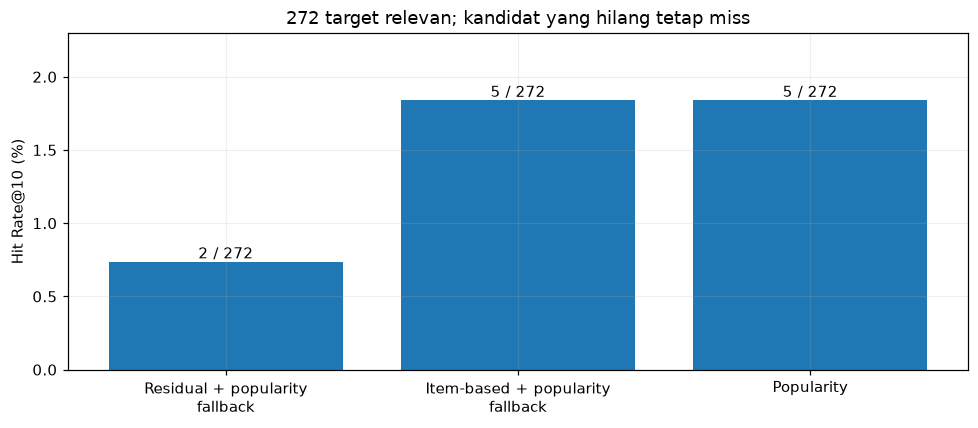

In [9]:
display(pd.DataFrame([residual["ranking_test"]["availability"]]))
ranking_rows = []
for run_label, result in (("MLP awal", original), ("Residual terpilih", residual)):
    for model_name, model_result in result["ranking_test"]["models"].items():
        for scope, count_key, metric_key in (
            ("seluruh target relevan", "count", "metrics"),
            ("target + history tersedia", "conditional_count", "conditional_metrics"),
        ):
            count, metrics = model_result[count_key], model_result[metric_key]
            ranking_rows.append(
                {
                    "run": run_label,
                    "model": model_name,
                    "cohort": scope,
                    "jumlah": count,
                    "hits@10": round(metrics["hit_rate_at_10"] * count),
                    **metrics,
                }
            )
ranking = pd.DataFrame(ranking_rows)
display(ranking)
fig, ax = plt.subplots(figsize=(9, 4))
ranking_plot = ranking[
    (ranking["run"] == "Residual terpilih") & (ranking["cohort"] == "seluruh target relevan")
]
ax.bar(
    ["Residual + popularity\nfallback", "Item-based + popularity\nfallback", "Popularity"],
    ranking_plot["hit_rate_at_10"] * 100,
)
ax.set(ylabel="Hit Rate@10 (%)", title="272 target relevan; kandidat yang hilang tetap miss")
for index, (_, row) in enumerate(ranking_plot.iterrows()):
    ax.text(
        index,
        row["hit_rate_at_10"] * 100,
        f"{row['hits@10']} / {row['jumlah']}",
        ha="center",
        va="bottom",
    )
ax.set_ylim(0, max(ranking_plot["hit_rate_at_10"]) * 125)
plt.tight_layout()
plt.show()

## Bukti satu langkah: embedding → forward → loss → gradient → Adam

Trace pertama setiap neural menyimpan delapan pasangan encoded ID, target,
prediksi sebelum/sesudah pembaruan, loss, norma gradient per variabel, dan
satu vektor embedding yang benar-benar berubah. Ini membuktikan mekanisme
training; delapan contoh ini bukan hasil evaluasi generalisasi.

**Perhatian pada residual:** output head dimulai dari nol. Pada langkah
pertama, gradient dari data menuju embedding adalah nol; perubahan embedding
saat itu berasal dari regularisasi. Setelah head berubah, gradient data dapat
mengalir ke embedding. Trace langkah pertama tidak cukup untuk menyimpulkan
besarnya kontribusi neural setelah training.

In [10]:
traces = {"mlp_original": evidence["original_trace"]}
traces.update({c["name"]: c["first_step_trace"] for c in candidates if c["first_step_trace"]})
trace_rows, prediction_rows, gradient_rows, embedding_rows = [], [], [], []
for name, trace in traces.items():
    trace_rows.append(
        {
            "percobaan": name,
            "MSE sebelum": trace["mse_before"],
            "L2 loss": trace["regularization_loss"],
            "L2 / MSE": trace["regularization_loss"] / trace["mse_before"],
            "total loss sebelum": trace["total_loss_before"],
            "MSE setelah": trace["mse_after"],
            "norma perubahan embedding": trace["embedding_delta_norm"],
            "gradient data embedding sebelum": trace.get(
                "embedding_data_gradient_norm_before", "tidak dipisah dalam trace"
            ),
            "optimizer": trace["optimizer"],
            "iterasi optimizer": trace["optimizer_iterations"],
        }
    )
    for index, pair in enumerate(trace["encoded_pairs"]):
        prediction_rows.append(
            {
                "percobaan": name,
                "user_idx": pair[0],
                "book_idx": pair[1],
                "target [0,1]": trace["targets_normalized"][index],
                "prediksi sebelum": trace["predictions_before"][index],
                "prediksi setelah": trace["predictions_after"][index],
            }
        )
    gradient_rows.extend(
        {"percobaan": name, "variabel": variable, "norma gradient total": norm}
        for variable, norm in trace["gradient_norms"].items()
    )
    for index, (before, gradient, after) in enumerate(
        zip(
            trace["user_embedding_before"],
            trace["user_embedding_gradient"],
            trace["user_embedding_after"],
            strict=True,
        )
    ):
        embedding_rows.append(
            {
                "percobaan": name,
                "dimensi": index,
                "sebelum": before,
                "gradient total": gradient,
                "setelah": after,
                "delta": after - before,
            }
        )
display(pd.DataFrame(trace_rows))
display(Markdown("**Semua prediksi dari mini-batch trace**"))
display(pd.DataFrame(prediction_rows))
display(Markdown("**Norma gradient semua variabel**"))
display(pd.DataFrame(gradient_rows))
display(Markdown("**Seluruh 16 dimensi embedding pengguna yang dicatat per model**"))
display(pd.DataFrame(embedding_rows))

,percobaan,MSE sebelum,L2 loss,L2 / MSE,total loss sebelum,MSE setelah,norma perubahan embedding,gradient data embedding sebelum,optimizer,iterasi optimizer
0,mlp_original,0.10344350,0.00330554,0.03195501,0.10674904,0.10217442,0.00285233,tidak dipisah dalam trace,Adam,1
1,residual_u0_i20_s025,0.02185019,0.00330554,0.15128190,0.02515572,0.02184925,0.00051843,0.0,Adam,1
2,residual_u0_i20_s100,0.02185019,0.00330554,0.15128190,0.02515572,0.02184707,0.00051843,0.0,Adam,1
3,residual_u0_i20_s025_l2e4,0.02185019,0.03305538,1.51281890,0.05490556,0.02184925,0.00210640,0.0,Adam,1


**Semua prediksi dari mini-batch trace**

,percobaan,user_idx,book_idx,"target [0,1]",prediksi sebelum,prediksi setelah
0,mlp_original,14257,496,0.66666669,0.50083983,0.50421065
1,mlp_original,6281,2902,0.44444445,0.49836883,0.50021511
2,mlp_original,5640,136,0.77777779,0.49733859,0.50009817
3,mlp_original,10973,2850,0.77777779,0.49414054,0.49669135
4,mlp_original,12009,427,1.00000000,0.49666676,0.49869099
5,mlp_original,8097,492,0.77777779,0.49719414,0.49908781
6,mlp_original,5832,3301,0.33333334,0.49442747,0.49560919
7,mlp_original,5860,3259,0.33333334,0.49810806,0.49984127
8,residual_u0_i20_s025,14257,496,0.66666669,0.74992216,0.75016552
9,residual_u0_i20_s025,6281,2902,0.44444445,0.79401517,0.79425740


**Norma gradient semua variabel**

,percobaan,variabel,norma gradient total
0,mlp_original,neural_rating_model/user_embedding/embeddings,0.00289193
1,mlp_original,neural_rating_model/book_embedding/embeddings,0.00283234
2,mlp_original,neural_rating_model/hidden_1/kernel,0.00184983
3,mlp_original,neural_rating_model/hidden_1/bias,0.05813906
4,mlp_original,neural_rating_model/hidden_2/kernel,0.00650464
5,mlp_original,neural_rating_model/hidden_2/bias,0.10885516
6,mlp_original,neural_rating_model/rating/kernel,0.00486194
7,mlp_original,neural_rating_model/rating/bias,0.12975737
8,residual_u0_i20_s025,residual_rating_model/user_embedding/embeddings,0.00028583
9,residual_u0_i20_s025,residual_rating_model/book_embedding/embeddings,0.00016353


**Seluruh 16 dimensi embedding pengguna yang dicatat per model**

,percobaan,dimensi,sebelum,gradient total,setelah,delta
0,mlp_original,0,-0.04974351,0.00001182,-0.05053239,-0.00078888
1,mlp_original,1,-0.01019793,-0.00001202,-0.00940618,0.00079175
2,mlp_original,2,0.00132374,-0.00000999,0.00208333,0.00075960
3,mlp_original,3,0.01385297,0.00000566,0.01321157,-0.00064139
4,mlp_original,4,-0.02267543,-0.00000546,-0.02204203,0.00063340
5,mlp_original,5,0.00155924,0.00001200,0.00076787,-0.00079137
6,mlp_original,6,-0.02060500,0.00001383,-0.02141892,-0.00081392
7,mlp_original,7,-0.01676138,0.00001057,-0.01753102,-0.00076964
8,mlp_original,8,-0.04029386,-0.00001975,-0.03943189,0.00086197
9,mlp_original,9,0.04074014,0.00000635,0.04007254,-0.00066760


## Diagnosis bobot tersimpan: seberapa personal koreksi residual?

Audit tambahan membaca bobot checkpoint dengan NumPy, melakukan forward pass
pada train dan validation yang sama, dan memeriksa kecocokan RMSE validation
terhadap hasil TensorFlow tersimpan. Tidak ada training atau evaluasi test
tambahan. Script reproduksinya:
[`scripts/audit_residual_signal.py`](../scripts/audit_residual_signal.py).

Koreksi berikut dinyatakan pada skala rating 1–10, **sebelum clipping**, yaitu
`9 × residual_scale × output_MLP`. Standar deviasi yang sangat kecil berarti
hampir semua pasangan mendapat koreksi yang sama; nilai rata-rata koreksi
saja bukan bukti personalisasi. Rasio norma embedding dibandingkan kontrol
tanpa training dengan inisialisasi seed yang sama.

In [11]:
signal_audit = evidence["residual_signal"]
assert signal_audit["selected_candidate"] == selected_name
signal_rows, norm_rows, agreement_rows = [], [], []
for candidate in signal_audit["candidates"]:
    for split in ("train", "validation"):
        metric = candidate[f"{split}_residual_rating"]
        signal_rows.append(
            {
                "percobaan": candidate["name"],
                "cohort": split,
                "pasangan": metric["pairs"],
                "koreksi mean": metric["mean"],
                "koreksi std": metric["std"],
                "koreksi min": metric["min"],
                "koreksi max": metric["max"],
            }
        )
    for layer, norm in candidate["embedding_norms"].items():
        ratio = candidate["embedding_norm_ratio_to_untrained_control"][layer]
        norm_rows.append(
            {
                "percobaan": candidate["name"],
                "embedding": layer,
                "norma tersimpan": norm,
                "rasio terhadap kontrol awal": ratio,
                "penurunan norma (%)": (1 - ratio) * 100,
            }
        )
    agreement_rows.append({"percobaan": candidate["name"], **candidate["validation_check"]})
    assert candidate["validation_check"]["passed"]
display(Markdown("**Koreksi residual untuk setiap pasangan train dan validation warm**"))
display(pd.DataFrame(signal_rows))
display(Markdown("**Norma embedding checkpoint terhadap kontrol awal**"))
display(pd.DataFrame(norm_rows))
display(Markdown("**Pemeriksaan kesesuaian forward NumPy dengan metrik TensorFlow tersimpan**"))
display(pd.DataFrame(agreement_rows))
selected_signal = next(c for c in signal_audit["candidates"] if c["name"] == selected_name)
display(
    Markdown(
        f"Koreksi residual terpilih pada **{signal_audit['train_pairs']:,}** pasangan "
        f"train: mean **{selected_signal['train_residual_rating']['mean']:.8f}** rating, "
        f"standar deviasi **{selected_signal['train_residual_rating']['std']:.9f}**. "
        "Ini bukti bahwa koreksi yang dipelajari hampir konstan, bukan personalisasi "
        "yang kuat. Penyusutan embedding terukur; apakah L2 menyebabkan hilangnya "
        "sinyal harus diuji melalui ablation terkontrol."
    )
)

**Koreksi residual untuk setiap pasangan train dan validation warm**

,percobaan,cohort,pasangan,koreksi mean,koreksi std,koreksi min,koreksi max
0,bias_only_u0_i20,train,111875,0.00000000,0.00000000,0.00000000,0.00000000
1,bias_only_u0_i20,validation,140,0.00000000,0.00000000,0.00000000,0.00000000
2,residual_u0_i20_s025,train,111875,-0.02180740,0.00001040,-0.02185371,-0.02176189
3,residual_u0_i20_s025,validation,140,-0.02180704,0.00001069,-0.02183744,-0.02177856
4,residual_u0_i20_s025_l2e4,train,111875,-0.02192274,0.00000136,-0.02192800,-0.02191470
5,residual_u0_i20_s025_l2e4,validation,140,-0.02192278,0.00000132,-0.02192601,-0.02191699
6,residual_u0_i20_s100,train,111875,-0.01730458,0.00000883,-0.01735406,-0.01726187
7,residual_u0_i20_s100,validation,140,-0.01730435,0.00000913,-0.01732678,-0.01727125


**Norma embedding checkpoint terhadap kontrol awal**

,percobaan,embedding,norma tersimpan,rasio terhadap kontrol awal,penurunan norma (%)
0,bias_only_u0_i20,user_embedding,14.29158894,1.00000000,0.00000000
1,bias_only_u0_i20,book_embedding,8.17639556,1.00000000,0.00000000
2,residual_u0_i20_s025,user_embedding,0.96340252,0.06741046,93.25895445
3,residual_u0_i20_s025,book_embedding,0.55433702,0.06779724,93.22027645
4,residual_u0_i20_s025_l2e4,user_embedding,0.07156433,0.00500744,99.49925558
5,residual_u0_i20_s025_l2e4,book_embedding,0.04167815,0.00509737,99.49026256
6,residual_u0_i20_s100,user_embedding,0.98553903,0.06895937,93.10406259
7,residual_u0_i20_s100,book_embedding,0.60046991,0.07343944,92.65605600


**Pemeriksaan kesesuaian forward NumPy dengan metrik TensorFlow tersimpan**

,percobaan,saved_rmse,numpy_rmse,absolute_difference,absolute_tolerance,passed
0,bias_only_u0_i20,1.74757269,1.74757269,0.0,0.00001,True
1,residual_u0_i20_s025,1.74660835,1.74660835,0.0,0.00001,True
2,residual_u0_i20_s025_l2e4,1.74660387,1.74660387,0.0,0.00001,True
3,residual_u0_i20_s100,1.74678582,1.74678582,0.0,0.00001,True


Koreksi residual terpilih pada **111,875** pasangan train: mean **-0.02192274** rating, standar deviasi **0.000001356**. Ini bukti bahwa koreksi yang dipelajari hampir konstan, bukan personalisasi yang kuat. Penyusutan embedding terukur; apakah L2 menyebabkan hilangnya sinyal harus diuji melalui ablation terkontrol.

## Ablation lanjutan: apakah regularisasi menekan kontribusi neural?

Run ketiga menguji diagnosis koreksi hampir konstan, **hanya pada train dan
validation yang sama**. Worker tidak menerima atau membaca CSV test, dan
tidak menghasilkan metrik test/ranking baru. Validation ini sudah dipakai
untuk pengembangan sebelumnya; perbaikan di sini perlu dikonfirmasi melalui
evaluasi independen setelah rancangan model dibekukan.

Dua kontrol membedakan kemampuan neural dari kalibrasi sederhana:
**bias-only** dan **bias + satu konstanta yang dihitung dari residual train**.
Lima neural memakai head nol dengan L2 1e-4, 1e-5, 1e-6, 1e-7, atau 0;
satu neural mengubah hanya inisialisasi head menjadi acak kecil pada L2 1e-6.
Faktor lain tetap. Setiap epoch, checkpoint terbaik, gradient data/L2,
norma embedding, dan variasi koreksi disimpan agar mekanisme dapat diperiksa.
L2 1e-4 dan 1e-5 dengan head nol sengaja mengulang konfigurasi residual
terdahulu; delapan baris run ini bukan delapan konfigurasi yang seluruhnya baru.

Kontrol skalar memakai rata-rata `(target_normalized - baseline_raw)` pada
train. Tidak ada konstanta yang dioptimalkan menggunakan validation.

,run,session,selesai (Asia/Jakarta),GPU,TensorFlow,durasi (detik),status,semua kandidat selesai,pasangan train,validation tersedia,validation kedua ID dikenal,test digunakan,arsip terverifikasi,runtime dihentikan,sumber daya berbayar diizinkan
0,Ablation regularisasi dan inisialisasi head,book-recommendation-neural-20261014-ablation,2026-10-14T03:27:58.508503+07:00,Tesla T4,2.21.0,99.07783063,completed,True,111875,500,140,False,23,True,False


,percobaan,jenis,status,catatan kegagalan,L2,head,embedding,hidden,learning rate,batch,seed,epoch maksimum,epoch selesai,epoch terbaik,validation pasangan,validation RMSE,validation MAE,konstanta skala rating,durasi (detik),status test
0,bias_only,bias_only,completed,—,—,tidak digunakan,—,—,—,—,42,0,0,—,140,1.74757269,1.28981335,0.0,6.97161506,tidak dijalankan
1,bias_plus_train_fitted_scalar,bias_plus_scalar,completed,—,—,tidak digunakan,—,—,—,—,42,0,0,—,140,1.74700042,1.29032799,-0.01220403,3.78172654,tidak dijalankan
2,residual_l2_1e4_zero_head,neural,completed,—,0.0001,zeros,16.0,"[32, 16]",0.001,1024.0,42,10,4,1.0,140,1.74660387,1.29088337,—,13.75096992,tidak dijalankan
3,residual_l2_1e5_zero_head,neural,completed,—,0.00001,zeros,16.0,"[32, 16]",0.001,1024.0,42,10,4,1.0,140,1.74660835,1.29087700,—,12.97200689,tidak dijalankan
4,residual_l2_1e6_zero_head,neural,completed,—,0.000001,zeros,16.0,"[32, 16]",0.001,1024.0,42,10,4,1.0,140,1.74659913,1.29086541,—,13.02927857,tidak dijalankan
5,residual_l2_1e7_zero_head,neural,completed,—,0.0000001,zeros,16.0,"[32, 16]",0.001,1024.0,42,10,4,1.0,140,1.74658401,1.29087539,—,13.47014434,tidak dijalankan
6,residual_l2_0_zero_head,neural,completed,—,0.0,zeros,16.0,"[32, 16]",0.001,1024.0,42,10,4,1.0,140,1.74658080,1.29086509,—,13.10255728,tidak dijalankan
7,residual_l2_1e6_tiny_random_head,neural,completed,—,0.000001,normal_std_0.001_seed_2026,16.0,"[32, 16]",0.001,1024.0,42,10,4,1.0,140,1.74659087,1.29086276,—,13.27883332,tidak dijalankan


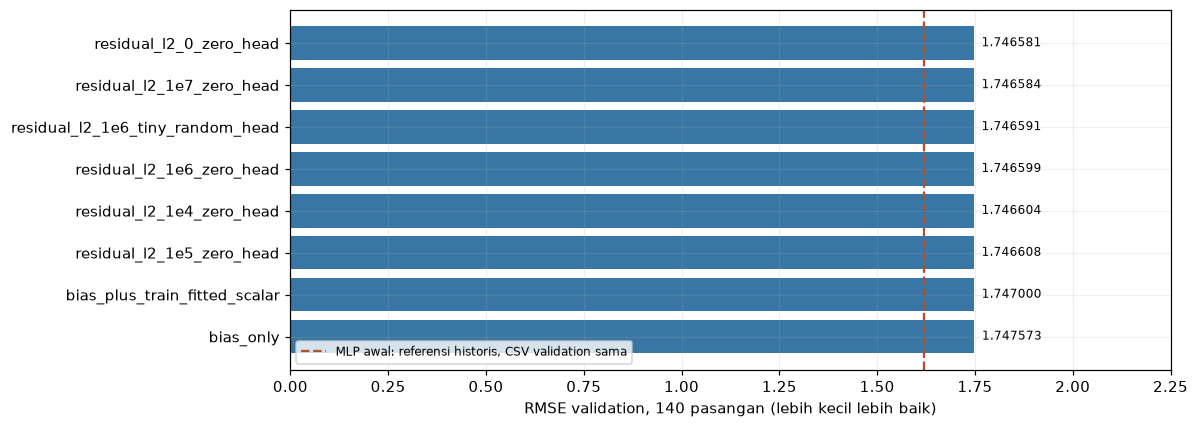

**Konfigurasi lengkap run; termasuk batas waktu dan spesifikasi kandidat**

,nilai
started_utc,2026-10-13T20:26:19.430693+00:00
candidates,"[{'name': 'bias_only', 'kind': 'bias_only', 'l2': 0.0, 'head_initialization': 'zeros'}..."
candidate_count,8
max_neural_epochs_each,10
batch_size,1024
patience,3
embedding_size,16
hidden_units,"[32, 16]"
learning_rate,0.001
user_shrinkage,0.0


**Kriteria dan hasil seleksi berdasarkan validation**

,nilai
selected_utc,2026-10-13T20:27:58.505637+00:00
metric,known_validation_rmse_rating_scale
best_candidate,residual_l2_0_zero_head
best_neural_candidate,residual_l2_0_zero_head
completed_candidates,8
declared_candidates,8
test_used,False
model_promotion_to_application,False
scope,Diagnostic candidate ranking on the existing development validation only
validation.pairs,140


In [12]:
ablation = evidence["ablation"]
ablation_manifest = evidence["ablation_manifest"]
assert ablation["schema_version"] == 1
assert ablation["test_used"] is False
assert ablation["dataset"]["input_bytes_match_original_experiment"]
assert ablation["dataset"]["canonical_work_leakage_checks_passed"]
assert ablation["dataset"]["train_pairs"] == audit["train_pairs"]
assert ablation["dataset"]["validation_known_pairs"] == audit["validation"]["both_known"]
ablation_config = ablation["configuration"]
ablation_candidates = ablation["candidate_validation_results"]
ablation_by_name = {candidate["name"]: candidate for candidate in ablation_candidates}
ablation_neural = [candidate for candidate in ablation_candidates if candidate["kind"] == "neural"]
display(
    pd.DataFrame(
        [
            {
                "run": "Ablation regularisasi dan inisialisasi head",
                "session": ablation_manifest["session_name"],
                "selesai (Asia/Jakarta)": pd.Timestamp(ablation["completed_utc"])
                .tz_convert("Asia/Jakarta")
                .isoformat(),
                "GPU": ablation["gpu"]["gpu_details"][0]["device_name"],
                "TensorFlow": ablation["gpu"]["tensorflow_version"],
                "durasi (detik)": ablation["total_seconds"],
                "status": ablation["status"],
                "semua kandidat selesai": ablation["all_candidates_completed"],
                "pasangan train": ablation["dataset"]["train_pairs"],
                "validation tersedia": ablation["dataset"]["validation_pairs"],
                "validation kedua ID dikenal": ablation["dataset"]["validation_known_pairs"],
                "test digunakan": ablation["test_used"],
                "arsip terverifikasi": len(ablation_manifest["backups"]),
                "runtime dihentikan": ablation_manifest["shutdown"]["stopped"],
                "sumber daya berbayar diizinkan": ablation_manifest.get(
                    "paid_resources_authorized", False
                ),
            }
        ]
    )
)
ablation_rows = []
for candidate in ablation_candidates:
    metric = candidate.get("validation") or {}
    is_neural = candidate["kind"] == "neural"
    ablation_rows.append(
        {
            "percobaan": candidate["name"],
            "jenis": candidate["kind"],
            "status": candidate["status"],
            "catatan kegagalan": candidate.get("message", "—"),
            "L2": candidate.get("l2") if is_neural else None,
            "head": candidate.get("head_initialization") if is_neural else "tidak digunakan",
            "embedding": ablation_config["embedding_size"] if is_neural else None,
            "hidden": str(ablation_config["hidden_units"]) if is_neural else "—",
            "learning rate": ablation_config["learning_rate"] if is_neural else None,
            "batch": ablation_config["batch_size"] if is_neural else None,
            "seed": ablation_config["seed"],
            "epoch maksimum": ablation_config["max_neural_epochs_each"] if is_neural else 0,
            "epoch selesai": candidate["epochs_completed"],
            "epoch terbaik": candidate["best_epoch"],
            "validation pasangan": metric.get("pairs"),
            "validation RMSE": metric.get("rmse_rating_scale"),
            "validation MAE": metric.get("mae_rating_scale"),
            "konstanta skala rating": (
                9 * candidate["scalar_intercept_normalized"]
                if "scalar_intercept_normalized" in candidate
                else None
            ),
            "durasi (detik)": candidate.get("seconds"),
            "status test": "tidak dijalankan",
        }
    )
ablation_experiments = pd.DataFrame(ablation_rows)
display(ablation_experiments.fillna("—"))
fig, ax = plt.subplots(figsize=(11, 4))
comparison = ablation_experiments.sort_values("validation RMSE", ascending=False)
ax.barh(comparison["percobaan"], comparison["validation RMSE"], color="#3876a5")
for index, value in enumerate(comparison["validation RMSE"]):
    if pd.notna(value):
        ax.text(value, index, f"  {value:.6f}", va="center", fontsize=8)
ax.axvline(
    experiments.iloc[0]["validation RMSE"],
    color="#ae512d",
    linestyle="--",
    label="MLP awal: referensi historis, CSV validation sama",
)
ax.set(
    xlabel="RMSE validation, 140 pasangan (lebih kecil lebih baik)",
    xlim=(0, max(2.25, comparison["validation RMSE"].max() + 0.3)),
)
ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()
display(Markdown("**Konfigurasi lengkap run; termasuk batas waktu dan spesifikasi kandidat**"))
display(pd.json_normalize(ablation_config).T.rename(columns={0: "nilai"}))
display(Markdown("**Kriteria dan hasil seleksi berdasarkan validation**"))
display(pd.json_normalize(ablation["selection"]).T.rename(columns={0: "nilai"}))

### Semua epoch ablation dan checkpoint terbaik

Checkpoint untuk evaluasi akhir setiap kandidat dipilih memakai validation,
lalu bobot terbaik dipulihkan. Epoch terakhir tidak otomatis menjadi hasil
yang dipakai. Kontrol tidak memiliki epoch training neural. Kolom durasi,
status, dan jumlah epoch di atas mencatat apa yang benar-benar selesai.

,percobaan,epoch,train_mse,train_rmse,val_mse,val_rmse,checkpoint terbaik
0,residual_l2_1e4_zero_head,1,0.02276060,1.35779549,0.03766204,1.74660384,True
1,residual_l2_1e4_zero_head,2,0.02276087,1.35780354,0.03771655,1.74786749,False
2,residual_l2_1e4_zero_head,3,0.02275845,1.35773148,0.03768315,1.74709330,False
3,residual_l2_1e4_zero_head,4,0.02275882,1.35774243,0.03767533,1.74691202,False
4,residual_l2_1e5_zero_head,1,0.02276056,1.35779415,0.03766223,1.74660833,True
5,residual_l2_1e5_zero_head,2,0.02276087,1.35780343,0.03771653,1.74786689,False
6,residual_l2_1e5_zero_head,3,0.02275845,1.35773148,0.03768313,1.74709286,False
7,residual_l2_1e5_zero_head,4,0.02275883,1.35774260,0.03767531,1.74691168,False
8,residual_l2_1e6_zero_head,1,0.02276046,1.35779132,0.03766183,1.74659909,True
9,residual_l2_1e6_zero_head,2,0.02276090,1.35780438,0.03771679,1.74787310,False


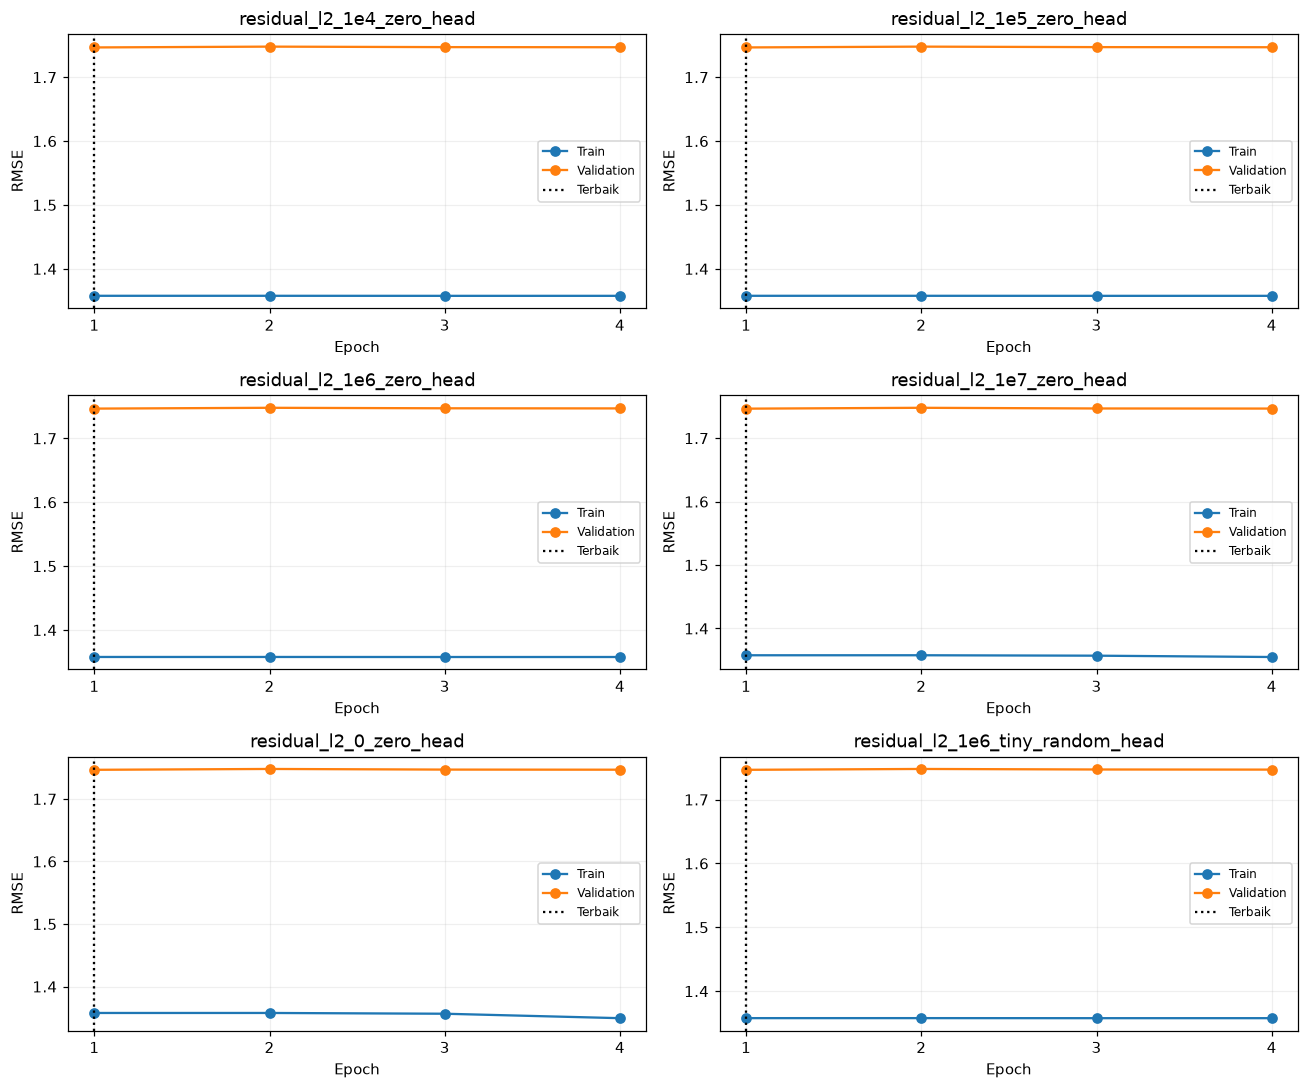

In [13]:
ablation_epochs = pd.DataFrame(
    [
        {
            "percobaan": candidate["name"],
            **record,
            "checkpoint terbaik": record["epoch"] == candidate["best_epoch"],
        }
        for candidate in ablation_neural
        for record in candidate["history"]
    ]
)
with pd.option_context("display.max_rows", None):
    display(ablation_epochs)
assert len(ablation_epochs) == ablation["training"]["total_neural_epochs"]
plot_candidates = [candidate for candidate in ablation_neural if candidate["history"]]
fig, axes = plt.subplots(3, 2, figsize=(12, 10), squeeze=False)
for ax, candidate in zip(axes.flat, plot_candidates):
    frame = pd.DataFrame(candidate["history"])
    ax.plot(frame["epoch"], frame["train_rmse"], "o-", label="Train")
    ax.plot(frame["epoch"], frame["val_rmse"], "o-", label="Validation")
    ax.axvline(candidate["best_epoch"], color="black", linestyle=":", label="Terbaik")
    ax.set(title=candidate["name"], xlabel="Epoch", ylabel="RMSE", xticks=frame["epoch"])
    ax.legend(fontsize=8)
for ax in list(axes.flat)[len(plot_candidates) :]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

### Gradient dan koreksi selama training, bukan hanya satu langkah pertama

Diagnosis dihitung pada sampel train tetap dan seluruh pasangan validation
dengan kedua ID dikenal. Norma gradient **data** dan **L2** dipisahkan untuk
melihat sumber pembaruan bobot. Besarnya norma saja tidak menyatakan arah
gradient atau membuktikan generalisasi. Koreksi adalah tambahan MLP terhadap
baseline bias pada skala rating, sebelum clipping. Standar deviasi koreksi
mengukur variasinya antar-pasangan; variasi besar belum berarti prediksi benar.
Koreksi dihitung sebagai selisih output dan baseline float32, sehingga variasi
sangat kecil mendekati presisi numerik tidak dianggap sinyal personalisasi.
Gradient dan loss diagnosis memakai output mentah pada probe train tetap,
bukan semua rating training. Gradient embedding menjumlahkan indeks berulang
sebelum normanya dihitung; jangan membandingkan angkanya langsung dengan
norma trace historis yang memakai representasi sparse berbeda. Metrik RMSE
per epoch dan hasil validation memakai prediksi yang dipotong ke rentang 1–10.
Head acak kecil hanya mengubah kernel output; backbone dan urutan batch sama.

`initial` adalah kondisi awal, `after_first_update` sesudah satu update,
`epoch_end` sebelum pemulihan bobot, dan `restored_best` checkpoint yang benar
dipakai untuk hasil validation. Tabel lengkap mempertahankan semua tahap.
Pemulihan terbaik hanya mengganti bobot untuk inferensi; counter Adam tetap
menunjukkan epoch terakhir. Checkpoint pemulihan training disimpan terpisah
dengan pasangan bobot dan state optimizer yang sesuai.

**Variasi koreksi pada checkpoint terbaik setiap neural**

,percobaan,tahap,epoch,iterasi optimizer,cohort,pasangan,koreksi mean,koreksi std,koreksi min,koreksi max,validation RMSE,L2,head
0,residual_l2_1e4_zero_head,restored_best,1,440,validation,140,-0.02192277,0.00000134,-0.02192599,-0.02191687,1.74660387,0.0001000,zeros
1,residual_l2_1e5_zero_head,restored_best,1,440,validation,140,-0.02180704,0.00001068,-0.02183747,-0.02177846,1.74660835,0.0000100,zeros
2,residual_l2_1e6_zero_head,restored_best,1,440,validation,140,-0.02174038,0.00026352,-0.02253324,-0.02131927,1.74659913,0.0000010,zeros
3,residual_l2_1e7_zero_head,restored_best,1,440,validation,140,-0.02189718,0.00093520,-0.02450627,-0.02023458,1.74658401,0.0000001,zeros
4,residual_l2_0_zero_head,restored_best,1,440,validation,140,-0.02180504,0.00100437,-0.02467471,-0.02004361,1.74658080,0.0000000,zeros
5,residual_l2_1e6_tiny_random_head,restored_best,1,440,validation,140,-0.02179543,0.00031177,-0.02264804,-0.02123559,1.74659087,0.0000010,normal_std_0.001_seed_2026


**Semua tahap: loss, norma gradient, dan norma embedding**

,percobaan,tahap,epoch,iterasi optimizer,MSE data sampel,jumlah pasangan probe gradient,L2 loss,norma gradient data,norma gradient L2,norma embedding user,norma embedding ISBN,epoch state optimizer
0,bias_only,initial,0,0,0.02495832,1024,0.00000000,0.00000000,0.00000000,14.29158878,8.17639542,NaN
1,bias_plus_train_fitted_scalar,initial,0,0,0.02494112,1024,0.00000000,0.00284177,0.00000000,14.29158878,8.17639542,NaN
2,residual_l2_1e4_zero_head,initial,0,0,0.02495832,1024,0.03305538,0.00351890,0.00363623,14.29158878,8.17639542,NaN
3,residual_l2_1e4_zero_head,after_first_update,0,1,0.02496174,1024,0.03195086,0.00364268,0.00357496,14.01197910,8.01644421,NaN
4,residual_l2_1e4_zero_head,epoch_end,1,110,0.02493006,1024,0.00185086,0.00229249,0.00086043,0.07156433,0.04167815,NaN
5,residual_l2_1e4_zero_head,epoch_end,2,220,0.02496759,1024,0.00051001,0.00382544,0.00045167,0.00061190,0.00072616,NaN
6,residual_l2_1e4_zero_head,epoch_end,3,330,0.02494383,1024,0.00012416,0.00294870,0.00022286,0.00005662,0.00005786,NaN
7,residual_l2_1e4_zero_head,epoch_end,4,440,0.02493859,1024,0.00002677,0.00271731,0.00010347,0.00000723,0.00001097,NaN
8,residual_l2_1e4_zero_head,restored_best,1,440,0.02493006,1024,0.00185086,0.00229249,0.00086043,0.07156433,0.04167815,4.0
9,residual_l2_1e5_zero_head,initial,0,0,0.02495832,1024,0.00330554,0.00351890,0.00036362,14.29158878,8.17639542,NaN


**Sebaran koreksi: sampel train dan validation**

,percobaan,tahap,epoch,iterasi optimizer,cohort,pasangan,koreksi mean,koreksi std,koreksi min,koreksi max
0,bias_only,initial,0,0,train_sample,2048,0.00000000,0.00000000,0.00000000,0.00000000
1,bias_only,initial,0,0,validation,140,0.00000000,0.00000000,0.00000000,0.00000000
2,bias_plus_train_fitted_scalar,initial,0,0,train_sample,2048,-0.01220405,0.00000000,-0.01220405,-0.01220405
3,bias_plus_train_fitted_scalar,initial,0,0,validation,140,-0.01220405,0.00000000,-0.01220405,-0.01220405
4,residual_l2_1e4_zero_head,initial,0,0,train_sample,2048,0.00000000,0.00000000,0.00000000,0.00000000
5,residual_l2_1e4_zero_head,initial,0,0,validation,140,0.00000000,0.00000000,0.00000000,0.00000000
6,residual_l2_1e4_zero_head,after_first_update,0,1,train_sample,2048,0.00223976,0.00010474,0.00185394,0.00265270
7,residual_l2_1e4_zero_head,after_first_update,0,1,validation,140,0.00223006,0.00010522,0.00193602,0.00250626
8,residual_l2_1e4_zero_head,epoch_end,1,110,train_sample,2048,-0.02192267,0.00000141,-0.02192706,-0.02191472
9,residual_l2_1e4_zero_head,epoch_end,1,110,validation,140,-0.02192277,0.00000134,-0.02192599,-0.02191687


**Gradient setiap variabel pada setiap tahap**

,percobaan,tahap,epoch,iterasi optimizer,variabel,norma gradient data,norma gradient L2
0,bias_only,initial,0,0,residual_rating_model/user_embedding/embeddings,0.00000000e+00,0.00000000e+00
1,bias_only,initial,0,0,residual_rating_model/book_embedding/embeddings,0.00000000e+00,0.00000000e+00
2,bias_only,initial,0,0,residual_rating_model/hidden_1/kernel,0.00000000e+00,0.00000000e+00
3,bias_only,initial,0,0,residual_rating_model/hidden_1/bias,0.00000000e+00,0.00000000e+00
4,bias_only,initial,0,0,residual_rating_model/hidden_2/kernel,0.00000000e+00,0.00000000e+00
5,bias_only,initial,0,0,residual_rating_model/hidden_2/bias,0.00000000e+00,0.00000000e+00
6,bias_only,initial,0,0,residual_rating_model/rating_residual/kernel,0.00000000e+00,0.00000000e+00
7,bias_only,initial,0,0,residual_rating_model/rating_residual/bias,0.00000000e+00,0.00000000e+00
8,bias_plus_train_fitted_scalar,initial,0,0,residual_rating_model/user_embedding/embeddings,0.00000000e+00,0.00000000e+00
9,bias_plus_train_fitted_scalar,initial,0,0,residual_rating_model/book_embedding/embeddings,0.00000000e+00,0.00000000e+00


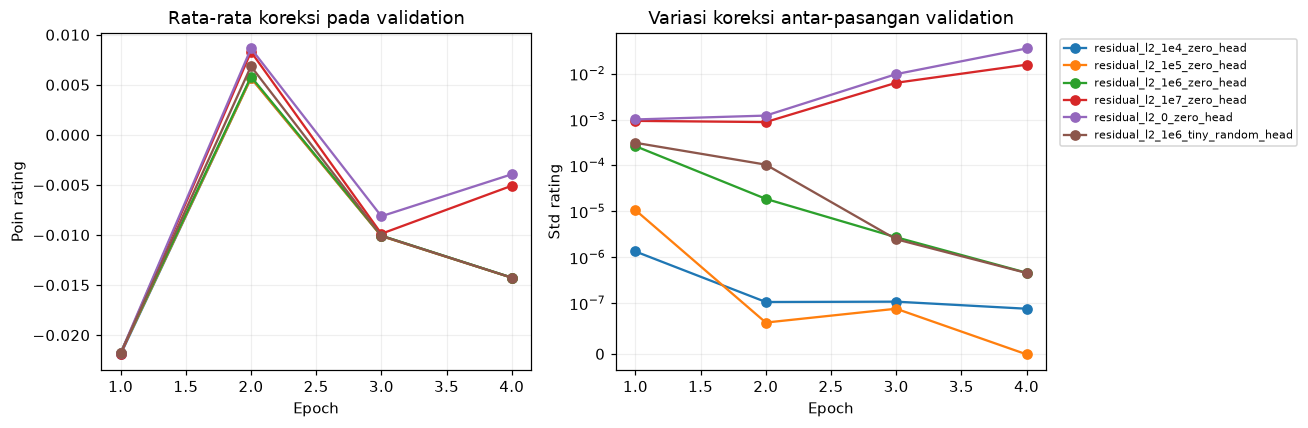

In [14]:
ablation_diagnostic_rows, ablation_gradient_rows, ablation_correction_rows = [], [], []
for candidate in ablation_candidates:
    for diagnostic in candidate.get("diagnostics", []):
        identity = {
            "percobaan": candidate["name"],
            "tahap": diagnostic["stage"],
            "epoch": diagnostic["epoch"],
            "iterasi optimizer": diagnostic.get("optimizer_iterations"),
        }
        gradients = diagnostic.get("gradient_norm_totals", {})
        embedding_norms = diagnostic.get("embedding_norms", {})
        ablation_diagnostic_rows.append(
            {
                **identity,
                "MSE data sampel": diagnostic.get("data_mse"),
                "jumlah pasangan probe gradient": diagnostic.get("gradient_probe_pairs"),
                "L2 loss": diagnostic.get("regularization_loss"),
                "norma gradient data": gradients.get("data"),
                "norma gradient L2": gradients.get("l2"),
                "norma embedding user": embedding_norms.get("user_l2"),
                "norma embedding ISBN": embedding_norms.get("book_l2"),
                "epoch state optimizer": diagnostic.get("optimizer_state_epoch"),
            }
        )
        for variable, gradient in diagnostic.get("gradient_norms", {}).items():
            ablation_gradient_rows.append(
                {
                    **identity,
                    "variabel": variable,
                    "norma gradient data": gradient["data"],
                    "norma gradient L2": gradient["l2"],
                }
            )
        for cohort, correction in diagnostic.get("corrections", {}).items():
            ablation_correction_rows.append(
                {
                    **identity,
                    "cohort": cohort,
                    "pasangan": correction["pairs"],
                    "koreksi mean": correction["mean_rating"],
                    "koreksi std": correction["std_rating"],
                    "koreksi min": correction["min_rating"],
                    "koreksi max": correction["max_rating"],
                }
            )

ablation_diagnostics = pd.DataFrame(ablation_diagnostic_rows)
ablation_corrections = pd.DataFrame(ablation_correction_rows)
display(Markdown("**Variasi koreksi pada checkpoint terbaik setiap neural**"))
display(
    ablation_corrections[
        (ablation_corrections["tahap"] == "restored_best")
        & (ablation_corrections["cohort"] == "validation")
    ].merge(
        ablation_experiments[["percobaan", "validation RMSE", "L2", "head"]],
        on="percobaan",
        validate="one_to_one",
    )
)
with pd.option_context("display.max_rows", None):
    display(Markdown("**Semua tahap: loss, norma gradient, dan norma embedding**"))
    display(ablation_diagnostics)
    display(Markdown("**Sebaran koreksi: sampel train dan validation**"))
    display(ablation_corrections)
    display(Markdown("**Gradient setiap variabel pada setiap tahap**"))
    display(pd.DataFrame(ablation_gradient_rows))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, frame in ablation_corrections[
    (ablation_corrections["tahap"] == "epoch_end")
    & (ablation_corrections["cohort"] == "validation")
].groupby("percobaan", sort=False):
    axes[0].plot(frame["epoch"], frame["koreksi mean"], "o-", label=name)
    axes[1].plot(frame["epoch"], frame["koreksi std"], "o-", label=name)
axes[0].set(title="Rata-rata koreksi pada validation", xlabel="Epoch", ylabel="Poin rating")
axes[1].set(title="Variasi koreksi antar-pasangan validation", xlabel="Epoch", ylabel="Std rating")
axes[1].set_yscale("symlog", linthresh=1e-7)
axes[1].legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Overfit mini-batch nyata: diagnosis kapasitas, bukan skor benchmark

Percobaan terpisah mempelajari berulang kali satu mini-batch train berukuran
128 pasangan tanpa L2. Ia menguji apakah jalur pembelajaran mampu menurunkan
loss pada data yang dilihat berulang. Tidak memakai validation untuk seleksi,
tidak memakai test, dan tidak dapat dipakai sebagai ukuran rekomendasi pada
pengguna baru. Ukuran model dan optimizer mengikuti konfigurasi diagnosis
yang disimpan; hasilnya dipisah dari delapan kandidat benchmark di atas.

,nilai
status,completed
pairs,128
updates_requested,150
updates_completed,150
l2,0.0
seed,42
subset_seed,2026
purpose,"train-only capacity diagnostic, not a generalization benchmark"
test_used,False
validation_used,False


,update,mse
0,0,0.02676449
1,1,0.02674828
2,25,0.02558182
3,50,0.01781297
4,75,0.00738752
5,100,0.00185910
6,125,0.00031915
7,150,0.00004253


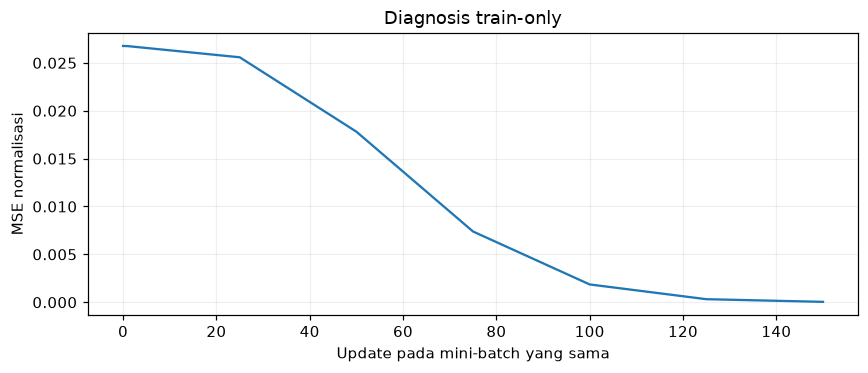

In [15]:
overfit = ablation["small_batch_overfit"]
display(
    pd.json_normalize({key: value for key, value in overfit.items() if key != "history"}).T.rename(
        columns={0: "nilai"}
    )
)
overfit_history = pd.DataFrame(overfit.get("history", []))
with pd.option_context("display.max_rows", None):
    display(overfit_history)
if not overfit_history.empty:
    ax = overfit_history.plot(x="update", y="mse", figsize=(8, 3.5), legend=False)
    ax.set(
        xlabel="Update pada mini-batch yang sama",
        ylabel="MSE normalisasi",
        title="Diagnosis train-only",
    )
    plt.tight_layout()
    plt.show()

## Tindak lanjut adaptif: memberi waktu lebih lama pada residual tanpa L2 kuat

Run keempat diputuskan **setelah** ablation memperlihatkan sinyal mulai tumbuh
pada epoch 3–4, tetapi **sebelum** training tindak lanjut dimulai. Dua kandidat
L2 0 dan 1e-7 diberi 12 epoch tetap tanpa early stopping; faktor lain mengikuti
ablation. Ini perubahan protokol yang disengaja dan dicatat, bukan kandidat
yang sejak awal sudah ditentukan bersama run ketiga.

Tujuannya menguji apakah patience 3 terlalu cepat menghentikan residual.
Tetap memakai validation pengembangan yang sama, tanpa membuka test, tanpa
evaluasi ranking baru, dan tanpa mengulang diagnosis overfit mini-batch.
Kandidat terbaik dipilih dari seluruh 12 epoch menurut validation. Pemilihan
adaptif ini menambah penggunaan validation; hasilnya bukan konfirmasi independen.

In [16]:
warmup = evidence["warmup"]
warmup_manifest = evidence["warmup_manifest"]
assert warmup["schema_version"] == 1
assert warmup["test_used"] is False
assert warmup["dataset"]["input_bytes_match_original_experiment"]
assert warmup["dataset"]["train_pairs"] == ablation["dataset"]["train_pairs"]
assert warmup["dataset"]["validation_known_pairs"] == ablation["dataset"]["validation_known_pairs"]
assert warmup["configuration"]["early_stopping_enabled"] is False
warmup_candidates = warmup["candidate_validation_results"]
warmup_by_name = {candidate["name"]: candidate for candidate in warmup_candidates}
display(
    pd.DataFrame(
        [
            {
                "run": "Warm-up: 12 epoch tetap",
                "session": warmup_manifest["session_name"],
                "selesai (Asia/Jakarta)": pd.Timestamp(warmup["completed_utc"])
                .tz_convert("Asia/Jakarta")
                .isoformat(),
                "status": warmup["status"],
                "semua kandidat selesai": warmup["all_candidates_completed"],
                "durasi (detik)": warmup["total_seconds"],
                "test digunakan": warmup["test_used"],
                "arsip terverifikasi": len(warmup_manifest["backups"]),
                "runtime dihentikan": warmup_manifest["shutdown"]["stopped"],
            }
        ]
    )
)
warmup_rows, trajectory_comparisons = [], []
for candidate in warmup_candidates:
    previous = next(
        c
        for c in ablation_neural
        if c["l2"] == candidate["l2"]
        and c["head_initialization"] == candidate["head_initialization"]
    )
    warmup_rows.append(
        {
            "percobaan": candidate["name"],
            "status": candidate["status"],
            "L2": candidate["l2"],
            "head": candidate["head_initialization"],
            "epoch selesai": candidate["epochs_completed"],
            "epoch terbaik": candidate["best_epoch"],
            "validation RMSE": candidate["validation"]["rmse_rating_scale"],
            "validation MAE": candidate["validation"]["mae_rating_scale"],
            "train RMSE epoch terakhir": candidate["history"][-1]["train_rmse"],
            "validation RMSE epoch terakhir": candidate["history"][-1]["val_rmse"],
            "RMSE terbaik ablation 4 epoch": previous["validation"]["rmse_rating_scale"],
            "selisih dari run 4 epoch": candidate["validation"]["rmse_rating_scale"]
            - previous["validation"]["rmse_rating_scale"],
            "status test": "tidak dijalankan",
        }
    )
    for old_record, new_record in zip(previous["history"], candidate["history"]):
        assert old_record["epoch"] == new_record["epoch"]
        trajectory_comparisons.append(
            {
                "percobaan": candidate["name"],
                "epoch": new_record["epoch"],
                "selisih train RMSE": new_record["train_rmse"] - old_record["train_rmse"],
                "selisih validation RMSE": new_record["val_rmse"] - old_record["val_rmse"],
            }
        )
warmup_experiments = pd.DataFrame(warmup_rows)
display(warmup_experiments)
display(Markdown("**Pemeriksaan replikasi lintasan epoch 1–4 terhadap ablation**"))
display(pd.DataFrame(trajectory_comparisons))
display(
    Markdown(
        "Konfigurasi, seed, data, dan urutan batch dipertahankan. Lintasan tanpa L2 "
        "direplikasi tepat pada empat epoch awal; kandidat L2 1e-7 memiliki "
        "perbedaan numerik kecil sesudah epoch 1 seperti terlihat di tabel. "
        "Operasi GPU tidak dipaksa deterministik secara ketat; penyebab detail "
        "selisih belum diisolasi. Jangan menyebut kedua lintasan identik bit demi bit."
    )
)
display(Markdown("**Konfigurasi lengkap dan kriteria seleksi warm-up**"))
display(pd.json_normalize(warmup["configuration"]).T.rename(columns={0: "nilai"}))
display(pd.json_normalize(warmup["selection"]).T.rename(columns={0: "nilai"}))

,run,session,selesai (Asia/Jakarta),status,semua kandidat selesai,durasi (detik),test digunakan,arsip terverifikasi,runtime dihentikan
0,Warm-up: 12 epoch tetap,book-recommendation-neural-20261014-ablation,2026-10-14T03:35:48.066345+07:00,completed,True,62.95280503,False,11,True


,percobaan,status,L2,head,epoch selesai,epoch terbaik,validation RMSE,validation MAE,train RMSE epoch terakhir,validation RMSE epoch terakhir,RMSE terbaik ablation 4 epoch,selisih dari run 4 epoch,status test
0,residual_l2_0_zero_head_fixed12,completed,0.0000000,zeros,12,1,1.74658080,1.29086509,0.66779303,2.09856087,1.74658080,0.0,tidak dijalankan
1,residual_l2_1e7_zero_head_fixed12,completed,0.0000001,zeros,12,1,1.74658401,1.29087539,0.78339292,2.11149474,1.74658401,0.0,tidak dijalankan


**Pemeriksaan replikasi lintasan epoch 1–4 terhadap ablation**

,percobaan,epoch,selisih train RMSE,selisih validation RMSE
0,residual_l2_0_zero_head_fixed12,1,0.00000000,0.00000000
1,residual_l2_0_zero_head_fixed12,2,0.00000000,0.00000000
2,residual_l2_0_zero_head_fixed12,3,0.00000000,0.00000000
3,residual_l2_0_zero_head_fixed12,4,0.00000000,0.00000000
4,residual_l2_1e7_zero_head_fixed12,1,0.00000000,0.00000000
5,residual_l2_1e7_zero_head_fixed12,2,0.00000150,0.00000958
6,residual_l2_1e7_zero_head_fixed12,3,0.00000834,0.00003291
7,residual_l2_1e7_zero_head_fixed12,4,-0.00011391,0.00000363


Konfigurasi, seed, data, dan urutan batch dipertahankan. Lintasan tanpa L2 direplikasi tepat pada empat epoch awal; kandidat L2 1e-7 memiliki perbedaan numerik kecil sesudah epoch 1 seperti terlihat di tabel. Operasi GPU tidak dipaksa deterministik secara ketat; penyebab detail selisih belum diisolasi. Jangan menyebut kedua lintasan identik bit demi bit.

**Konfigurasi lengkap dan kriteria seleksi warm-up**

,nilai
started_utc,2026-10-13T20:34:45.113564+00:00
preset,warmup
candidates,"[{'name': 'residual_l2_0_zero_head_fixed12', 'kind': 'neural', 'l2': 0.0, 'head_initia..."
candidate_count,2
max_neural_epochs_each,12
min_neural_epochs_each,12
patience,12
early_stopping_enabled,False
snapshot_interval_epochs,4
rationale,Adaptive followup after observing delayed signal at epoch 3–4 in ablation; decided 12 ...


,nilai
selected_utc,2026-10-13T20:35:48.063362+00:00
metric,known_validation_rmse_rating_scale
best_candidate,residual_l2_0_zero_head_fixed12
best_neural_candidate,residual_l2_0_zero_head_fixed12
completed_candidates,2
declared_candidates,2
test_used,False
model_promotion_to_application,False
scope,Diagnostic candidate ranking on the existing development validation only
validation.pairs,140


### Seluruh 12 epoch, termasuk yang kalah dari checkpoint terbaik

Garis vertikal abu-abu menandai batas epoch 4 pada run ablation sebelumnya.
Garis hitam menandai checkpoint terbaik dalam run 12 epoch. Menggunakan
checkpoint terbaik menghindari menyamakan bobot terakhir dengan hasil terbaik.

,percobaan,epoch,train_mse,train_rmse,val_mse,val_rmse,checkpoint terbaik
0,residual_l2_0_zero_head_fixed12,1,0.02276027,1.35778560,0.03766104,1.74658078,True
1,residual_l2_0_zero_head_fixed12,2,0.02276068,1.35779793,0.03771943,1.74793421,False
2,residual_l2_0_zero_head_fixed12,3,0.02271951,1.35656926,0.03767605,1.74692886,False
3,residual_l2_0_zero_head_fixed12,4,0.02248208,1.34946242,0.03766872,1.74675889,False
4,residual_l2_0_zero_head_fixed12,5,0.02114410,1.30869109,0.03861073,1.76846520,False
5,residual_l2_0_zero_head_fixed12,6,0.01907561,1.24303020,0.04077214,1.81729011,False
6,residual_l2_0_zero_head_fixed12,7,0.01620053,1.14553183,0.04381122,1.88380171,False
7,residual_l2_0_zero_head_fixed12,8,0.01302035,1.02696068,0.04789054,1.96955159,False
8,residual_l2_0_zero_head_fixed12,9,0.01039501,0.91760346,0.05123324,2.03712839,False
9,residual_l2_0_zero_head_fixed12,10,0.00821594,0.81577643,0.05318416,2.07555212,False


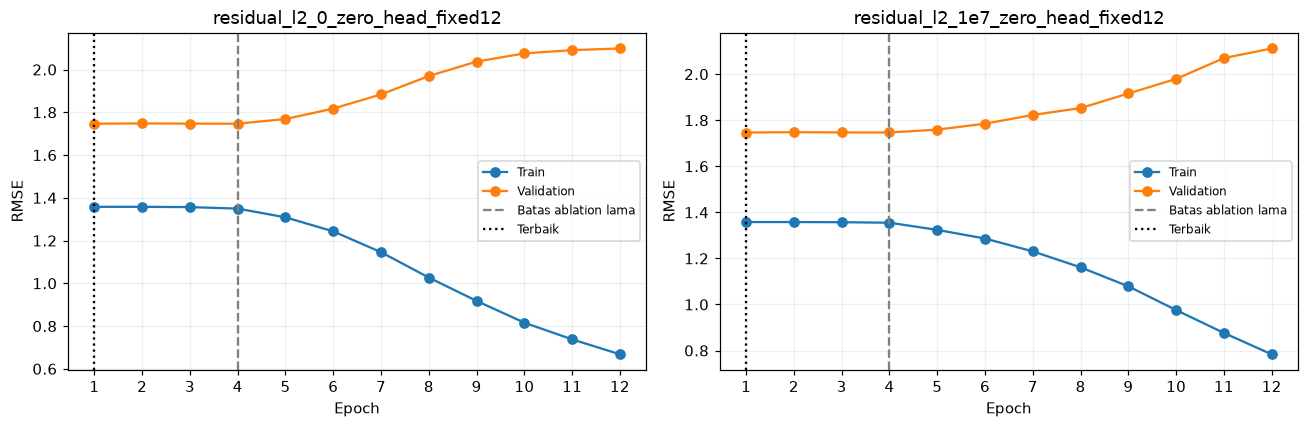

In [17]:
warmup_epochs = pd.DataFrame(
    [
        {
            "percobaan": candidate["name"],
            **record,
            "checkpoint terbaik": record["epoch"] == candidate["best_epoch"],
        }
        for candidate in warmup_candidates
        for record in candidate["history"]
    ]
)
display(warmup_epochs)
assert len(warmup_epochs) == warmup["training"]["total_neural_epochs"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), squeeze=False)
for ax, candidate in zip(axes.flat, warmup_candidates, strict=True):
    frame = pd.DataFrame(candidate["history"])
    ax.plot(frame["epoch"], frame["train_rmse"], "o-", label="Train")
    ax.plot(frame["epoch"], frame["val_rmse"], "o-", label="Validation")
    ax.axvline(4, color="gray", linestyle="--", label="Batas ablation lama")
    ax.axvline(candidate["best_epoch"], color="black", linestyle=":", label="Terbaik")
    ax.set(title=candidate["name"], xlabel="Epoch", ylabel="RMSE", xticks=frame["epoch"])
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Mekanisme pada warm-up: gradient, embedding, dan variasi koreksi

Definisi diagnosis sama dengan run ablation: gradient dari probe train tetap,
koreksi sebelum clipping, serta checkpoint terbaik untuk inferensi. Seluruh
tahap disimpan agar perubahan setelah epoch 4 tetap dapat diperiksa.

**Koreksi pada checkpoint terbaik**

,percobaan,tahap,epoch,iterasi optimizer,cohort,pasangan,koreksi mean,koreksi std,koreksi min,koreksi max,validation RMSE,L2
0,residual_l2_0_zero_head_fixed12,restored_best,1,1320,validation,140,-0.02180504,0.00100437,-0.02467471,-0.02004361,1.74658080,0.0000000
1,residual_l2_1e7_zero_head_fixed12,restored_best,1,1320,validation,140,-0.02189718,0.00093520,-0.02450627,-0.02023458,1.74658401,0.0000001


**Loss, norma gradient, dan embedding: semua tahap**

,percobaan,tahap,epoch,iterasi optimizer,MSE data sampel,L2 loss,norma gradient data,norma gradient L2,norma embedding user,norma embedding ISBN,epoch state optimizer
0,residual_l2_0_zero_head_fixed12,initial,0,0,0.02495832,0.00000000,0.00351890,0.00000000,14.29158878,8.17639542,NaN
1,residual_l2_0_zero_head_fixed12,after_first_update,0,1,0.02496173,0.00000000,0.00364316,0.00000000,14.29158878,8.17639542,NaN
2,residual_l2_0_zero_head_fixed12,epoch_end,1,110,0.02492804,0.00000000,0.00230328,0.00000000,14.29323959,8.18260098,NaN
3,residual_l2_0_zero_head_fixed12,epoch_end,2,220,0.02497083,0.00000000,0.00399505,0.00000000,14.31097603,8.23781300,NaN
4,residual_l2_0_zero_head_fixed12,epoch_end,3,330,0.02489339,0.00000000,0.00315413,0.00000000,14.47195339,8.68856144,NaN
5,residual_l2_0_zero_head_fixed12,epoch_end,4,440,0.02458787,0.00000000,0.00419122,0.00000000,15.56741428,10.32699966,NaN
6,residual_l2_0_zero_head_fixed12,epoch_end,5,550,0.02298165,0.00000000,0.00565439,0.00000000,17.69709015,11.83790588,NaN
7,residual_l2_0_zero_head_fixed12,epoch_end,6,660,0.02058660,0.00000000,0.01033323,0.00000000,20.13237000,13.59255314,NaN
8,residual_l2_0_zero_head_fixed12,epoch_end,7,770,0.01718771,0.00000000,0.02028681,0.00000000,22.53057098,15.19438457,NaN
9,residual_l2_0_zero_head_fixed12,epoch_end,8,880,0.01399568,0.00000000,0.01068574,0.00000000,24.43894768,16.47725487,NaN


**Sebaran koreksi: semua tahap**

,percobaan,tahap,epoch,iterasi optimizer,cohort,pasangan,koreksi mean,koreksi std,koreksi min,koreksi max
0,residual_l2_0_zero_head_fixed12,initial,0,0,train_sample,2048,0.00000000,0.00000000,0.00000000,0.00000000
1,residual_l2_0_zero_head_fixed12,initial,0,0,validation,140,0.00000000,0.00000000,0.00000000,0.00000000
2,residual_l2_0_zero_head_fixed12,after_first_update,0,1,train_sample,2048,0.00223972,0.00010775,0.00184268,0.00266451
3,residual_l2_0_zero_head_fixed12,after_first_update,0,1,validation,140,0.00222974,0.00010831,0.00192690,0.00251377
4,residual_l2_0_zero_head_fixed12,epoch_end,1,110,train_sample,2048,-0.02186600,0.00104386,-0.02625883,-0.01999533
5,residual_l2_0_zero_head_fixed12,epoch_end,1,110,validation,140,-0.02180504,0.00100437,-0.02467471,-0.02004361
6,residual_l2_0_zero_head_fixed12,epoch_end,2,220,train_sample,2048,0.00863716,0.00118725,0.00304270,0.01254201
7,residual_l2_0_zero_head_fixed12,epoch_end,2,220,validation,140,0.00863291,0.00121879,0.00530541,0.01171213
8,residual_l2_0_zero_head_fixed12,epoch_end,3,330,train_sample,2048,-0.00889637,0.01074848,-0.06559610,0.00628603
9,residual_l2_0_zero_head_fixed12,epoch_end,3,330,validation,140,-0.00812898,0.00974354,-0.04892188,0.00329000


**Gradient setiap variabel: semua tahap**

,percobaan,tahap,epoch,iterasi optimizer,variabel,norma gradient data,norma gradient L2
0,residual_l2_0_zero_head_fixed12,initial,0,0,residual_rating_model/user_embedding/embeddings,0.00000000,0.00000000
1,residual_l2_0_zero_head_fixed12,initial,0,0,residual_rating_model/book_embedding/embeddings,0.00000000,0.00000000
2,residual_l2_0_zero_head_fixed12,initial,0,0,residual_rating_model/hidden_1/kernel,0.00000000,0.00000000
3,residual_l2_0_zero_head_fixed12,initial,0,0,residual_rating_model/hidden_1/bias,0.00000000,0.00000000
4,residual_l2_0_zero_head_fixed12,initial,0,0,residual_rating_model/hidden_2/kernel,0.00000000,0.00000000
5,residual_l2_0_zero_head_fixed12,initial,0,0,residual_rating_model/hidden_2/bias,0.00000000,0.00000000
6,residual_l2_0_zero_head_fixed12,initial,0,0,residual_rating_model/rating_residual/kernel,0.00025567,0.00000000
7,residual_l2_0_zero_head_fixed12,initial,0,0,residual_rating_model/rating_residual/bias,0.00350960,0.00000000
8,residual_l2_0_zero_head_fixed12,after_first_update,0,1,residual_rating_model/user_embedding/embeddings,0.00000320,0.00000000
9,residual_l2_0_zero_head_fixed12,after_first_update,0,1,residual_rating_model/book_embedding/embeddings,0.00000365,0.00000000


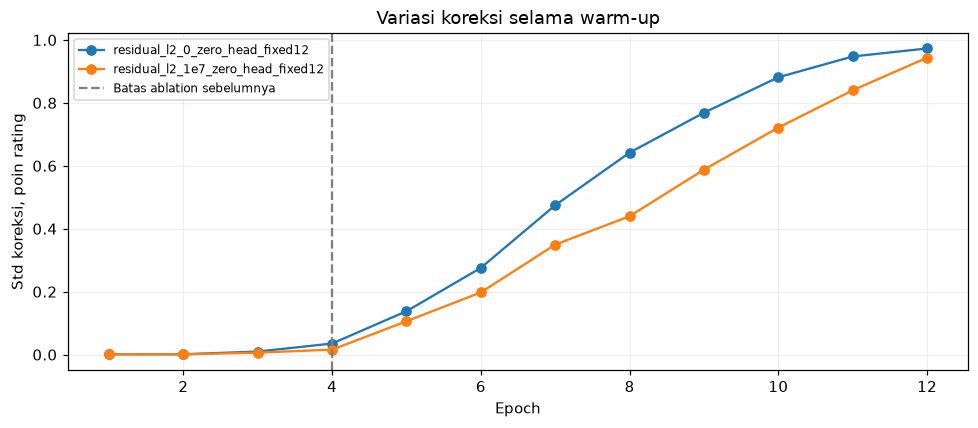

In [18]:
warmup_diagnostic_rows, warmup_correction_rows, warmup_gradient_rows = [], [], []
for candidate in warmup_candidates:
    for diagnostic in candidate["diagnostics"]:
        identity = {
            "percobaan": candidate["name"],
            "tahap": diagnostic["stage"],
            "epoch": diagnostic["epoch"],
            "iterasi optimizer": diagnostic["optimizer_iterations"],
        }
        warmup_diagnostic_rows.append(
            {
                **identity,
                "MSE data sampel": diagnostic["data_mse"],
                "L2 loss": diagnostic["regularization_loss"],
                "norma gradient data": diagnostic["gradient_norm_totals"]["data"],
                "norma gradient L2": diagnostic["gradient_norm_totals"]["l2"],
                "norma embedding user": diagnostic["embedding_norms"]["user_l2"],
                "norma embedding ISBN": diagnostic["embedding_norms"]["book_l2"],
                "epoch state optimizer": diagnostic.get("optimizer_state_epoch"),
            }
        )
        for cohort, correction in diagnostic["corrections"].items():
            warmup_correction_rows.append(
                {
                    **identity,
                    "cohort": cohort,
                    "pasangan": correction["pairs"],
                    "koreksi mean": correction["mean_rating"],
                    "koreksi std": correction["std_rating"],
                    "koreksi min": correction["min_rating"],
                    "koreksi max": correction["max_rating"],
                }
            )
        for variable, gradient in diagnostic["gradient_norms"].items():
            warmup_gradient_rows.append(
                {
                    **identity,
                    "variabel": variable,
                    "norma gradient data": gradient["data"],
                    "norma gradient L2": gradient["l2"],
                }
            )
warmup_corrections = pd.DataFrame(warmup_correction_rows)
display(Markdown("**Koreksi pada checkpoint terbaik**"))
display(
    warmup_corrections[
        (warmup_corrections["tahap"] == "restored_best")
        & (warmup_corrections["cohort"] == "validation")
    ].merge(
        warmup_experiments[["percobaan", "validation RMSE", "L2"]],
        on="percobaan",
        validate="one_to_one",
    )
)
with pd.option_context("display.max_rows", None):
    display(Markdown("**Loss, norma gradient, dan embedding: semua tahap**"))
    display(pd.DataFrame(warmup_diagnostic_rows))
    display(Markdown("**Sebaran koreksi: semua tahap**"))
    display(warmup_corrections)
    display(Markdown("**Gradient setiap variabel: semua tahap**"))
    display(pd.DataFrame(warmup_gradient_rows))
fig, ax = plt.subplots(figsize=(9, 4))
for name, frame in warmup_corrections[
    (warmup_corrections["tahap"] == "epoch_end") & (warmup_corrections["cohort"] == "validation")
].groupby("percobaan", sort=False):
    ax.plot(frame["epoch"], frame["koreksi std"], "o-", label=name)
ax.axvline(4, color="gray", linestyle="--", label="Batas ablation sebelumnya")
ax.set(xlabel="Epoch", ylabel="Std koreksi, poin rating", title="Variasi koreksi selama warm-up")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Run kelima: evaluasi pengembangan internal dengan dua split dan tiga seed

Empat run sebelumnya memperlihatkan batas validation yang hanya memiliki
140 pasangan warm. Run kelima memperluas evaluasi dengan **membagi ulang
train lama**, tanpa membaca CSV validation atau test dari benchmark lama.
Karena sumber train ini sudah pernah dipakai pada eksperimen sebelumnya,
hasilnya adalah **evaluasi pengembangan internal**, bukan test independen baru.
RMSE-nya tidak dibandingkan langsung sebagai perbaikan atas angka benchmark
lama, karena populasi fit dan holdout berbeda.

Pada setiap split seed 17/29, sebanyak 6.000 pengguna yang mempunyai minimal
dua karya dipilih, lalu dibagi menjadi 3.000 pengguna selection dan 3.000
pengguna assessment yang saling terpisah. Satu karya per pengguna ditahan;
**seluruh baris rating untuk semua edisi karya itu** ikut dipindahkan ke
partisi yang sesuai. Setiap pengguna tetap memiliki minimal satu karya dalam
fit. Karena itu satu partisi memiliki tepat 3.000 pengguna, tetapi dapat
memiliki lebih dari 3.000 pasangan rating.

MLP awal dan residual tanpa L2 masing-masing dilatih dengan seed training
42/2026/7 pada kedua split: 12 percobaan neural. Checkpoint memakai selection
saja, maksimal 12 epoch dengan patience 3. **Semua bobot harus dikunci sebelum
assessment pertama dihitung.** Assessment hanya melaporkan hasil seluruh
kandidat; tidak memilih pemenang untuk dipromosikan ke aplikasi.
Seed training mengubah bobot awal **sekaligus urutan mini-batch**. Walaupun
field JSON bernama `initialization_seed`, pengaruhnya bukan inisialisasi saja.

Semua pengguna holdout sudah dikenal dari fit secara sengaja, dan katalog
berasal dari train lama. Cakupan ID yang lebih tinggi pada desain ini tidak
membuktikan masalah cold-start pada benchmark lama sudah teratasi.

In [19]:
multiseed = evidence["multiseed"]
multiseed_manifest = evidence["multiseed_manifest"]
assert multiseed["schema_version"] == 1
assert multiseed["experiment_kind"] == "multiseed_internal_development"
assert multiseed["original_test_used"] is False
assert multiseed["original_validation_used"] is False
assert multiseed["dataset"]["source_pairs"] == audit["train_pairs"]
assert multiseed["selection"]["assessment_used_for_selection"] is False
if multiseed["assessment_performed"]:
    assert multiseed["selection"]["all_weights_locked"]
multiseed_candidates = multiseed["candidate_validation_results"]
multiseed_controls = multiseed["controls"]
multiseed_all_records = [*multiseed_candidates, *multiseed_controls]
multiseed_by_name = {record["name"]: record for record in multiseed_all_records}
selection_by_split = {record["split_seed"]: record for record in multiseed["selection"]["by_split"]}
display(
    pd.DataFrame(
        [
            {
                "run": "Pengembangan internal: 2 split × 3 seed × 2 arsitektur",
                "session": multiseed_manifest["session_name"],
                "selesai (Asia/Jakarta)": pd.Timestamp(multiseed["completed_utc"])
                .tz_convert("Asia/Jakarta")
                .isoformat(),
                "GPU": multiseed["gpu"]["gpu_details"][0]["device_name"],
                "TensorFlow": multiseed["gpu"]["tensorflow_version"],
                "durasi (detik)": multiseed["total_seconds"],
                "status": multiseed["status"],
                "assessment dihitung": multiseed["assessment_performed"],
                "validation lama digunakan": multiseed["original_validation_used"],
                "test lama digunakan": multiseed["original_test_used"],
                "arsip terverifikasi": len(multiseed_manifest["backups"]),
                "runtime dihentikan": multiseed_manifest["shutdown"]["stopped"],
            }
        ]
    )
)
display(Markdown("**Seluruh konfigurasi dan aturan penguncian bobot**"))
display(pd.json_normalize(multiseed["configuration"]).T.rename(columns={0: "nilai"}))
display(pd.json_normalize(multiseed["selection"]).T.rename(columns={0: "nilai"}))
display(Markdown("**Ukuran partisi dan jejak hash pembagian data**"))
display(pd.json_normalize(multiseed["dataset"]["splits"]))
for split in multiseed["dataset"]["splits"]:
    assert split["selection_assessment_users_disjoint"]
    assert split["all_heldout_editions_retained"]
    assert split["all_users_keep_fit_history"]
    assert (
        split["fit_pairs"] + split["selection_pairs"] + split["assessment_pairs"]
        == split["source_pairs"]
    )
split_coverage_rows = []
for split_seed in multiseed["configuration"]["split_seeds"]:
    representative = next(c for c in multiseed_candidates if c["split_seed"] == split_seed)
    for partition in ("selection", "assessment"):
        score = representative.get(partition)
        if not score:
            continue
        known_pairs = score["known_pairs"]["pairs"]
        all_pairs = score["all_pairs"]["pairs"]
        split_coverage_rows.append(
            {
                "split seed": split_seed,
                "partisi": partition,
                "pengguna yang direncanakan": multiseed["configuration"]["users_per_partition"],
                "pasangan seluruhnya": all_pairs,
                "pasangan kedua ID dikenal": known_pairs,
                "cakupan ID (%)": 100 * known_pairs / all_pairs,
                **{f"availability.{key}": value for key, value in score["availability"].items()},
            }
        )
display(Markdown("**Cakupan aktual: jumlah pengguna dan jumlah rating tidak disamakan**"))
multiseed_coverage = pd.DataFrame(split_coverage_rows)
display(multiseed_coverage)
if (
    multiseed_coverage["pasangan kedua ID dikenal"] == multiseed_coverage["pasangan seluruhnya"]
).all():
    display(
        Markdown(
            "**Cakupan aktual 100% warm pada kedua partisi/kedua split.** "
            "Fallback tidak digunakan pada run ini; metrik known/full sama karena "
            "baris evaluasinya sama. Ini akibat desain holdout serta data yang tersisa "
            "di fit, bukan bukti solusi cold-start."
        )
    )

,run,session,selesai (Asia/Jakarta),GPU,TensorFlow,durasi (detik),status,assessment dihitung,validation lama digunakan,test lama digunakan,arsip terverifikasi,runtime dihentikan
0,Pengembangan internal: 2 split × 3 seed × 2 arsitektur,book-recommendation-neural-20261014-multiseed,2026-10-14T04:04:13.934208+07:00,Tesla T4,2.21.0,203.8795695,completed,True,False,False,31,True


**Seluruh konfigurasi dan aturan penguncian bobot**

,nilai
started_utc,2026-10-13T21:00:50.054673+00:00
candidates,"[{'name': 'split17_mlp_seed42', 'kind': 'neural', 'split_seed': 17, 'initialization_se..."
candidate_count,12
split_seeds,"[17, 29]"
initialization_seeds,"[42, 2026, 7]"
architectures,"[mlp, residual]"
users_per_partition,3000
training_seed_scope,Weight initialization and minibatch shuffle; identical seed paired across architectures
deterministic_operations_requested,True
max_neural_epochs_each,12


,nilai
metric,known_selection_rmse_rating_scale
by_split,"[{'split_seed': 17, 'best_neural_candidate': 'split17_mlp_seed42', 'best_candidate': '..."
all_weights_locked,True
assessment_used_for_selection,False
weights_locked_utc,2026-10-13T21:03:56.444862+00:00


**Ukuran partisi dan jejak hash pembagian data**

,split_seed,eligible_users,source_pairs,fit_pairs,fit_users,fit_isbns,selection_pairs,assessment_pairs,selection_users,assessment_users,selection_works,assessment_works,...,metric_weighting,partition_row_sha256.fit,partition_row_sha256.selection,partition_row_sha256.assessment,partition_file_fingerprints.fit_ratings.csv.sha256,partition_file_fingerprints.fit_ratings.csv.bytes,partition_file_fingerprints.selection_ratings.csv.sha256,partition_file_fingerprints.selection_ratings.csv.bytes,partition_file_fingerprints.assessment_ratings.csv.sha256,partition_file_fingerprints.assessment_ratings.csv.bytes,partition_file_fingerprints.membership.json.sha256,partition_file_fingerprints.membership.json.bytes
0,17,15312,111875,105871,15312,5000,3002,3002,3000,3000,3000,3000,...,Rating-pair weighted; repeated editions remain in the same user cluster,d43058aa89dcdfdad2c56bc37144cdcd040af2742d855355eb55dc58f4a0c584,676c80ab221af8a26c3c042aa86b4f05883f4c1e518c2370d8bcf0944261995d,bc7612ffc5bde945db8cdc0f16367db99324c08ac028224e9f1c72de6ce51c05,ac5ace4bda3ef7eb78c6f0dd98fc0e554a4c3c2e2c6e2a98c2f48c66da6b56f6,8652307,0a57eb20b686e06004fb6f2946036907c7c3b37d41da3bdb58e0051b67f3dac4,247281,2fe5dff4f1be39f7e5aa0f9dd4ac2607b1a884958dc10a572298bb8926bbf6a0,247211,67f6abe3f0abf2cb6a3d7da465fa82626b158010eebe840ffa844aa2ff0ee890,807927
1,29,15312,111875,105869,15312,5000,3001,3005,3000,3000,3000,3000,...,Rating-pair weighted; repeated editions remain in the same user cluster,345c052b8afbe4bae9957f89349b3656a92229194068554c0c4f7e9accb2f20b,d40504116cf2b077efdd40eee5236ac1e45b9e5d84955f779138f50932adc015,41f45dc8327240eaedf8b4204ffcd4c6d6f1275bd406ac2210e84532bee0c687,ec8b9bab0a794f6199a1d12736fbc149be3996ce3f750ca895171aed4c433edc,8655086,26e7f0a2cb482fdcf57b5576c07b127e13615d9340fa79d9cb7e3ae1133909c3,245283,8c9bd6fb798cdf15b41beb1fad240c85edc3e45b204f66ac0b24b2a459c504ae,246430,0111f6e4c1d64a0cfc4f97c7a7bbd6ea118f0e57f5b2c42918b2af52fc1e7cda,804948


**Cakupan aktual: jumlah pengguna dan jumlah rating tidak disamakan**

,split seed,partisi,pengguna yang direncanakan,pasangan seluruhnya,pasangan kedua ID dikenal,cakupan ID (%),availability.both_known,availability.known_user_unknown_isbn,availability.unknown_user_known_isbn,availability.both_unknown
0,17,selection,3000,3002,3002,100.0,3002,0,0,0
1,17,assessment,3000,3002,3002,100.0,3002,0,0,0
2,29,selection,3000,3001,3001,100.0,3001,0,0,0
3,29,assessment,3000,3005,3005,100.0,3005,0,0,0


**Cakupan aktual 100% warm pada kedua partisi/kedua split.** Fallback tidak digunakan pada run ini; metrik known/full sama karena baris evaluasinya sama. Ini akibat desain holdout serta data yang tersisa di fit, bukan bukti solusi cold-start.

### Semua model, kontrol, dan hasil selection/assessment

Kontrol mean global, mean pengguna, dan bias pengguna + buku dihitung ulang
dari fit masing-masing split. Kolom `known_pairs` memakai pasangan dengan
kedua ID dikenal. Kolom `all_pairs` memakai fallback bersama yang ditentukan
oleh protokol jika terdapat pasangan cold, sehingga cakupan model dapat dibandingkan
pada baris yang sama. Metrik dibobot menurut pasangan rating, bukan rata-rata
dari skor tiap pengguna. Kolom pemenang selection tidak berasal dari assessment.
Fallback bersama adalah mean pengguna fit → mean ISBN fit → mean global fit;
aturan ini juga berlaku pada kontrol untuk baris dengan ID yang tidak dikenal.

,percobaan,jenis,split seed,arsitektur,seed training,L2,status,epoch selesai,epoch terbaik selection,terpilih menurut selection,save/load terverifikasi,durasi (detik),status test independen
0,split17_mlp_seed42,neural,17,mlp,42.0,0.00001,completed,5,2.0,True,True,11.54345066,tidak dijalankan
1,split17_residual_seed42,neural,17,residual,42.0,0.0,completed,7,4.0,False,True,16.18171014,tidak dijalankan
2,split17_mlp_seed2026,neural,17,mlp,2026.0,0.00001,completed,5,2.0,False,True,10.63142343,tidak dijalankan
3,split17_residual_seed2026,neural,17,residual,2026.0,0.0,completed,4,1.0,False,True,11.07249658,tidak dijalankan
4,split17_mlp_seed7,neural,17,mlp,7.0,0.00001,completed,5,2.0,False,True,10.50180951,tidak dijalankan
5,split17_residual_seed7,neural,17,residual,7.0,0.0,completed,7,4.0,False,True,16.18935737,tidak dijalankan
6,split29_mlp_seed42,neural,29,mlp,42.0,0.00001,completed,5,2.0,False,True,10.82174782,tidak dijalankan
7,split29_residual_seed42,neural,29,residual,42.0,0.0,completed,8,5.0,False,True,18.69089536,tidak dijalankan
8,split29_mlp_seed2026,neural,29,mlp,2026.0,0.00001,completed,6,3.0,False,True,12.07013456,tidak dijalankan
9,split29_residual_seed2026,neural,29,residual,2026.0,0.0,completed,9,6.0,False,True,20.45180242,tidak dijalankan


**Identitas checkpoint terpilih yang dikunci sebelum assessment**

,percobaan,file,SHA256
0,split17_mlp_seed42,network.keras,"{'sha256': 'bed36251c13cc6441c272cfb63a562600ab0d0f075ca8e7409ebb4d0b848dd0b', 'bytes'..."
1,split17_mlp_seed42,metadata.json,"{'sha256': 'eec37d347d2ef37d143ee6bbabf7b28d4358d86d1d5d7f2f02695daecc8a50f5', 'bytes'..."
2,split17_residual_seed42,network.keras,"{'sha256': '461f4c2b12c0d26fe5b7653ab7aacff0030d69f3b97ca1008aee2571212d0f5b', 'bytes'..."
3,split17_residual_seed42,metadata.json,"{'sha256': '9e97aea129896fd2d2f97936a86aaf1203b4bb12f0e6a7e1f334dcfea26a27d3', 'bytes'..."
4,split17_mlp_seed2026,network.keras,"{'sha256': '028530546f10de9ff220a87fee610b06774f7a577a4ddfdd9151821dc6e75c51', 'bytes'..."
5,split17_mlp_seed2026,metadata.json,"{'sha256': 'c0de3071be4a8d993dde773448dcd672f5ce86e29597eab3aed1d02a083bad9d', 'bytes'..."
6,split17_residual_seed2026,network.keras,"{'sha256': 'ced562000bdbd599bb88ae94cb38a80211383d68e81c2786e473948044716967', 'bytes'..."
7,split17_residual_seed2026,metadata.json,"{'sha256': 'b666035bde3b94c1ed7bb323184e617d9dafd89cf276e7ffb1a29b86e201cfd0', 'bytes'..."
8,split17_mlp_seed7,network.keras,"{'sha256': '4d3e8d0512166cec41d24c461d0cfebffd253a59bad327858fb17479d775d5fd', 'bytes'..."
9,split17_mlp_seed7,metadata.json,"{'sha256': '5bf2cb28848d771d1a8d3b2448c9d6d76b68cdd4c496e73b645bed7e8f02af44', 'bytes'..."


,percobaan,split seed,arsitektur,seed training,partisi,cohort,pasangan,RMSE,MAE
0,split17_mlp_seed42,17,mlp,42.0,selection,known_pairs,3002,1.61872495,1.27058278
1,split17_mlp_seed42,17,mlp,42.0,selection,all_pairs,3002,1.61872495,1.27058278
2,split17_mlp_seed42,17,mlp,42.0,assessment,known_pairs,3002,1.62709962,1.27862257
3,split17_mlp_seed42,17,mlp,42.0,assessment,all_pairs,3002,1.62709962,1.27862257
4,split17_residual_seed42,17,residual,42.0,selection,known_pairs,3002,1.86324691,1.38199346
5,split17_residual_seed42,17,residual,42.0,selection,all_pairs,3002,1.86324691,1.38199346
6,split17_residual_seed42,17,residual,42.0,assessment,known_pairs,3002,1.91673130,1.41346018
7,split17_residual_seed42,17,residual,42.0,assessment,all_pairs,3002,1.91673130,1.41346018
8,split17_mlp_seed2026,17,mlp,2026.0,selection,known_pairs,3002,1.62801262,1.28433197
9,split17_mlp_seed2026,17,mlp,2026.0,selection,all_pairs,3002,1.62801262,1.28433197


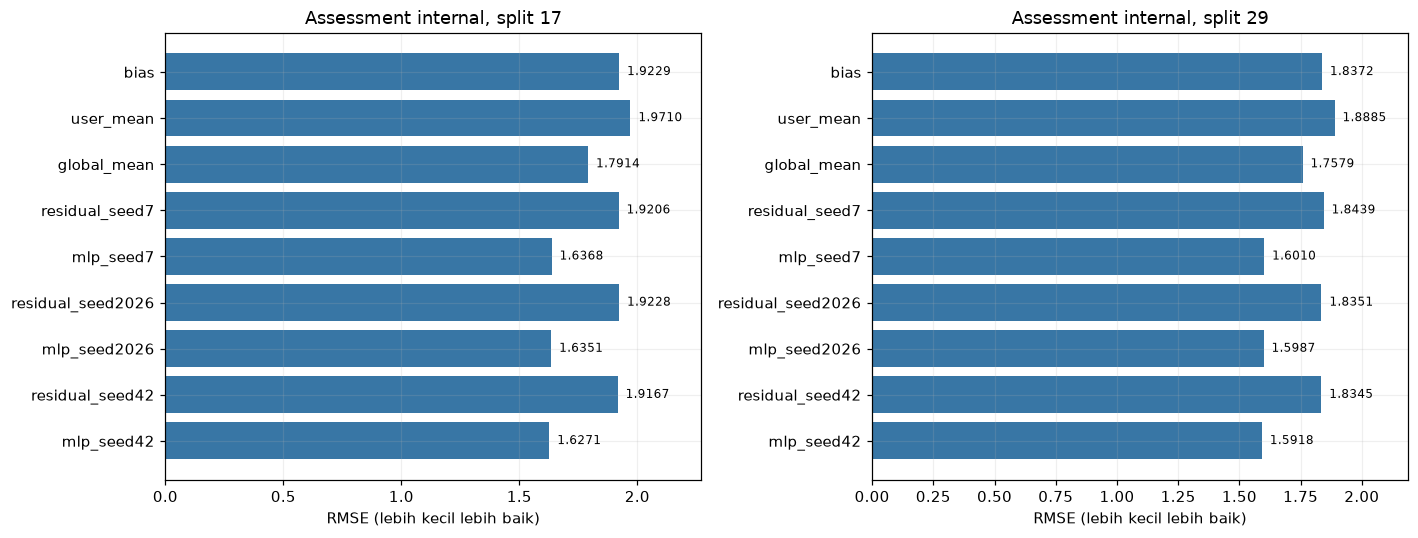

In [20]:
multiseed_record_rows, multiseed_metric_rows = [], []
for record in multiseed_all_records:
    is_neural = record["kind"] == "neural"
    split_selection = selection_by_split[record["split_seed"]]
    multiseed_record_rows.append(
        {
            "percobaan": record["name"],
            "jenis": record["kind"],
            "split seed": record["split_seed"],
            "arsitektur": record.get("architecture", "kontrol"),
            "seed training": record.get("initialization_seed"),
            "L2": record.get("l2") if is_neural else None,
            "status": record.get("status", "kontrol tersedia"),
            "epoch selesai": record.get("epochs_completed", 0),
            "epoch terbaik selection": record.get("best_epoch"),
            "terpilih menurut selection": record["name"] == split_selection["best_candidate"],
            "save/load terverifikasi": record.get("model_roundtrip_verified"),
            "durasi (detik)": record.get("seconds"),
            "status test independen": "tidak dijalankan",
        }
    )
    for partition in ("selection", "assessment"):
        score = record.get(partition)
        if not score:
            continue
        for scope in ("known_pairs", "all_pairs"):
            metric = score[scope]
            multiseed_metric_rows.append(
                {
                    "percobaan": record["name"],
                    "split seed": record["split_seed"],
                    "arsitektur": record.get("architecture", "kontrol"),
                    "seed training": record.get("initialization_seed"),
                    "partisi": partition,
                    "cohort": scope,
                    "pasangan": metric["pairs"],
                    "RMSE": metric["rmse_rating_scale"],
                    "MAE": metric["mae_rating_scale"],
                }
            )
multiseed_experiments = pd.DataFrame(multiseed_record_rows)
multiseed_metrics = pd.DataFrame(multiseed_metric_rows)
display(multiseed_experiments.fillna("—"))
display(Markdown("**Identitas checkpoint terpilih yang dikunci sebelum assessment**"))
display(
    pd.DataFrame(
        [
            {"percobaan": candidate["name"], "file": filename, "SHA256": digest}
            for candidate in multiseed_candidates
            for filename, digest in candidate.get("selected_model_fingerprints", {}).items()
        ]
    )
)
with pd.option_context("display.max_rows", None):
    display(multiseed_metrics)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, split_seed in zip(axes, multiseed["configuration"]["split_seeds"], strict=True):
    frame = multiseed_metrics[
        (multiseed_metrics["split seed"] == split_seed)
        & (multiseed_metrics["partisi"] == "assessment")
        & (multiseed_metrics["cohort"] == "known_pairs")
    ]
    labels = frame["percobaan"].str.replace(f"split{split_seed}_", "", regex=False)
    ax.barh(labels, frame["RMSE"], color="#3876a5")
    for index, value in enumerate(frame["RMSE"]):
        ax.text(value, index, f"  {value:.4f}", va="center", fontsize=8)
    ax.set(title=f"Assessment internal, split {split_seed}", xlabel="RMSE (lebih kecil lebih baik)")
    if not frame.empty:
        ax.set_xlim(0, frame["RMSE"].max() + 0.3)
plt.tight_layout()
plt.show()

### Seluruh epoch pada semua 12 training, tanpa menyembunyikan variasi seed

Validation pada history adalah **selection**, bukan assessment. Tidak ada
kurva assessment per epoch karena assessment baru dibuka sesudah seluruh
bobot kandidat terkunci. Garis putus-putus menunjukkan checkpoint selection
terbaik yang dipakai saat penilaian akhir.

,percobaan,split seed,arsitektur,seed training,epoch,train_mse,train_rmse,val_mse,val_rmse,checkpoint terbaik selection
0,split17_mlp_seed42,17,mlp,42,1,0.03090787,1.58225706,0.03484777,1.68008016,False
1,split17_mlp_seed42,17,mlp,42,2,0.02418789,1.39972115,0.03234902,1.61872491,True
2,split17_mlp_seed42,17,mlp,42,3,0.02258044,1.35241102,0.03291088,1.63272195,False
3,split17_mlp_seed42,17,mlp,42,4,0.02206284,1.33682087,0.03311598,1.63780177,False
4,split17_mlp_seed42,17,mlp,42,5,0.02165763,1.32448780,0.03415346,1.66325896,False
5,split17_residual_seed42,17,residual,42,1,0.02250290,1.35008714,0.04298299,1.86591051,False
6,split17_residual_seed42,17,residual,42,2,0.02249655,1.34989648,0.04298795,1.86601813,False
7,split17_residual_seed42,17,residual,42,3,0.02244807,1.34844132,0.04299393,1.86614798,False
8,split17_residual_seed42,17,residual,42,4,0.02195709,1.33361314,0.04286036,1.86324692,True
9,split17_residual_seed42,17,residual,42,5,0.02053300,1.28964074,0.04326768,1.87207966,False


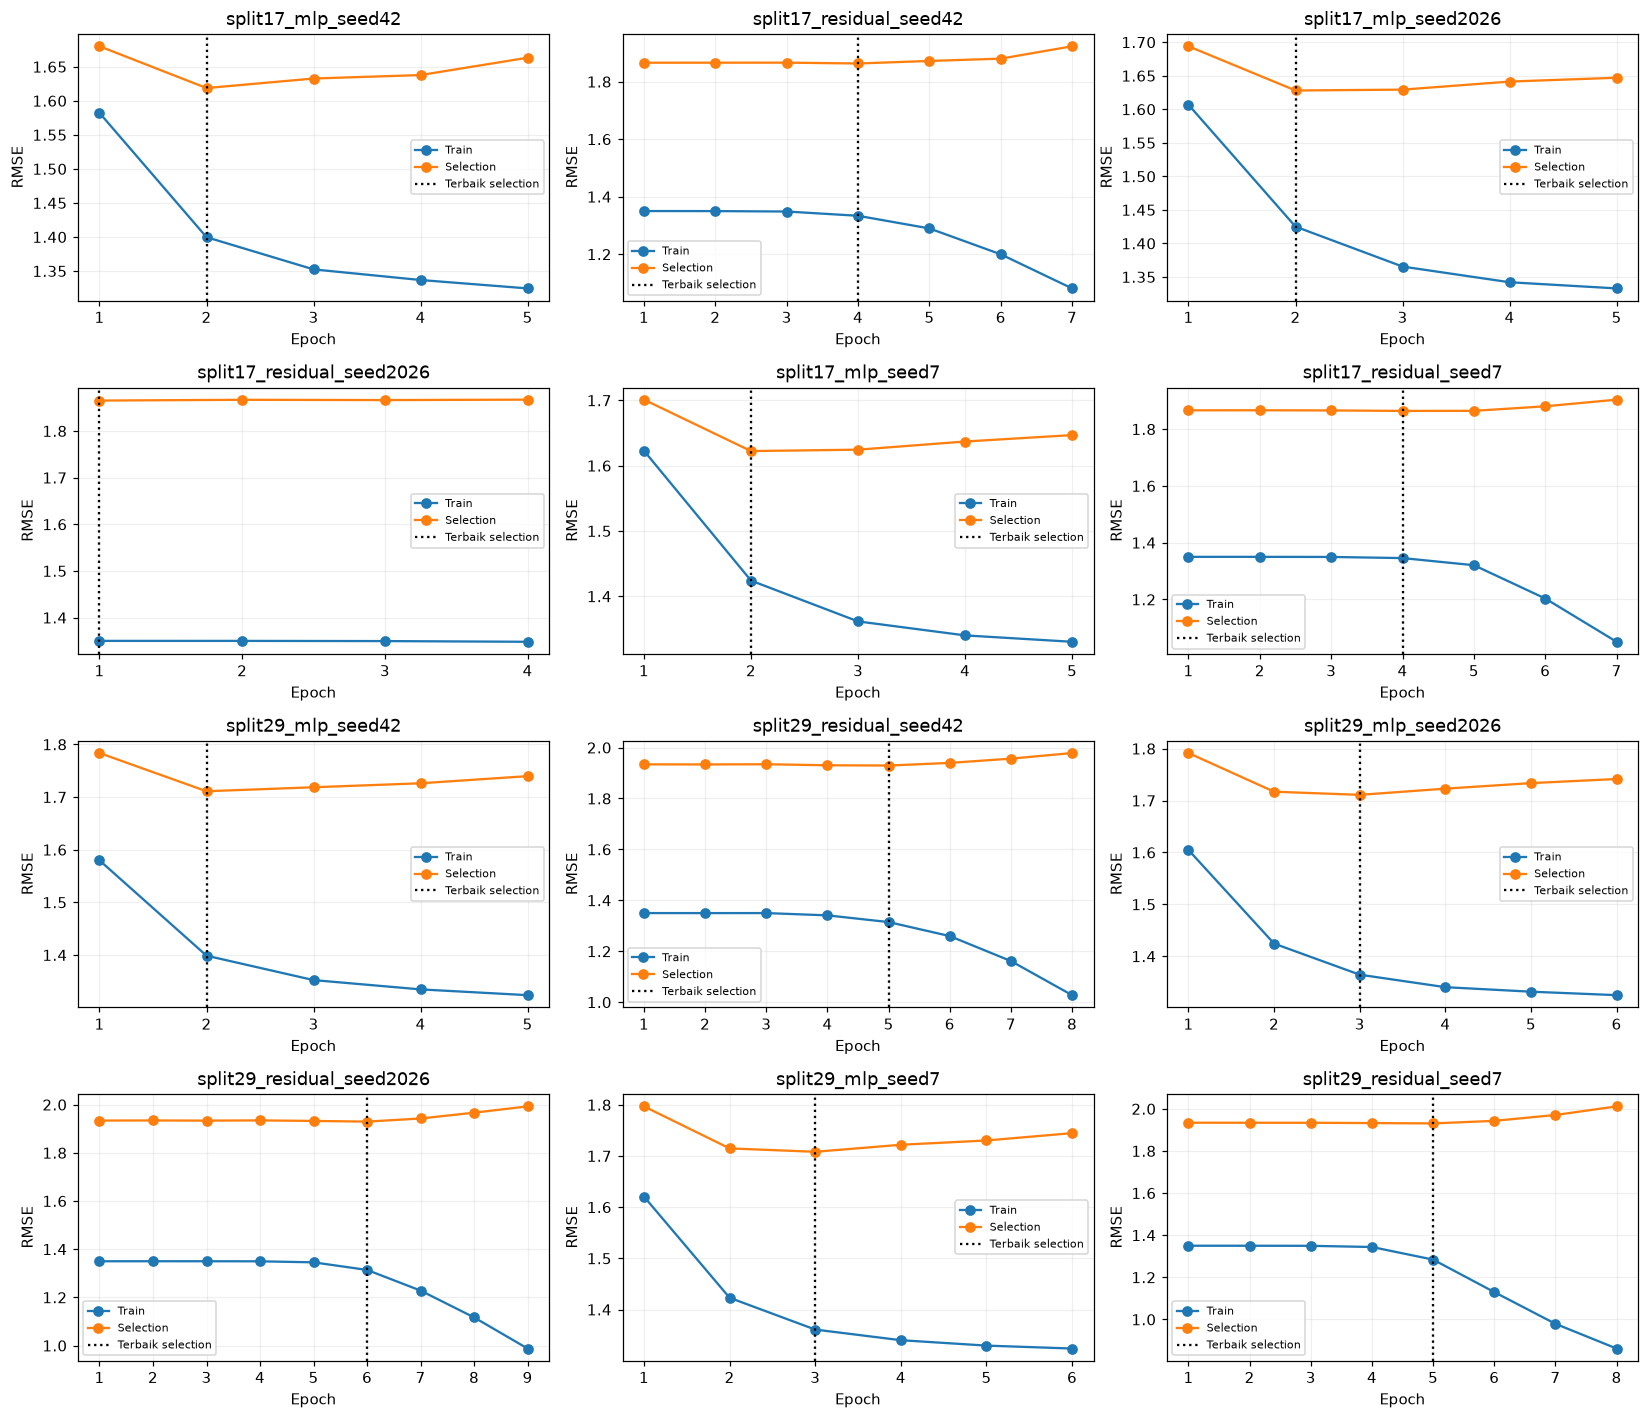

In [21]:
multiseed_epochs = pd.DataFrame(
    [
        {
            "percobaan": candidate["name"],
            "split seed": candidate["split_seed"],
            "arsitektur": candidate["architecture"],
            "seed training": candidate["initialization_seed"],
            **record,
            "checkpoint terbaik selection": record["epoch"] == candidate["best_epoch"],
        }
        for candidate in multiseed_candidates
        for record in candidate["history"]
    ]
)
assert len(multiseed_epochs) == multiseed["training"]["total_neural_epochs"]
with pd.option_context("display.max_rows", None):
    display(multiseed_epochs)
fig, axes = plt.subplots(4, 3, figsize=(15, 13))
for ax, candidate in zip(axes.flat, multiseed_candidates, strict=True):
    frame = pd.DataFrame(candidate["history"])
    ax.plot(frame["epoch"], frame["train_rmse"], "o-", label="Train")
    ax.plot(frame["epoch"], frame["val_rmse"], "o-", label="Selection")
    ax.axvline(candidate["best_epoch"], color="black", linestyle=":", label="Terbaik selection")
    ax.set(title=candidate["name"], xlabel="Epoch", ylabel="RMSE", xticks=frame["epoch"])
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

### Bukti langkah pertama pada setiap training baru

Trace berikut berasal dari update Adam pertama masing-masing dari 12 model.
MSE, penalti L2, dan perubahan embedding menunjukkan bahwa training dijalankan;
nilainya bukan skor assessment. Pada residual head nol, gradient data menuju
embedding pada langkah pertama masih nol. Head dan pembelajaran berikutnya
perlu dibedakan dari efek regularisasi, sebagaimana diagnosis run sebelumnya.

In [22]:
multiseed_trace_rows, multiseed_first_gradients = [], []
for candidate in multiseed_candidates:
    trace = candidate.get("first_step_trace")
    if not trace:
        continue
    multiseed_trace_rows.append(
        {
            "percobaan": candidate["name"],
            "MSE sebelum": trace["mse_before"],
            "L2 loss": trace["regularization_loss"],
            "total loss sebelum": trace["total_loss_before"],
            "MSE setelah": trace["mse_after"],
            "norma perubahan embedding": trace["embedding_delta_norm"],
            "gradient data embedding sebelum": trace.get(
                "embedding_data_gradient_norm_before", "tidak dipisah dalam trace"
            ),
            "iterasi optimizer": trace["optimizer_iterations"],
        }
    )
    multiseed_first_gradients.extend(
        {"percobaan": candidate["name"], "variabel": variable, "norma gradient total": norm}
        for variable, norm in trace["gradient_norms"].items()
    )
display(pd.DataFrame(multiseed_trace_rows))
with pd.option_context("display.max_rows", None):
    display(pd.DataFrame(multiseed_first_gradients))

,percobaan,MSE sebelum,L2 loss,total loss sebelum,MSE setelah,norma perubahan embedding,gradient data embedding sebelum,iterasi optimizer
0,split17_mlp_seed42,0.10629756,0.00330554,0.10960310,0.10498908,0.00309570,tidak dipisah dalam trace,1
1,split17_residual_seed42,0.02117023,0.00000000,0.02117023,0.02116765,0.00000000,0.0,1
2,split17_mlp_seed2026,0.10378062,0.00330700,0.10708763,0.10306201,0.00287681,tidak dipisah dalam trace,1
3,split17_residual_seed2026,0.02149665,0.00000000,0.02149665,0.02149532,0.00000000,0.0,1
4,split17_mlp_seed7,0.10472201,0.00330236,0.10802437,0.10375871,0.00302547,tidak dipisah dalam trace,1
5,split17_residual_seed7,0.02392212,0.00000000,0.02392212,0.02391904,0.00000000,0.0,1
6,split29_mlp_seed42,0.10842857,0.00330554,0.11173411,0.10709563,0.00308171,tidak dipisah dalam trace,1
7,split29_residual_seed42,0.02175849,0.00000000,0.02175849,0.02175424,0.00000000,0.0,1
8,split29_mlp_seed2026,0.10378835,0.00330700,0.10709536,0.10307352,0.00348268,tidak dipisah dalam trace,1
9,split29_residual_seed2026,0.01949691,0.00000000,0.01949691,0.01949498,0.00000000,0.0,1


,percobaan,variabel,norma gradient total
0,split17_mlp_seed42,neural_rating_model/user_embedding/embeddings,0.00305073
1,split17_mlp_seed42,neural_rating_model/book_embedding/embeddings,0.00293550
2,split17_mlp_seed42,neural_rating_model/hidden_1/kernel,0.00190384
3,split17_mlp_seed42,neural_rating_model/hidden_1/bias,0.06011293
4,split17_mlp_seed42,neural_rating_model/hidden_2/kernel,0.00667638
5,split17_mlp_seed42,neural_rating_model/hidden_2/bias,0.11150134
6,split17_mlp_seed42,neural_rating_model/rating/kernel,0.00506754
7,split17_mlp_seed42,neural_rating_model/rating/bias,0.13029243
8,split17_residual_seed42,residual_rating_model/user_embedding/embeddings,0.00000000
9,split17_residual_seed42,residual_rating_model/book_embedding/embeddings,0.00000000


### Ketidakpastian: bootstrap kelompok pengguna pada assessment internal

Interval berikut menggunakan 1.000 resampling **pengguna**, mempertahankan
seluruh baris edisi/rating milik pengguna terpilih. Dua model dibandingkan
pada pasangan yang sama. Selisih adalah RMSE kandidat − RMSE referensi:
negatif menguntungkan kandidat. Interval yang melintasi nol belum mendukung
perbedaan yang meyakinkan menurut prosedur ini.

Interval bersyarat pada split dan model yang sudah dilatih; ia bukan interval
atas semua kemungkinan dataset. Banyak kandidat/perbandingan juga diperiksa,
sehingga satu interval tidak boleh dipakai untuk memilih pemenang assessment.
Hasil dua split disajikan terpisah karena sumber data dan pengguna dapat
tumpang tindih; dua split tersebut bukan dua dataset independen.

,split seed,kandidat,referensi,cohort,pasangan,kelompok pengguna,bootstrap draws,selisih RMSE,batas bawah 95%,batas atas 95%,interval melintasi nol,metode
0,17,split17_mlp_seed42,split17_bias,known_pairs,3002,3000,1000,-0.29581724,-0.33756880,-0.25379311,False,Paired percentile bootstrap of users; all rating rows retained within each user
1,17,split17_mlp_seed42,split17_bias,all_pairs,3002,3000,1000,-0.29581724,-0.33756880,-0.25379311,False,Paired percentile bootstrap of users; all rating rows retained within each user
2,17,split17_residual_seed42,split17_bias,known_pairs,3002,3000,1000,-0.00618556,-0.00885620,-0.00348437,False,Paired percentile bootstrap of users; all rating rows retained within each user
3,17,split17_residual_seed42,split17_bias,all_pairs,3002,3000,1000,-0.00618556,-0.00885620,-0.00348437,False,Paired percentile bootstrap of users; all rating rows retained within each user
4,17,split17_residual_seed42,split17_mlp_seed42,known_pairs,3002,3000,1000,0.28963168,0.24754860,0.33202522,False,Paired percentile bootstrap of users; all rating rows retained within each user
5,17,split17_residual_seed42,split17_mlp_seed42,all_pairs,3002,3000,1000,0.28963168,0.24754860,0.33202522,False,Paired percentile bootstrap of users; all rating rows retained within each user
6,17,split17_mlp_seed2026,split17_bias,known_pairs,3002,3000,1000,-0.28783944,-0.33305131,-0.24477451,False,Paired percentile bootstrap of users; all rating rows retained within each user
7,17,split17_mlp_seed2026,split17_bias,all_pairs,3002,3000,1000,-0.28783944,-0.33305131,-0.24477451,False,Paired percentile bootstrap of users; all rating rows retained within each user
8,17,split17_residual_seed2026,split17_bias,known_pairs,3002,3000,1000,-0.00016274,-0.00032312,-0.00000937,False,Paired percentile bootstrap of users; all rating rows retained within each user
9,17,split17_residual_seed2026,split17_bias,all_pairs,3002,3000,1000,-0.00016274,-0.00032312,-0.00000937,False,Paired percentile bootstrap of users; all rating rows retained within each user


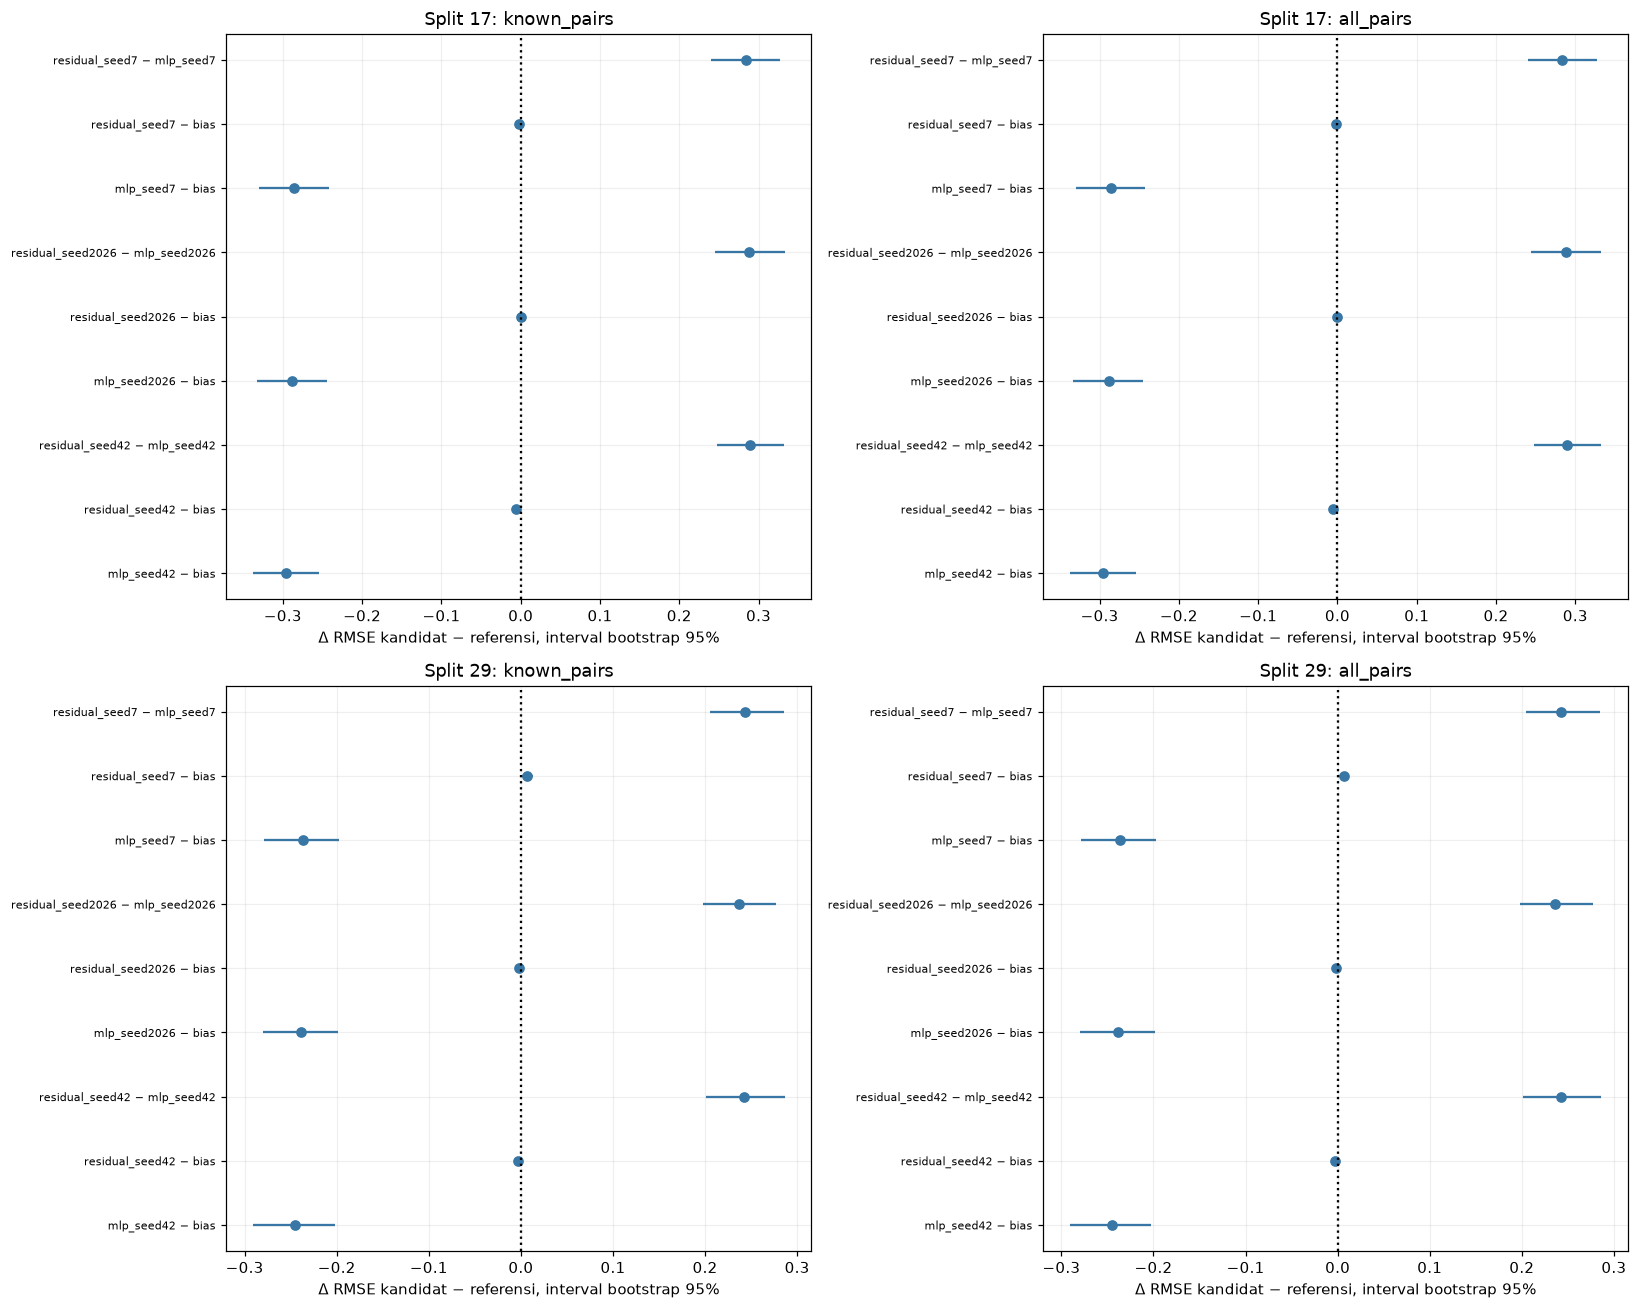

In [23]:
multiseed_bootstrap_rows = []
for split_result in multiseed["assessment_results"]:
    for comparison in split_result["paired_comparisons"]:
        bootstrap = comparison["bootstrap"]
        low, high = bootstrap["interval_95_percent"]
        multiseed_bootstrap_rows.append(
            {
                "split seed": split_result["split_seed"],
                "kandidat": comparison["candidate"],
                "referensi": comparison["reference"],
                "cohort": comparison["scope"],
                "pasangan": bootstrap["pairs"],
                "kelompok pengguna": bootstrap["clusters"],
                "bootstrap draws": bootstrap["draws"],
                "selisih RMSE": bootstrap["point_estimate"],
                "batas bawah 95%": low,
                "batas atas 95%": high,
                "interval melintasi nol": low <= 0 <= high,
                "metode": bootstrap["method"],
            }
        )
multiseed_bootstrap = pd.DataFrame(multiseed_bootstrap_rows)
with pd.option_context("display.max_rows", None):
    display(multiseed_bootstrap)
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
for row, split_seed in enumerate(multiseed["configuration"]["split_seeds"]):
    for column, scope in enumerate(("known_pairs", "all_pairs")):
        ax = axes[row, column]
        frame = multiseed_bootstrap[
            (multiseed_bootstrap["split seed"] == split_seed)
            & (multiseed_bootstrap["cohort"] == scope)
        ]
        labels = (
            frame["kandidat"].str.replace(f"split{split_seed}_", "", regex=False)
            + " − "
            + frame["referensi"].str.replace(f"split{split_seed}_", "", regex=False)
        )
        positions = range(len(frame))
        ax.hlines(positions, frame["batas bawah 95%"], frame["batas atas 95%"], color="#3876a5")
        ax.plot(frame["selisih RMSE"], positions, "o", color="#3876a5")
        ax.axvline(0, color="black", linestyle=":")
        ax.set(
            yticks=list(positions),
            yticklabels=labels,
            title=f"Split {split_seed}: {scope}",
            xlabel="Δ RMSE kandidat − referensi, interval bootstrap 95%",
        )
        ax.tick_params(axis="y", labelsize=7)
plt.tight_layout()
plt.show()

### Analisis tambahan sesudah melihat hasil: semua neural melawan mean global

Perbandingan yang ditentukan sebelum training memakai kontrol bias dan
pasangan residual/MLP pada seed yang sama. Sesudah assessment terlihat,
mean global ternyata merupakan kontrol non-neural terkuat dari tiga kontrol
pada kedua split. Karena itu analisis **post-hoc** berikut menambahkan
bootstrap setiap neural terhadap mean global.

Analisis ini hanya membaca prediksi yang sudah tersimpan dan terverifikasi:
tidak ada training, prediksi baru, seleksi ulang, pembukaan test lama, atau
perubahan model serving. Interval bersifat eksploratif, tidak dikoreksi untuk
banyak perbandingan, dan tidak digabung lintas split. Keduanya tetap dicatat:
analisis yang telah ditentukan sebelum training dan tambahan sesudah melihat
hasil. Tambahan ini tidak dihitung sebagai model atau epoch baru.

,nilai
status,completed
analysis_kind,posthoc_neural_vs_global_control
created_utc,2026-10-13T21:12:31.243006+00:00
predeclared,False
posthoc,True
no_new_training,True
no_new_predictions,True
source_results.path,artifacts/colab/run-20261014-multiseed/final/results.json
source_results.sha256,0da69c6c04c86ce84ce5edf645ec032bafc24ba30cc9c6f674ca1e54221801ce
source_results.bytes,165407


,split seed,kandidat,referensi,cohort,dipilih pada selection,pasangan,kelompok pengguna,bootstrap draws,RMSE kandidat,RMSE mean global,selisih RMSE,batas bawah 95%,batas atas 95%,interval melintasi nol
0,17,split17_mlp_seed42,split17_global_mean,known_pairs,True,3002,3000,1000,1.62709962,1.79144859,-0.16434897,-0.19182120,-0.13818156,False
1,17,split17_residual_seed42,split17_global_mean,known_pairs,False,3002,3000,1000,1.91673130,1.79144859,0.12528271,0.06840771,0.18201273,False
2,17,split17_mlp_seed2026,split17_global_mean,known_pairs,False,3002,3000,1000,1.63507741,1.79144859,-0.15637118,-0.18092548,-0.13067464,False
3,17,split17_residual_seed2026,split17_global_mean,known_pairs,False,3002,3000,1000,1.92275411,1.79144859,0.13130552,0.07327115,0.18662237,False
4,17,split17_mlp_seed7,split17_global_mean,known_pairs,False,3002,3000,1000,1.63684757,1.79144859,-0.15460102,-0.18033079,-0.12977634,False
5,17,split17_residual_seed7,split17_global_mean,known_pairs,False,3002,3000,1000,1.92062431,1.79144859,0.12917572,0.07128951,0.18540599,False
6,17,split17_mlp_seed42,split17_global_mean,all_pairs,True,3002,3000,1000,1.62709962,1.79144859,-0.16434897,-0.19182120,-0.13818156,False
7,17,split17_residual_seed42,split17_global_mean,all_pairs,False,3002,3000,1000,1.91673130,1.79144859,0.12528271,0.06840771,0.18201273,False
8,17,split17_mlp_seed2026,split17_global_mean,all_pairs,False,3002,3000,1000,1.63507741,1.79144859,-0.15637118,-0.18092548,-0.13067464,False
9,17,split17_residual_seed2026,split17_global_mean,all_pairs,False,3002,3000,1000,1.92275411,1.79144859,0.13130552,0.07327115,0.18662237,False


Pada **6** model MLP, **6** interval berada seluruhnya di bawah nol dibanding mean global. Pada **6** model residual, **6** interval berada seluruhnya di atas nol. Ini mendukung manfaat MLP pada assessment internal warm yang dipakai, dengan batas analisis post-hoc di atas. Baris known/full yang sama tidak dihitung sebagai percobaan independen tambahan.

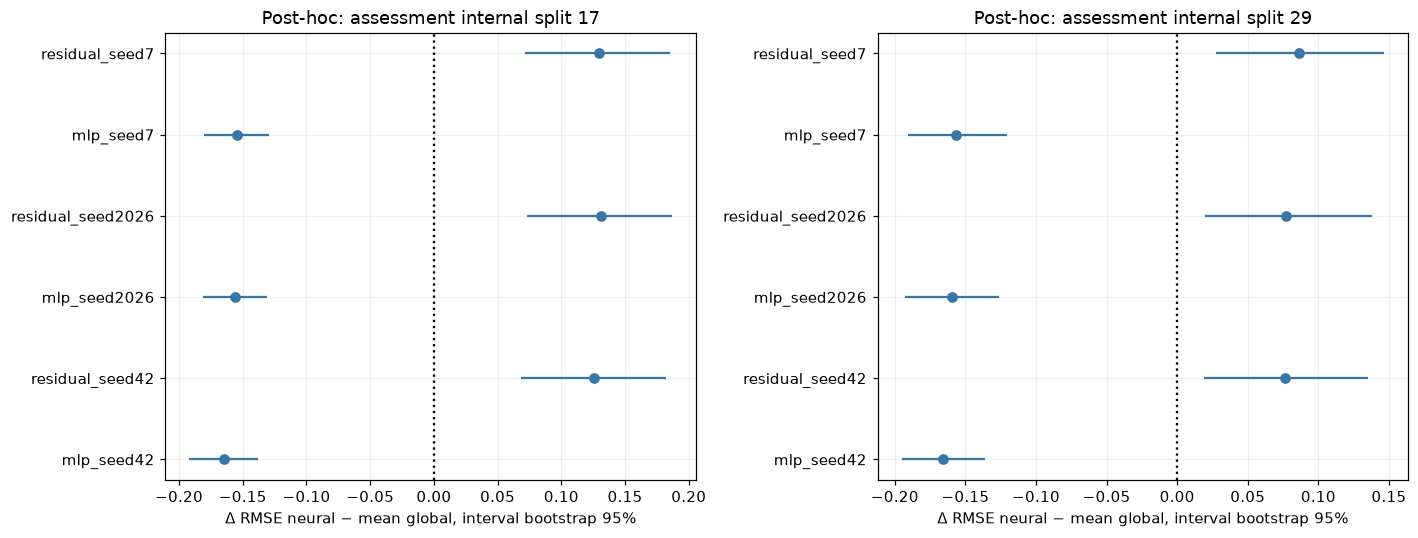

In [24]:
multiseed_posthoc = evidence["multiseed_posthoc"]
assert multiseed_posthoc["analysis_kind"] == "posthoc_neural_vs_global_control"
assert multiseed_posthoc["posthoc"] is True
assert multiseed_posthoc["predeclared"] is False
assert multiseed_posthoc["no_new_training"]
assert multiseed_posthoc["no_new_predictions"]
assert multiseed_posthoc["original_test_used"] is False
assert multiseed_posthoc["serving_changed"] is False
assert multiseed_posthoc["verification"]["all_prediction_rows_match_source"]
assert multiseed_posthoc["verification"]["all_stored_rmse_reproduced"]
display(
    pd.json_normalize(
        {
            key: multiseed_posthoc[key]
            for key in (
                "status",
                "analysis_kind",
                "created_utc",
                "predeclared",
                "posthoc",
                "no_new_training",
                "no_new_predictions",
                "source_results",
                "prediction_csv_fingerprints",
                "script_fingerprint",
                "verification",
            )
        }
    ).T.rename(columns={0: "nilai"})
)
posthoc_rows = []
for comparison in multiseed_posthoc["comparisons"]:
    bootstrap = comparison["bootstrap"]
    low, high = bootstrap["interval_95_percent"]
    posthoc_rows.append(
        {
            "split seed": comparison["split_seed"],
            "kandidat": comparison["candidate"],
            "referensi": comparison["reference"],
            "cohort": comparison["scope"],
            "dipilih pada selection": comparison["candidate"]
            == selection_by_split[comparison["split_seed"]]["best_neural_candidate"],
            "pasangan": bootstrap["pairs"],
            "kelompok pengguna": bootstrap["clusters"],
            "bootstrap draws": bootstrap["draws"],
            "RMSE kandidat": comparison["candidate_rmse"],
            "RMSE mean global": comparison["reference_rmse"],
            "selisih RMSE": bootstrap["point_estimate"],
            "batas bawah 95%": low,
            "batas atas 95%": high,
            "interval melintasi nol": low <= 0 <= high,
        }
    )
posthoc_comparisons = pd.DataFrame(posthoc_rows)
display(posthoc_comparisons)
posthoc_known = posthoc_comparisons[posthoc_comparisons["cohort"] == "known_pairs"]
mlp_intervals = posthoc_known[
    posthoc_known["kandidat"].map(lambda name: multiseed_by_name[name]["architecture"] == "mlp")
]
residual_intervals = posthoc_known[
    posthoc_known["kandidat"].map(
        lambda name: multiseed_by_name[name]["architecture"] == "residual"
    )
]
display(
    Markdown(
        f"Pada **{len(mlp_intervals)}** model MLP, **{int((mlp_intervals['batas atas 95%'] < 0).sum())}** "
        "interval berada seluruhnya di bawah nol dibanding mean global. "
        f"Pada **{len(residual_intervals)}** model residual, "
        f"**{int((residual_intervals['batas bawah 95%'] > 0).sum())}** interval berada seluruhnya di atas nol. "
        "Ini mendukung manfaat MLP pada assessment internal warm yang dipakai, "
        "dengan batas analisis post-hoc di atas. Baris known/full yang sama tidak "
        "dihitung sebagai percobaan independen tambahan."
    )
)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, split_seed in zip(axes, multiseed["configuration"]["split_seeds"], strict=True):
    frame = posthoc_comparisons[
        (posthoc_comparisons["split seed"] == split_seed)
        & (posthoc_comparisons["cohort"] == "known_pairs")
    ]
    labels = frame["kandidat"].str.replace(f"split{split_seed}_", "", regex=False)
    positions = range(len(frame))
    ax.hlines(positions, frame["batas bawah 95%"], frame["batas atas 95%"], color="#3876a5")
    ax.plot(frame["selisih RMSE"], positions, "o", color="#3876a5")
    ax.axvline(0, color="black", linestyle=":")
    ax.set(
        yticks=list(positions),
        yticklabels=labels,
        xlabel="Δ RMSE neural − mean global, interval bootstrap 95%",
        title=f"Post-hoc: assessment internal split {split_seed}",
    )
plt.tight_layout()
plt.show()

### Variasi seed training: ringkasan deskriptif, bukan tiga split independen

Mean dan standar deviasi di bawah berasal dari tiga seed training pada
**data yang sama** untuk setiap arsitektur/split. Angka ini mengukur variasi
inisialisasi dan urutan mini-batch yang diamati, bukan standard error terhadap populasi pengguna.
Tidak ada pooling seluruh enam model sebagai enam replikasi dataset, dan
tidak ada promosi kandidat berdasarkan assessment.

In [25]:
multiseed_seed_summary = pd.DataFrame(multiseed["seed_summary"])
display(multiseed_seed_summary)
display(
    Markdown(
        "**Batas interpretasi run kelima:** assessment pengembangan ini lebih besar, "
        "tetapi tetap dibentuk dari train yang sudah pernah dilihat dan pengguna "
        "yang sengaja dipertahankan warm. Hasilnya menguji konsistensi pada desain "
        "ini. Bukti tentang pengguna/buku baru, ranking top-10, dan test independen "
        "masih memerlukan evaluasi tersendiri."
    )
)

,split_seed,architecture,initialization_seeds,models,known_rmse_mean,known_rmse_std,all_rmse_mean,all_rmse_std,best_epochs,variation_scope,interpretation
0,17,mlp,"[42, 2026, 7]","[split17_mlp_seed42, split17_mlp_seed2026, split17_mlp_seed7]",1.63300820,0.00519297,1.63300820,0.00519297,"[2, 2, 2]",Training seeds change initialization and minibatch order; split held fixed,"Descriptive sample SD across training seeds, not a confidence interval"
1,17,residual,"[42, 2026, 7]","[split17_residual_seed42, split17_residual_seed2026, split17_residual_seed7]",1.92003657,0.00305412,1.92003657,0.00305412,"[4, 1, 4]",Training seeds change initialization and minibatch order; split held fixed,"Descriptive sample SD across training seeds, not a confidence interval"
2,29,mlp,"[42, 2026, 7]","[split29_mlp_seed42, split29_mlp_seed2026, split29_mlp_seed7]",1.59718903,0.00478612,1.59718903,0.00478612,"[2, 3, 3]",Training seeds change initialization and minibatch order; split held fixed,"Descriptive sample SD across training seeds, not a confidence interval"
3,29,residual,"[42, 2026, 7]","[split29_residual_seed42, split29_residual_seed2026, split29_residual_seed7]",1.83784224,0.00527921,1.83784224,0.00527921,"[5, 6, 5]",Training seeds change initialization and minibatch order; split held fixed,"Descriptive sample SD across training seeds, not a confidence interval"


**Batas interpretasi run kelima:** assessment pengembangan ini lebih besar, tetapi tetap dibentuk dari train yang sudah pernah dilihat dan pengguna yang sengaja dipertahankan warm. Hasilnya menguji konsistensi pada desain ini. Bukti tentang pengguna/buku baru, ranking top-10, dan test independen masih memerlukan evaluasi tersendiri.

## Run keenam: pembanding bias/MF yang dituning dan ranking katalog penuh

Run kelima menemukan MLP lebih baik daripada tiga kontrol sederhana pada
assessment internal. Run keenam menguji pembanding yang lebih kuat dan
mengukur kualitas daftar rekomendasi, memakai **split pengembangan internal
yang sama, yang assessment-nya sudah pernah dilihat**. Selection tetap dipakai
untuk tuning, tetapi assessment ini kini digunakan ulang secara eksplisit.
Tidak ada klaim konfirmasi pada test independen baru.

Pada setiap split, 16 kombinasi shrinkage pengguna/buku dari `{0, 5, 20, 100}`
dipakai untuk bias yang dioptimalkan bersama. Biased matrix factorization
memakai tiga nilai regularisasi `{1e-4, 1e-3, 1e-2}` × tiga seed training
`{42, 2026, 7}`: total 18 training MF pada dua split. Maksimal 30 epoch dengan
patience 5. Lambda dipilih menurut **mean RMSE selection tiga seed**, lalu
kandidat utama ditetapkan memakai selection. Semua model dikunci sebelum
assessment dan ranking pada run ini dihitung.

**MF merupakan model embedding dangkal dengan dot product dan bias, bukan
deep MLP.** Delapan belas training MF dicatat terpisah dari 24 training deep
MLP/residual pada lima run sebelumnya. Enam MLP dari run kelima hanya dimuat
ulang dari checkpoint tersimpan; tidak dihitung sebagai training baru.

Ranking memakai seluruh katalog 5.000 ISBN, digabung ke karya kanonik dengan
maksimum skor ISBN mentah. Seluruh karya yang sudah ada di fit pengguna
dikeluarkan. Satu karya holdout relevan bila salah satu rating edisinya ≥8;
target yang tidak tersedia tetap dihitung miss. Tiga MLP, tiga MF pada lambda
terpilih, bias terpilih, dan popularity dari fit dinilai pada cohort yang sama.
Tidak ada tuning berdasarkan ranking.

In [26]:
comparator = evidence["comparator"]
comparator_manifest = evidence["comparator_manifest"]
assert comparator["experiment_kind"] == "tuned_bias_mf_ranking_reused_development"
assert comparator["original_test_used"] is False
assert comparator["original_validation_used"] is False
assert comparator["dataset"]["reused_prior_assessment"] is True
assert comparator["model_promotion_to_application"] is False
comparator_config = comparator["configuration"]
bias_grid = comparator["bias_grid_results"]
mf_candidates = comparator["candidate_validation_results"]
reused_mlps = comparator["reused_mlp_results"]
comparator_selection = {row["split_seed"]: row for row in comparator["lambda_selection"]}
mf_by_name = {row["name"]: row for row in mf_candidates}
assert all(row["selection_only"] for row in comparator_selection.values())
assert all(not row["trained_in_this_run"] for row in reused_mlps)
display(
    pd.DataFrame(
        [
            {
                "run": "Bias dituning, MF dangkal, dan ranking katalog penuh",
                "session": comparator_manifest["session_name"],
                "selesai (Asia/Jakarta)": pd.Timestamp(comparator["completed_utc"])
                .tz_convert("Asia/Jakarta")
                .isoformat(),
                "status": comparator["status"],
                "durasi (detik)": comparator["total_seconds"],
                "konfigurasi bias": len(bias_grid),
                "training MF": len(mf_candidates),
                "MLP hanya dimuat ulang": len(reused_mlps),
                "assessment dihitung ulang": comparator["assessment_performed"],
                "assessment sudah pernah dilihat": comparator["dataset"]["reused_prior_assessment"],
                "arsip terverifikasi": len(comparator_manifest["backups"]),
                "runtime dihentikan": comparator_manifest["shutdown"]["stopped"],
            }
        ]
    )
)
display(Markdown("**Konfigurasi lengkap dan aturan pemilihan sebelum assessment/ranking**"))
display(pd.json_normalize(comparator_config).T.rename(columns={0: "nilai"}))
display(pd.json_normalize(comparator["dataset"]["splits"]))

,run,session,selesai (Asia/Jakarta),status,durasi (detik),konfigurasi bias,training MF,MLP hanya dimuat ulang,assessment dihitung ulang,assessment sudah pernah dilihat,arsip terverifikasi,runtime dihentikan
0,"Bias dituning, MF dangkal, dan ranking katalog penuh",book-recommendation-neural-20261014-comparators,2026-10-14T04:43:41.386851+07:00,completed,190.70328535,32,18,6,True,True,23,True


**Konfigurasi lengkap dan aturan pemilihan sebelum assessment/ranking**

,nilai
started_utc,2026-10-13T21:40:30.953859+00:00
candidates,"[{'name': 'split17_mf_lam1e4_seed42', 'split_seed': 17, 'initialization_seed': 42, 're..."
split_seeds,"[17, 29]"
training_seeds,"[42, 2026, 7]"
bias_user_shrinkages,"[0.0, 5.0, 20.0, 100.0]"
bias_item_shrinkages,"[0.0, 5.0, 20.0, 100.0]"
bias_max_iterations,1000
bias_tolerance,0.0
bias_objective,Sum squared normalized fit residuals + user_alpha*sum(user_bias²) + item_alpha*sum(ite...
mf_lambdas,"[0.0001, 0.001, 0.01]"


,split_seed,eligible_users,source_pairs,fit_pairs,fit_users,fit_isbns,selection_pairs,assessment_pairs,selection_users,assessment_users,selection_works,assessment_works,...,metric_weighting,partition_row_sha256.fit,partition_row_sha256.selection,partition_row_sha256.assessment,partition_file_fingerprints.fit_ratings.csv.sha256,partition_file_fingerprints.fit_ratings.csv.bytes,partition_file_fingerprints.selection_ratings.csv.sha256,partition_file_fingerprints.selection_ratings.csv.bytes,partition_file_fingerprints.assessment_ratings.csv.sha256,partition_file_fingerprints.assessment_ratings.csv.bytes,partition_file_fingerprints.membership.json.sha256,partition_file_fingerprints.membership.json.bytes
0,17,15312,111875,105871,15312,5000,3002,3002,3000,3000,3000,3000,...,Rating-pair weighted; repeated editions remain in the same user cluster,d43058aa89dcdfdad2c56bc37144cdcd040af2742d855355eb55dc58f4a0c584,676c80ab221af8a26c3c042aa86b4f05883f4c1e518c2370d8bcf0944261995d,bc7612ffc5bde945db8cdc0f16367db99324c08ac028224e9f1c72de6ce51c05,ac5ace4bda3ef7eb78c6f0dd98fc0e554a4c3c2e2c6e2a98c2f48c66da6b56f6,8652307,0a57eb20b686e06004fb6f2946036907c7c3b37d41da3bdb58e0051b67f3dac4,247281,2fe5dff4f1be39f7e5aa0f9dd4ac2607b1a884958dc10a572298bb8926bbf6a0,247211,67f6abe3f0abf2cb6a3d7da465fa82626b158010eebe840ffa844aa2ff0ee890,807927
1,29,15312,111875,105869,15312,5000,3001,3005,3000,3000,3000,3000,...,Rating-pair weighted; repeated editions remain in the same user cluster,345c052b8afbe4bae9957f89349b3656a92229194068554c0c4f7e9accb2f20b,d40504116cf2b077efdd40eee5236ac1e45b9e5d84955f779138f50932adc015,41f45dc8327240eaedf8b4204ffcd4c6d6f1275bd406ac2210e84532bee0c687,ec8b9bab0a794f6199a1d12736fbc149be3996ce3f750ca895171aed4c433edc,8655086,26e7f0a2cb482fdcf57b5576c07b127e13615d9340fa79d9cb7e3ae1133909c3,245283,8c9bd6fb798cdf15b41beb1fad240c85edc3e45b204f66ac0b24b2a459c504ae,246430,0111f6e4c1d64a0cfc4f97c7a7bbd6ea118f0e57f5b2c42918b2af52fc1e7cda,804948


### Seluruh 32 konfigurasi bias yang dioptimalkan bersama

Target dinormalisasi `(rating - 1) / 9`, dengan mean global fit tetap. Bias
pengguna dan buku diperbarui bergantian untuk meminimalkan:

`sum((target - mean_global - bias_user - bias_book)^2)`
`+ alpha_user * sum(bias_user^2) + alpha_item * sum(bias_book^2)`.

Maksimal 1.000 iterasi dengan toleransi perubahan parameter 1e-10. Flag
konvergensi, iterasi, objective fit, dan delta parameter dicatat untuk semua
konfigurasi. Ini pembanding yang dituning; kontrol bias awal memakai prosedur
dan shrinkage tetap yang berbeda. Hanya bias terpilih menurut selection yang
dinilai pada assessment/ranking, sehingga kandidat lain tidak memiliki skor
assessment dan tidak boleh ditafsirkan mendapat skor nol.

,percobaan,split seed,alpha user,alpha buku,status,konvergen,iterasi,delta parameter terakhir,objective fit,selection RMSE,selection MAE,dipilih pada selection,status assessment
0,split17_bias_u0_i0,17,0.0,0.0,completed,True,70,9.38362305e-11,2216.73655075,1.84016981,1.38516724,False,tidak dinilai
1,split17_bias_u0_i5,17,0.0,5.0,completed,True,90,8.66234584e-11,2312.58362648,1.81809059,1.36470457,False,tidak dinilai
2,split17_bias_u0_i20,17,0.0,20.0,completed,True,36,9.70247493e-11,2421.21210400,1.81928473,1.36019220,False,tidak dinilai
3,split17_bias_u0_i100,17,0.0,100.0,completed,True,18,3.33190697e-11,2538.12930138,1.84562570,1.37231027,False,tidak dinilai
4,split17_bias_u5_i0,17,5.0,0.0,completed,True,51,9.85622972e-11,2767.87223568,1.63192126,1.27555512,False,tidak dinilai
5,split17_bias_u5_i5,17,5.0,5.0,completed,True,32,9.95452887e-11,2865.92212618,1.60944183,1.25681120,False,tidak dinilai
6,split17_bias_u5_i20,17,5.0,20.0,completed,True,19,4.42754722e-11,2984.16494302,1.60348069,1.24848070,True,dinilai
7,split17_bias_u5_i100,17,5.0,100.0,completed,True,13,2.26836189e-11,3118.55832413,1.61610303,1.25694393,False,tidak dinilai
8,split17_bias_u20_i0,17,20.0,0.0,completed,True,25,9.66274283e-11,3094.13328246,1.67691637,1.31946848,False,tidak dinilai
9,split17_bias_u20_i5,17,20.0,5.0,completed,True,20,4.15052992e-11,3193.86171501,1.65569031,1.30137046,False,tidak dinilai


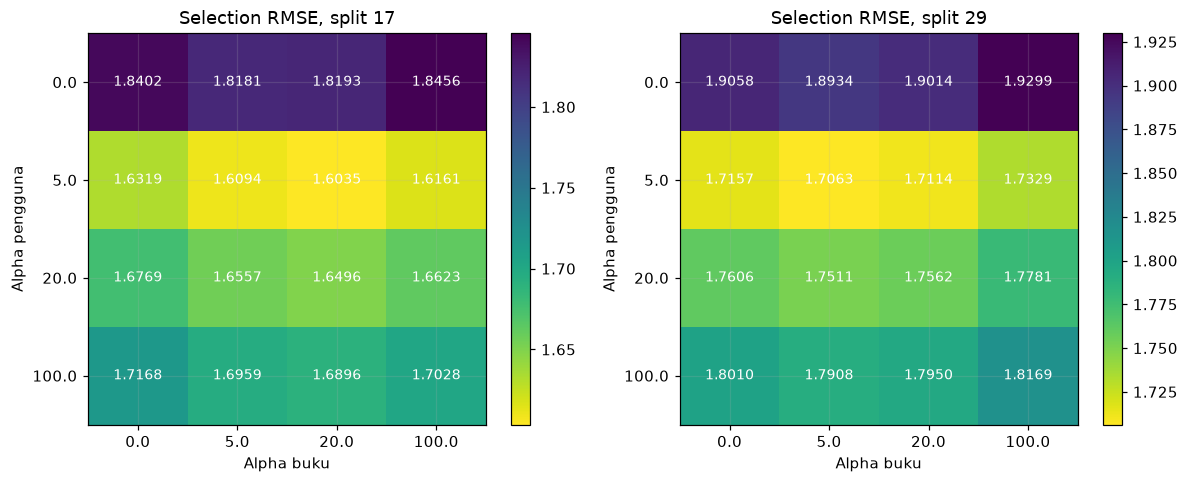

In [27]:
bias_grid_rows = []
for row in bias_grid:
    score = row.get("selection", {}).get("known_pairs", {})
    bias_grid_rows.append(
        {
            "percobaan": row["name"],
            "split seed": row["split_seed"],
            "alpha user": row["user_shrinkage"],
            "alpha buku": row["item_shrinkage"],
            "status": row["status"],
            "konvergen": row.get("converged"),
            "iterasi": row.get("iterations"),
            "delta parameter terakhir": row.get("final_max_parameter_delta"),
            "objective fit": row.get("fit_objective"),
            "selection RMSE": score.get("rmse_rating_scale"),
            "selection MAE": score.get("mae_rating_scale"),
            "dipilih pada selection": row["selected"],
            "status assessment": "dinilai"
            if row["selected"] and comparator["assessment_performed"]
            else "tidak dinilai",
        }
    )
bias_grid_frame = pd.DataFrame(bias_grid_rows)
display(bias_grid_frame)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, split_seed in zip(axes, comparator_config["split_seeds"], strict=True):
    table = bias_grid_frame[bias_grid_frame["split seed"] == split_seed].pivot(
        index="alpha user", columns="alpha buku", values="selection RMSE"
    )
    picture = ax.imshow(table.to_numpy(), cmap="viridis_r", aspect="auto")
    for row_index in range(len(table.index)):
        for column_index in range(len(table.columns)):
            ax.text(
                column_index,
                row_index,
                f"{table.iloc[row_index, column_index]:.4f}",
                ha="center",
                va="center",
                color="white",
                fontsize=9,
            )
    ax.set(
        xticks=range(len(table.columns)),
        xticklabels=table.columns,
        yticks=range(len(table.index)),
        yticklabels=table.index,
        xlabel="Alpha buku",
        ylabel="Alpha pengguna",
        title=f"Selection RMSE, split {split_seed}",
    )
    fig.colorbar(picture, ax=ax)
plt.tight_layout()
plt.show()

### MF dangkal: seluruh lambda, seed, checkpoint, dan epoch

Prediksi mentah MF adalah `mean_global + bias_user + bias_book + dot(p_user, q_book)`.
Embedding 16 dimensi dimulai dari normal stddev 0,05. Bias dimulai dari bias
terpilih lalu **tetap boleh berubah** selama Adam, learning rate 0,005. Karena
bias ikut dilatih, hasil MF yang memburuk tidak membuktikan faktor laten tidak
bermanfaat pada semua rancangan.

Objective mini-batch adalah MSE rata-rata ditambah
`lambda * mean(||p_user||² + ||q_book||² + bias_user² + bias_book²)` pada pasangan
yang diamati. Penalti ini berbobot frekuensi interaksi dan berbeda dari L2
Keras atas seluruh matriks pada run sebelumnya; angka lambda tidak dibandingkan
langsung dengan L2 lama. Penalti bias MF juga tidak mempertahankan shrinkage
joint bias yang dipilih sebelumnya, sehingga efek faktor laten dan perubahan
bias tidak dapat dipisahkan dari perbandingan ini saja.
Train RMSE berasal dari prediksi mentah; RMSE selection
dan assessment memotong prediksi ke rating 1–10. `reg_loss` adalah rata-rata
penalti dari mini-batch selama epoch, bukan penalti checkpoint akhir saja.

,percobaan,split seed,model,seed training,lambda sampled-pair,status,epoch selesai,epoch terbaik selection,terbaik tepat di batas epoch,berhenti di batas epoch,selection RMSE,lambda dipilih untuk ranking,MF utama dari selection,save/load terverifikasi
0,split17_mf_lam1e4_seed42,17,MF embedding dangkal,42,0.0001,completed,6,1,False,False,1.62368500,False,False,True
1,split17_mf_lam1e4_seed2026,17,MF embedding dangkal,2026,0.0001,completed,6,1,False,False,1.61922087,False,False,True
2,split17_mf_lam1e4_seed7,17,MF embedding dangkal,7,0.0001,completed,6,1,False,False,1.61866190,False,False,True
3,split17_mf_lam1e3_seed42,17,MF embedding dangkal,42,0.0010,completed,6,1,False,False,1.62304311,False,False,True
4,split17_mf_lam1e3_seed2026,17,MF embedding dangkal,2026,0.0010,completed,6,1,False,False,1.61879563,False,False,True
5,split17_mf_lam1e3_seed7,17,MF embedding dangkal,7,0.0010,completed,6,1,False,False,1.61830445,False,False,True
6,split17_mf_lam1e2_seed42,17,MF embedding dangkal,42,0.0100,completed,6,1,False,False,1.61839263,True,False,True
7,split17_mf_lam1e2_seed2026,17,MF embedding dangkal,2026,0.0100,completed,6,1,False,False,1.61568000,True,False,True
8,split17_mf_lam1e2_seed7,17,MF embedding dangkal,7,0.0100,completed,6,1,False,False,1.61555108,True,True,True
9,split29_mf_lam1e4_seed42,29,MF embedding dangkal,42,0.0001,completed,6,1,False,False,1.71552279,False,False,True


**Pemilihan lambda menurut mean tiga seed training pada selection**

,split seed,regularization_lambda,selection_rmse_mean,selection_rmse_std,n_seeds,dipilih menurut mean selection
0,17,0.0001,1.62052259,0.00275295,3,False
1,17,0.0010,1.62004773,0.00260567,3,False
2,17,0.0100,1.61654123,0.00160465,3,True
3,29,0.0001,1.71692708,0.00443176,3,False
4,29,0.0010,1.71640913,0.00433803,3,False
5,29,0.0100,1.71290435,0.00359796,3,True


,split_seed,grid,selected_lambda,selected_mf_candidates,primary_mf_candidate,primary_mlp_candidate,bias_candidate,selection_only
0,17,"[{'regularization_lambda': 0.0001, 'selection_rmse_mean': 1.6205225861930603, 'selecti...",0.01,"[split17_mf_lam1e2_seed42, split17_mf_lam1e2_seed2026, split17_mf_lam1e2_seed7]",split17_mf_lam1e2_seed7,split17_mlp_seed42,split17_bias_u5_i20,True
1,29,"[{'regularization_lambda': 0.0001, 'selection_rmse_mean': 1.7169270788746642, 'selecti...",0.01,"[split29_mf_lam1e2_seed42, split29_mf_lam1e2_seed2026, split29_mf_lam1e2_seed7]",split29_mf_lam1e2_seed7,split29_mlp_seed7,split29_bias_u5_i5,True


,percobaan,split seed,lambda,seed training,epoch,train_mse,train_rmse,val_mse,val_rmse,reg_loss,checkpoint terbaik selection
0,split17_mf_lam1e4_seed42,17,0.0001,42,1,0.01882468,1.23482767,0.03254757,1.62368499,0.00001109,True
1,split17_mf_lam1e4_seed42,17,0.0001,42,2,0.00996583,0.89846106,0.03426031,1.66585856,0.00002576,False
2,split17_mf_lam1e4_seed42,17,0.0001,42,3,0.00509386,0.64234181,0.03646421,1.71860444,0.00005328,False
3,split17_mf_lam1e4_seed42,17,0.0001,42,4,0.00346276,0.52960708,0.03782854,1.75046034,0.00007006,False
4,split17_mf_lam1e4_seed42,17,0.0001,42,5,0.00282547,0.47839611,0.03844382,1.76463852,0.00007829,False
5,split17_mf_lam1e4_seed42,17,0.0001,42,6,0.00246795,0.44710578,0.03862420,1.76877369,0.00008360,False
6,split17_mf_lam1e4_seed2026,17,0.0001,2026,1,0.01888227,1.23671504,0.03236884,1.61922087,0.00001113,True
7,split17_mf_lam1e4_seed2026,17,0.0001,2026,2,0.01007503,0.90337008,0.03407394,1.66132144,0.00002540,False
8,split17_mf_lam1e4_seed2026,17,0.0001,2026,3,0.00510250,0.64288621,0.03602646,1.70825747,0.00005291,False
9,split17_mf_lam1e4_seed2026,17,0.0001,2026,4,0.00352376,0.53425168,0.03730563,1.73831990,0.00007006,False


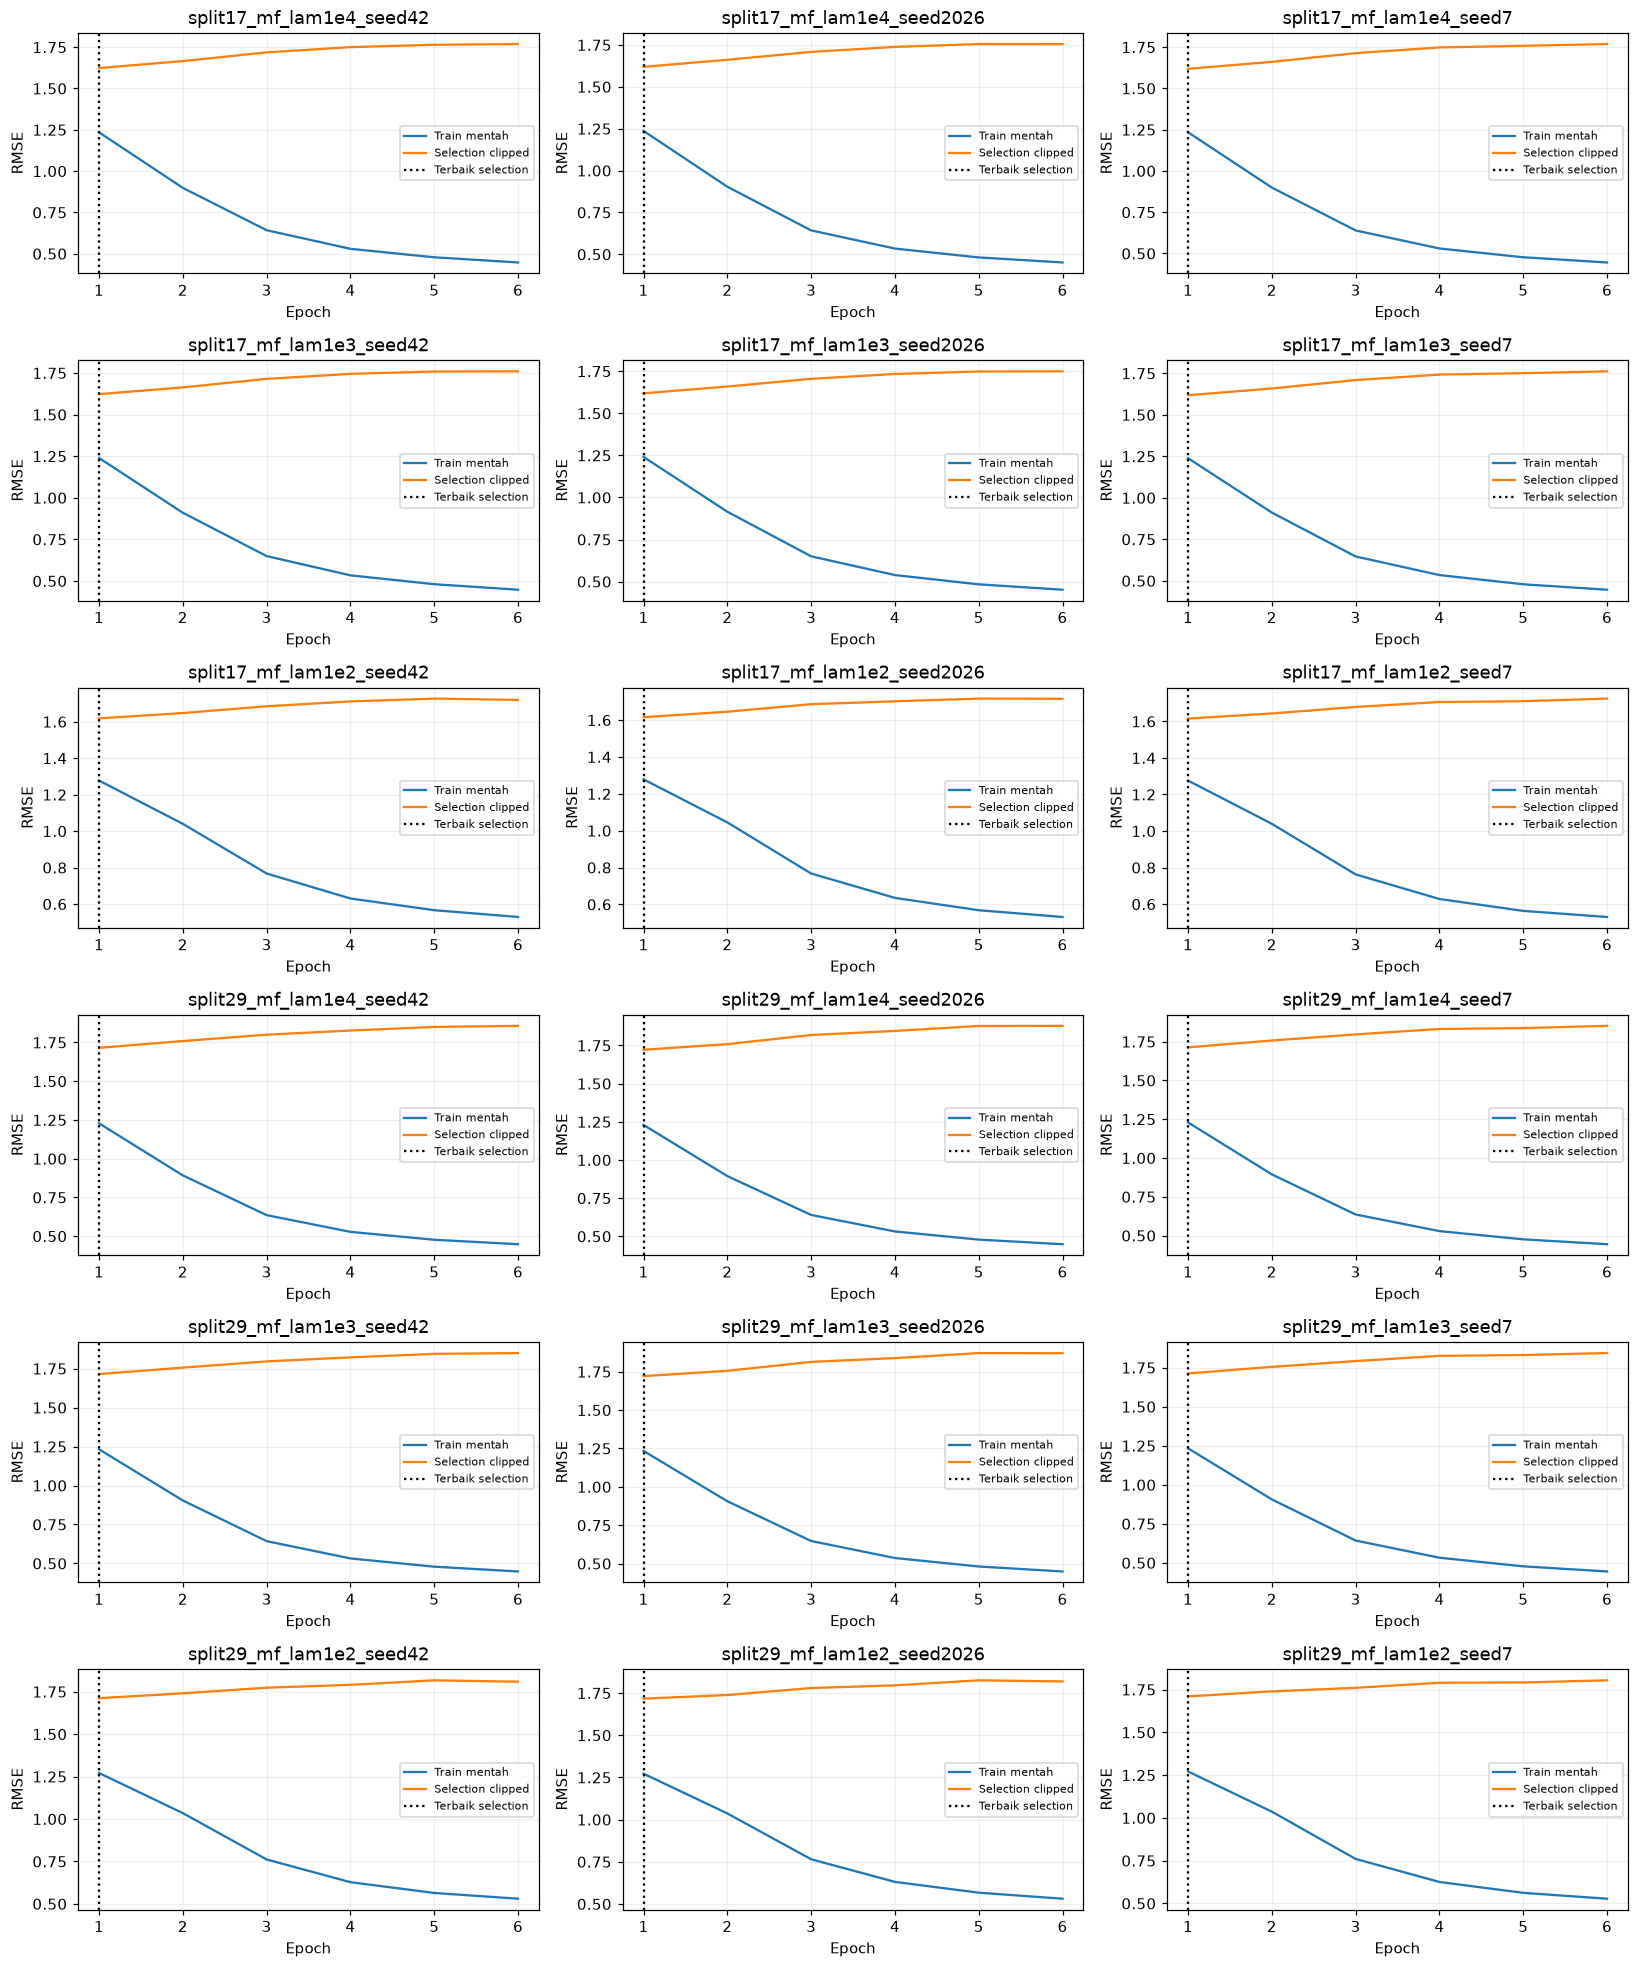

Checkpoint terbaik yang berada tepat di batas epoch belum membuktikan konvergensi. Flag tersebut dilaporkan terpisah dari early stopping dan konvergensi bias.

**Bukti update pertama MF: loss, perubahan embedding, dan gradient**

,percobaan,MSE sebelum,penalti sampled-pair,total loss sebelum,norma perubahan embedding,iterasi optimizer
0,split17_mf_lam1e4_seed42,0.02440961,0.00000867,0.02441828,0.38529679,1
1,split17_mf_lam1e4_seed2026,0.02454726,0.00000864,0.02455590,0.38552573,1
2,split17_mf_lam1e4_seed7,0.02672500,0.00000863,0.02673363,0.38197955,1
3,split17_mf_lam1e3_seed42,0.02440961,0.00008666,0.02449627,0.38540620,1
4,split17_mf_lam1e3_seed2026,0.02454726,0.00008636,0.02463363,0.38570833,1
5,split17_mf_lam1e3_seed7,0.02672500,0.00008626,0.02681126,0.38209423,1
6,split17_mf_lam1e2_seed42,0.02440961,0.00086660,0.02527622,0.39220101,1
7,split17_mf_lam1e2_seed2026,0.02454726,0.00086362,0.02541088,0.39291787,1
8,split17_mf_lam1e2_seed7,0.02672500,0.00086258,0.02758758,0.38850978,1
9,split29_mf_lam1e4_seed42,0.02385510,0.00000892,0.02386402,0.38443685,1


,percobaan,variabel,norma gradient total
0,split17_mf_lam1e4_seed42,biased_matrix_factorization/user_bias,0.00980700
1,split17_mf_lam1e4_seed42,biased_matrix_factorization/book_bias,0.00957041
2,split17_mf_lam1e4_seed42,biased_matrix_factorization/user_embedding/embeddings,0.00199657
3,split17_mf_lam1e4_seed42,biased_matrix_factorization/book_embedding/embeddings,0.00192706
4,split17_mf_lam1e4_seed2026,biased_matrix_factorization/user_bias,0.00983943
5,split17_mf_lam1e4_seed2026,biased_matrix_factorization/book_bias,0.00974317
6,split17_mf_lam1e4_seed2026,biased_matrix_factorization/user_embedding/embeddings,0.00196507
7,split17_mf_lam1e4_seed2026,biased_matrix_factorization/book_embedding/embeddings,0.00191730
8,split17_mf_lam1e4_seed7,biased_matrix_factorization/user_bias,0.00998153
9,split17_mf_lam1e4_seed7,biased_matrix_factorization/book_bias,0.01018226


In [28]:
mf_rows = []
for row in mf_candidates:
    selected = comparator_selection.get(row["split_seed"], {})
    mf_rows.append(
        {
            "percobaan": row["name"],
            "split seed": row["split_seed"],
            "model": "MF embedding dangkal",
            "seed training": row["initialization_seed"],
            "lambda sampled-pair": row["regularization_lambda"],
            "status": row["status"],
            "epoch selesai": row["epochs_completed"],
            "epoch terbaik selection": row["best_epoch"],
            "terbaik tepat di batas epoch": row.get("best_at_epoch_cap"),
            "berhenti di batas epoch": row.get("stopped_at_epoch_cap"),
            "selection RMSE": row.get("validation", {}).get("rmse_rating_scale"),
            "lambda dipilih untuk ranking": row["name"]
            in selected.get("selected_mf_candidates", []),
            "MF utama dari selection": row["name"] == selected.get("primary_mf_candidate"),
            "save/load terverifikasi": row.get("model_roundtrip_verified"),
        }
    )
mf_experiments = pd.DataFrame(mf_rows)
display(mf_experiments)
lambda_rows = [
    {
        "split seed": row["split_seed"],
        **choice,
        "dipilih menurut mean selection": choice["regularization_lambda"] == row["selected_lambda"],
    }
    for row in comparator["lambda_selection"]
    for choice in row["grid"]
]
display(Markdown("**Pemilihan lambda menurut mean tiga seed training pada selection**"))
display(pd.DataFrame(lambda_rows))
display(pd.json_normalize(comparator["lambda_selection"]))
mf_epochs = pd.DataFrame(
    [
        {
            "percobaan": row["name"],
            "split seed": row["split_seed"],
            "lambda": row["regularization_lambda"],
            "seed training": row["initialization_seed"],
            **epoch,
            "checkpoint terbaik selection": epoch["epoch"] == row["best_epoch"],
        }
        for row in mf_candidates
        for epoch in row["history"]
    ]
)
assert len(mf_epochs) == comparator["training"]["total_neural_epochs"]
with pd.option_context("display.max_rows", None):
    display(mf_epochs)
fig, axes = plt.subplots(6, 3, figsize=(15, 18))
for ax, row in zip(axes.flat, mf_candidates, strict=True):
    frame = pd.DataFrame(row["history"])
    ax.plot(frame["epoch"], frame["train_rmse"], label="Train mentah")
    ax.plot(frame["epoch"], frame["val_rmse"], label="Selection clipped")
    ax.axvline(row["best_epoch"], color="black", linestyle=":", label="Terbaik selection")
    ax.set(title=row["name"], xlabel="Epoch", ylabel="RMSE")
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()
display(
    Markdown(
        "Checkpoint terbaik yang berada tepat di batas epoch belum membuktikan konvergensi. "
        "Flag tersebut dilaporkan terpisah dari early stopping dan konvergensi bias."
    )
)
display(Markdown("**Bukti update pertama MF: loss, perubahan embedding, dan gradient**"))
mf_trace_rows, mf_gradient_rows = [], []
for row in mf_candidates:
    trace = row.get("first_step_trace")
    if not trace:
        continue
    mf_trace_rows.append(
        {
            "percobaan": row["name"],
            "MSE sebelum": trace["mse_before"],
            "penalti sampled-pair": trace["regularization_loss"],
            "total loss sebelum": trace["total_loss_before"],
            "norma perubahan embedding": trace["embedding_delta_norm"],
            "iterasi optimizer": trace["optimizer_iterations"],
        }
    )
    mf_gradient_rows.extend(
        {"percobaan": row["name"], "variabel": variable, "norma gradient total": norm}
        for variable, norm in trace["gradient_norms"].items()
    )
display(pd.DataFrame(mf_trace_rows))
display(pd.DataFrame(mf_gradient_rows))

### Assessment rating yang dipakai ulang: semua MF, bias terpilih, dan MLP tersimpan

Semua 18 MF ditampilkan untuk transparansi, termasuk lambda yang tidak dipilih.
Kolom pemilihan berasal dari selection, bukan hasil assessment. Enam MLP berikut
adalah checkpoint dari run kelima; identitas file dan status tanpa training ulang
ditampilkan. Angka assessment ini tidak menambah replikasi dataset independen.

In [29]:
display(
    pd.DataFrame(
        [
            {
                "MLP tersimpan": row["name"],
                "split seed": row["split_seed"],
                "seed training": row["initialization_seed"],
                "dilatih ulang": row["trained_in_this_run"],
                "selection RMSE": row["selection"]["known_pairs"]["rmse_rating_scale"],
                "assessment RMSE": row["assessment"]["known_pairs"]["rmse_rating_scale"],
                "hash checkpoint sumber": row["source_model_fingerprints"],
            }
            for row in reused_mlps
        ]
    )
)
comparator_rating_rows, comparator_rating_bootstrap_rows = [], []
for split_result in comparator["assessment_results"]:
    selection = comparator_selection[split_result["split_seed"]]
    for name, score in split_result["models"].items():
        for scope in ("known_pairs", "all_pairs"):
            metric = score[scope]
            comparator_rating_rows.append(
                {
                    "split seed": split_result["split_seed"],
                    "model": name,
                    "cohort": scope,
                    "pasangan": metric["pairs"],
                    "RMSE": metric["rmse_rating_scale"],
                    "MAE": metric["mae_rating_scale"],
                    "model utama dari selection": name
                    in (
                        selection["primary_mlp_candidate"],
                        selection["primary_mf_candidate"],
                        selection["bias_candidate"],
                    ),
                }
            )
    for comparison in split_result["paired_comparisons"]:
        bootstrap = comparison["bootstrap"]
        comparator_rating_bootstrap_rows.append(
            {
                "split seed": split_result["split_seed"],
                "kandidat": comparison["candidate"],
                "referensi": comparison["reference"],
                "cohort": comparison["scope"],
                "pasangan": bootstrap["pairs"],
                "kelompok pengguna": bootstrap["clusters"],
                "selisih RMSE": bootstrap["point_estimate"],
                "batas bawah 95%": bootstrap["interval_95_percent"][0],
                "batas atas 95%": bootstrap["interval_95_percent"][1],
            }
        )
comparator_ratings = pd.DataFrame(comparator_rating_rows)
comparator_rating_bootstrap = pd.DataFrame(comparator_rating_bootstrap_rows)
with pd.option_context("display.max_rows", None):
    display(comparator_ratings)
    display(Markdown("**Bootstrap pengguna untuk RMSE: negatif menguntungkan kandidat**"))
    display(comparator_rating_bootstrap)

,MLP tersimpan,split seed,seed training,dilatih ulang,selection RMSE,assessment RMSE,hash checkpoint sumber
0,split17_mlp_seed42,17,42,False,1.61872495,1.62709961,{'network.keras': {'sha256': 'bed36251c13cc6441c272cfb63a562600ab0d0f075ca8e7409ebb4d0...
1,split17_mlp_seed2026,17,2026,False,1.62801262,1.63507741,{'network.keras': {'sha256': '028530546f10de9ff220a87fee610b06774f7a577a4ddfdd9151821d...
2,split17_mlp_seed7,17,7,False,1.62235769,1.63684757,{'network.keras': {'sha256': '4d3e8d0512166cec41d24c461d0cfebffd253a59bad327858fb17479...
3,split29_mlp_seed42,29,42,False,1.71100546,1.59182913,{'network.keras': {'sha256': '64c90e98a091e9f7ff9c24bc127aa4309ca285ce501857e5cafa9a55...
4,split29_mlp_seed2026,29,2026,False,1.71093680,1.59870259,{'network.keras': {'sha256': '637263fa84ebbd36590497bae59ed545853359c13342e5aaf25c4e27...
5,split29_mlp_seed7,29,7,False,1.70818454,1.60103538,{'network.keras': {'sha256': '64510863632d09331173db8470d8d281de422004922e303d018b62dc...


,split seed,model,cohort,pasangan,RMSE,MAE,model utama dari selection
0,17,split17_bias_u5_i20,known_pairs,3002,1.63478613,1.26796703,True
1,17,split17_bias_u5_i20,all_pairs,3002,1.63478613,1.26796703,True
2,17,split17_mlp_seed42,known_pairs,3002,1.62709961,1.27862257,True
3,17,split17_mlp_seed42,all_pairs,3002,1.62709961,1.27862257,True
4,17,split17_mlp_seed2026,known_pairs,3002,1.63507741,1.28947484,False
5,17,split17_mlp_seed2026,all_pairs,3002,1.63507741,1.28947484,False
6,17,split17_mlp_seed7,known_pairs,3002,1.63684757,1.29180978,False
7,17,split17_mlp_seed7,all_pairs,3002,1.63684757,1.29180978,False
8,17,split17_mf_lam1e4_seed42,known_pairs,3002,1.64960357,1.26807125,False
9,17,split17_mf_lam1e4_seed42,all_pairs,3002,1.64960357,1.26807125,False


**Bootstrap pengguna untuk RMSE: negatif menguntungkan kandidat**

,split seed,kandidat,referensi,cohort,pasangan,kelompok pengguna,selisih RMSE,batas bawah 95%,batas atas 95%
0,17,split17_mlp_seed42,split17_bias_u5_i20,known_pairs,3002,3000,-0.00768652,-0.01948521,0.00489442
1,17,split17_mlp_seed42,split17_bias_u5_i20,all_pairs,3002,3000,-0.00768652,-0.01948521,0.00489442
2,17,split17_mlp_seed2026,split17_bias_u5_i20,known_pairs,3002,3000,0.00029129,-0.01151945,0.01341809
3,17,split17_mlp_seed2026,split17_bias_u5_i20,all_pairs,3002,3000,0.00029129,-0.01151945,0.01341809
4,17,split17_mlp_seed2026,split17_mlp_seed42,known_pairs,3002,3000,0.00797780,0.00003162,0.01624884
5,17,split17_mlp_seed2026,split17_mlp_seed42,all_pairs,3002,3000,0.00797780,0.00003162,0.01624884
6,17,split17_mlp_seed7,split17_bias_u5_i20,known_pairs,3002,3000,0.00206144,-0.00897156,0.01437270
7,17,split17_mlp_seed7,split17_bias_u5_i20,all_pairs,3002,3000,0.00206144,-0.00897156,0.01437270
8,17,split17_mlp_seed7,split17_mlp_seed42,known_pairs,3002,3000,0.00974796,0.00133149,0.01753414
9,17,split17_mlp_seed7,split17_mlp_seed42,all_pairs,3002,3000,0.00974796,0.00133149,0.01753414


### Ranking: seluruh model yang ditetapkan sebelum assessment

Ranking memakai skor mentah, tanpa clipping yang dapat membuat banyak skor
tertinggi menjadi sama. Agregasi edisi menggunakan maksimum skor; tie dipecahkan
menurut urutan leksikografis kunci karya. Popularity menghitung jumlah pengguna
fit berbeda yang memberi rating ≥8 per karya. Semua model mengecualikan karya
yang telah dibaca pengguna dengan aturan yang sama.

Hanya pengguna dengan karya holdout relevan yang masuk metrik ranking. Karena
setiap pengguna mempunyai satu karya relevan, Recall@10 sama dengan Hit@10.
Karya katalog lain yang tidak diberi rating bukan negatif yang diketahui.
Hit rendah berarti model jarang menemukan target holdout yang dicatat; ini
tidak membuktikan seluruh rekomendasi lain tidak disukai pengguna.
NDCG dan MRR membedakan posisi hit. **Cakupan katalog dan entropy frekuensi
rekomendasi mengukur penyebaran paparan, bukan keragaman semantik buku.** Entropy
memakai log natural; versi ternormalisasi membaginya dengan log jumlah karya
katalog. Angka yang lebih tersebar belum tentu menghasilkan rekomendasi relevan.

,split seed,ISBN katalog,karya katalog,pengguna assessment,pengguna dengan target relevan,target tersedia,cakupan target,pengguna dikenal,MLP utama,MF utama,bias terpilih
0,17,5000,4364,3000,1776,1776,1.0,1776,split17_mlp_seed42,split17_mf_lam1e2_seed7,split17_bias_u5_i20
1,29,5000,4364,3000,1806,1806,1.0,1806,split29_mlp_seed7,split29_mf_lam1e2_seed7,split29_bias_u5_i5


,split seed,model,users,hits_at_10,recall_at_10,ndcg_at_10,mrr_at_10,recommended_unique_works,catalogue_coverage,recommendation_frequency_entropy,normalized_frequency_entropy,model utama dari selection
0,17,split17_bias_u5_i20,1776,31,0.01745495,0.00803758,0.00517035,16,0.00366636,2.34064339,0.27927492,True
1,17,split17_mlp_seed42,1776,33,0.01858108,0.00911430,0.00621939,17,0.00389551,2.34322358,0.27958277,True
2,17,split17_mlp_seed2026,1776,42,0.02364865,0.00996881,0.00594188,18,0.00412466,2.35284410,0.28073065,False
3,17,split17_mlp_seed7,1776,43,0.02421171,0.01180939,0.00814207,18,0.00412466,2.35451900,0.28093049,False
4,17,split17_mf_lam1e2_seed42,1776,2,0.00112613,0.00051801,0.00033784,45,0.01031164,2.74918453,0.32802019,False
5,17,split17_mf_lam1e2_seed2026,1776,3,0.00168919,0.00064486,0.00033784,38,0.00870761,2.63900825,0.31487445,False
6,17,split17_mf_lam1e2_seed7,1776,9,0.00506757,0.00181088,0.00086873,43,0.00985335,2.91070948,0.34729261,True
7,17,popularity,1776,75,0.04222973,0.02096665,0.01460858,17,0.00389551,2.36975893,0.28274885,False
8,29,split29_bias_u5_i5,1806,10,0.00553710,0.00218406,0.00116345,13,0.00297892,2.31772463,0.27654035,True
9,29,split29_mlp_seed42,1806,34,0.01882614,0.00745858,0.00407658,17,0.00389551,2.36053218,0.28164796,False


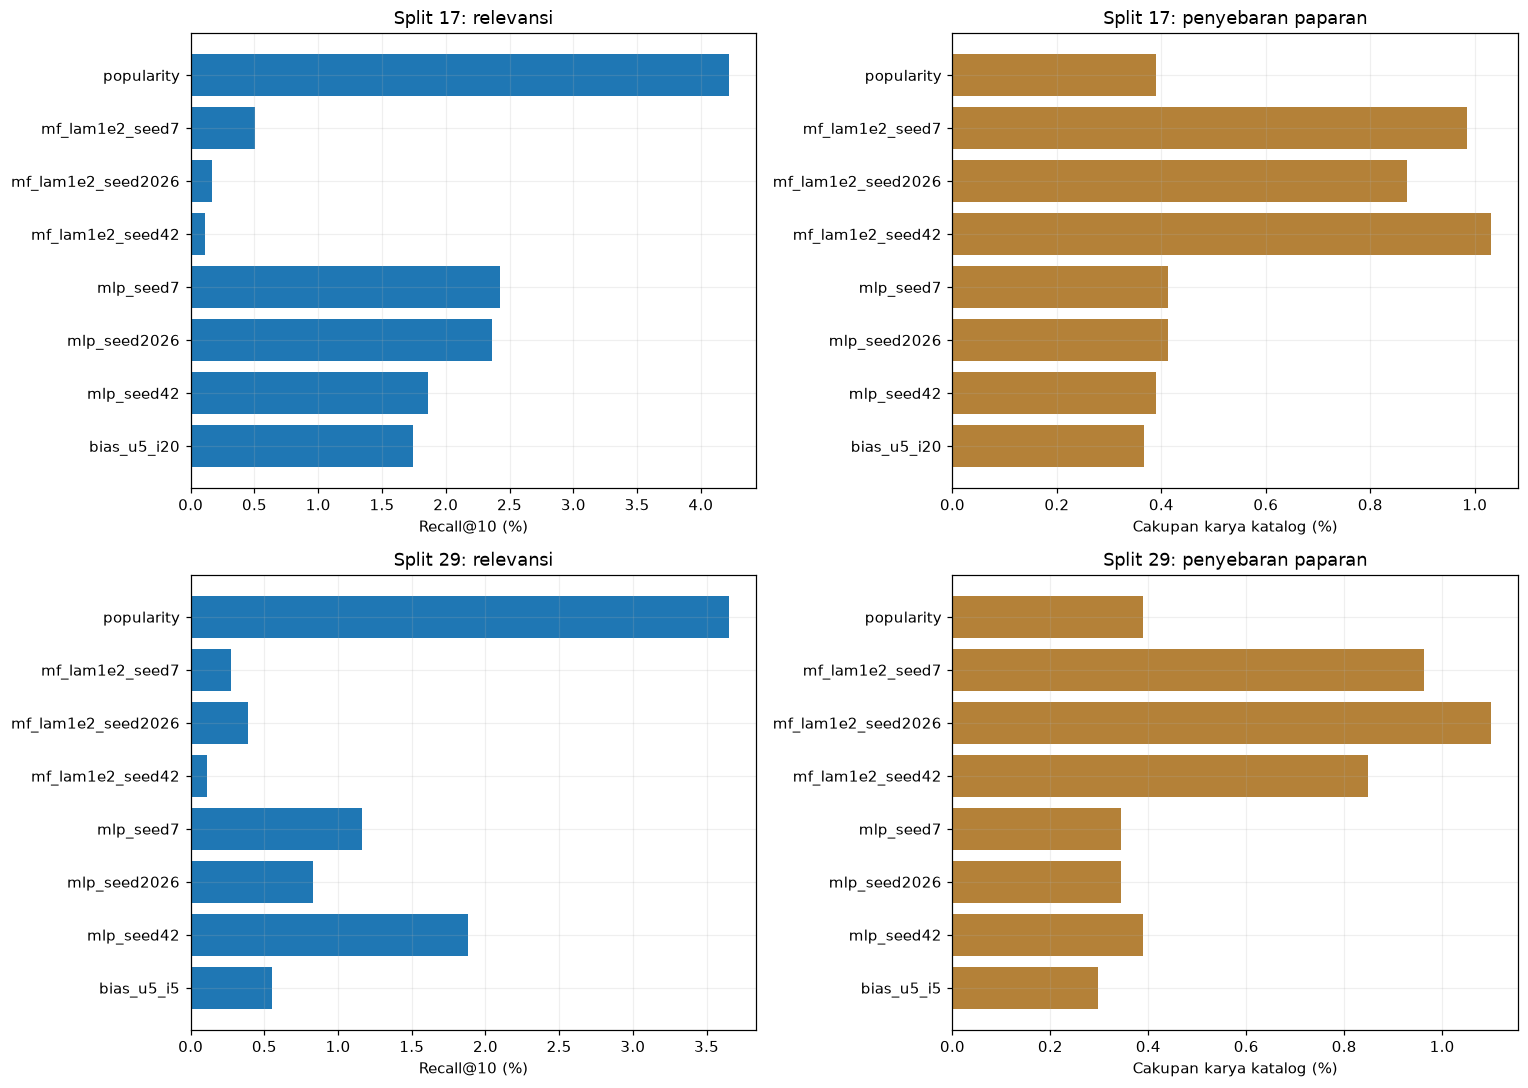

In [30]:
ranking_comparator_rows, ranking_cohorts, ranking_comparator_bootstrap_rows = [], [], []
for result in comparator["ranking_results"]:
    ranking_cohorts.append(
        {
            "split seed": result["split_seed"],
            "ISBN katalog": result["catalogue_isbns"],
            "karya katalog": result["catalogue_works"],
            "pengguna assessment": result["assessment_users"],
            "pengguna dengan target relevan": result["relevant_users"],
            "target tersedia": result["available_targets"],
            "cakupan target": result["target_coverage"],
            "pengguna dikenal": result["known_users"],
            "MLP utama": result["primary_mlp"],
            "MF utama": result["primary_mf"],
            "bias terpilih": result["bias_name"],
        }
    )
    for name, metric in result["metrics"].items():
        ranking_comparator_rows.append(
            {
                "split seed": result["split_seed"],
                "model": name,
                **metric,
                "model utama dari selection": name
                in (result["primary_mlp"], result["primary_mf"], result["bias_name"]),
            }
        )
    for comparison in result["paired_bootstrap"]:
        ranking_comparator_bootstrap_rows.append(
            {
                "split seed": result["split_seed"],
                "kandidat": comparison["model"],
                "referensi": comparison["reference"],
                "metrik": comparison["metric"],
                "pengguna": comparison["users"],
                "selisih metrik": comparison["difference"],
                "batas bawah 95%": comparison["ci95"][0],
                "batas atas 95%": comparison["ci95"][1],
                "bootstrap draws": comparison["draws"],
            }
        )
ranking_comparator = pd.DataFrame(ranking_comparator_rows)
ranking_comparator_bootstrap = pd.DataFrame(ranking_comparator_bootstrap_rows)
display(pd.DataFrame(ranking_cohorts))
display(ranking_comparator)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for row_index, split_seed in enumerate(comparator_config["split_seeds"]):
    frame = ranking_comparator[ranking_comparator["split seed"] == split_seed]
    labels = frame["model"].str.replace(f"split{split_seed}_", "", regex=False)
    axes[row_index, 0].barh(labels, frame["recall_at_10"] * 100)
    axes[row_index, 0].set(title=f"Split {split_seed}: relevansi", xlabel="Recall@10 (%)")
    axes[row_index, 1].barh(labels, frame["catalogue_coverage"] * 100, color="#b48138")
    axes[row_index, 1].set(
        title=f"Split {split_seed}: penyebaran paparan", xlabel="Cakupan karya katalog (%)"
    )
plt.tight_layout()
plt.show()

### Ketidakpastian ranking: arah selisih berbeda dari RMSE

Bootstrap berpasangan memakai pengguna yang sama pada kedua model. Untuk
Recall/NDCG/MRR, **selisih positif menguntungkan kandidat**, sedangkan pada
tabel RMSE selisih negatif menguntungkan kandidat. Semua interval berikut
bersyarat pada assessment internal yang sudah digunakan ulang, tanpa koreksi
banyak perbandingan; tidak digunakan untuk menyeleksi ulang model.

,split seed,kandidat,referensi,metrik,pengguna,selisih metrik,batas bawah 95%,batas atas 95%,bootstrap draws
0,17,split17_bias_u5_i20,popularity,recall_at_10,1776,-0.02477477,-0.03434685,-0.01632883,1000
1,17,split17_bias_u5_i20,popularity,ndcg_at_10,1776,-0.01292907,-0.01859175,-0.00778473,1000
2,17,split17_bias_u5_i20,popularity,mrr_at_10,1776,-0.00943823,-0.01450271,-0.00504936,1000
3,17,split17_bias_u5_i20,split17_mlp_seed42,recall_at_10,1776,-0.00112613,-0.00337838,0.00112613,1000
4,17,split17_bias_u5_i20,split17_mlp_seed42,ndcg_at_10,1776,-0.00107672,-0.00211640,-0.00006176,1000
5,17,split17_bias_u5_i20,split17_mlp_seed42,mrr_at_10,1776,-0.00104904,-0.00199942,-0.00010357,1000
6,17,split17_mlp_seed42,split17_bias_u5_i20,recall_at_10,1776,0.00112613,-0.00112613,0.00337838,1000
7,17,split17_mlp_seed42,split17_bias_u5_i20,ndcg_at_10,1776,0.00107672,0.00006176,0.00211640,1000
8,17,split17_mlp_seed42,split17_bias_u5_i20,mrr_at_10,1776,0.00104904,0.00010357,0.00199942,1000
9,17,split17_mlp_seed42,popularity,recall_at_10,1776,-0.02364865,-0.03322072,-0.01518863,1000


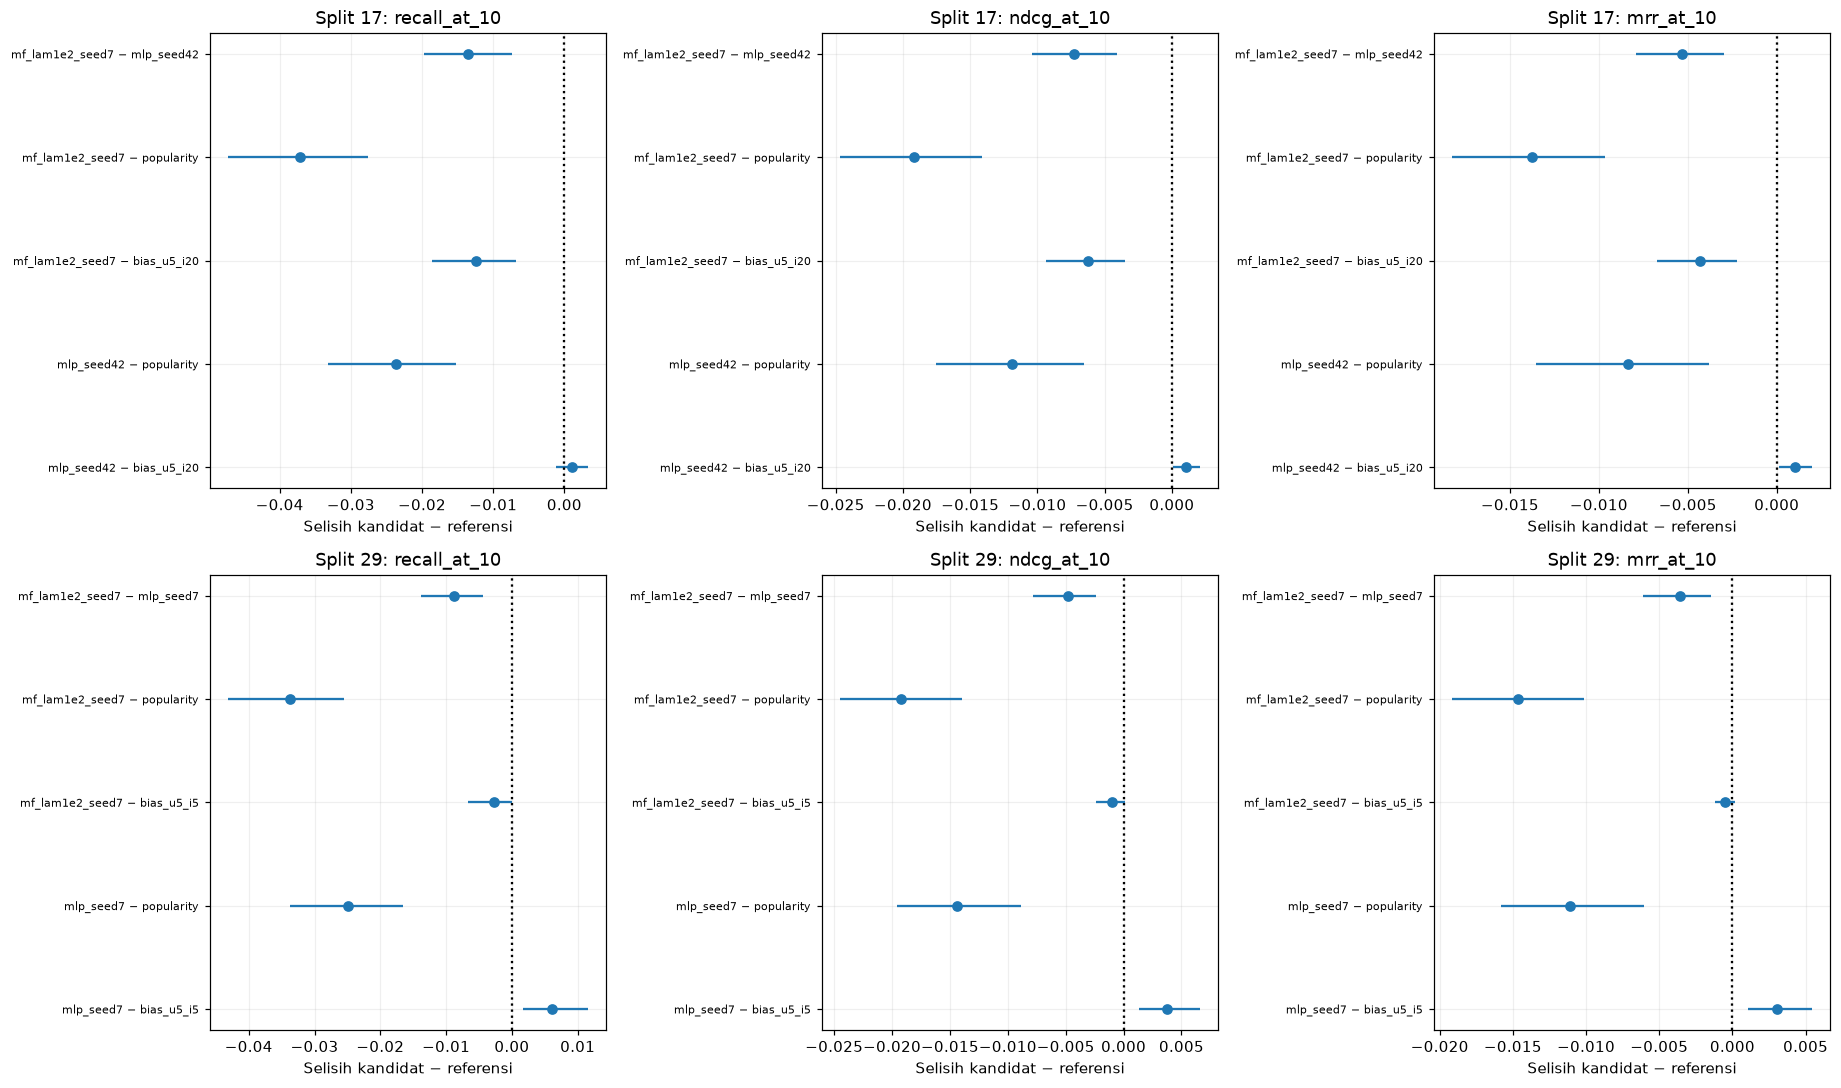

In [31]:
with pd.option_context("display.max_rows", None):
    display(ranking_comparator_bootstrap)
primary_ranking_comparisons = ranking_comparator_bootstrap[
    ranking_comparator_bootstrap.apply(
        lambda row: (
            row["kandidat"]
            in (
                comparator_selection[row["split seed"]]["primary_mf_candidate"],
                comparator_selection[row["split seed"]]["primary_mlp_candidate"],
            )
            and row["referensi"]
            in (
                comparator_selection[row["split seed"]]["bias_candidate"],
                "popularity",
                comparator_selection[row["split seed"]]["primary_mlp_candidate"],
            )
        ),
        axis=1,
    )
]
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
for row_index, split_seed in enumerate(comparator_config["split_seeds"]):
    for column_index, metric in enumerate(("recall_at_10", "ndcg_at_10", "mrr_at_10")):
        ax = axes[row_index, column_index]
        frame = primary_ranking_comparisons[
            (primary_ranking_comparisons["split seed"] == split_seed)
            & (primary_ranking_comparisons["metrik"] == metric)
        ]
        labels = (frame["kandidat"] + " − " + frame["referensi"]).str.replace(
            f"split{split_seed}_", "", regex=False
        )
        positions = range(len(frame))
        ax.hlines(positions, frame["batas bawah 95%"], frame["batas atas 95%"])
        ax.plot(frame["selisih metrik"], positions, "o")
        ax.axvline(0, color="black", linestyle=":")
        ax.set(
            yticks=list(positions),
            yticklabels=labels,
            title=f"Split {split_seed}: {metric}",
            xlabel="Selisih kandidat − referensi",
        )
        ax.tick_params(axis="y", labelsize=7)
plt.tight_layout()
plt.show()

## Ruang eksplorasi sampai run keenam (catatan historis)

Bagian ini mempertahankan diagnosis sebelum run ketujuh. Objective ranking,
embedding 32 pada arsitektur baru, dan metadata yang masih disebut usulan di
bawah kemudian diuji pada run ketujuh; lihat ringkasan terbaru di akhir dan
[notebook 04](04_neural_ranking_experiments.ipynb). Ini belum menjadi sweep
ukuran embedding pada arsitektur yang sama atau evaluasi cold-start.

Ruang pencarian masih terbatas. MLP/residual kini dibandingkan dengan MF
embedding dangkal dan bias yang dituning, tetapi ukuran embedding,
lebar jaringan, learning rate per arsitektur, dan batch size belum dituning. Run kelima
menambahkan variasi seed training dan split internal; itu belum menggantikan
konfirmasi pada data independen atau pengujian cold-start.
Run awal menemukan koreksi hampir konstan. Ablation berikutnya menguji L2 dan
inisialisasi head, lalu warm-up menguji training 12 epoch; tabel serta diagnosis di atas menyatakan hasilnya. Pencarian
tersebut belum menguji ukuran embedding atau data independen. Run keenam
menambahkan tuning bias/MF dan ranking pada assessment internal yang dipakai ulang.

L2 Keras dihitung sebagai `lambda * sum(square(weights))`; besarnya perlu
dinilai bersama MSE, jumlah bobot, dan gradient, bukan hanya angka lambda.
Hasil ablation perlu dibaca bersama perubahan variasi koreksi dan kualitas
validation. Mengurangi penyusutan bobot saja belum membuktikan neural lebih baik.
Sumber: [Keras regularizers](https://keras.io/api/layers/regularizers/).

In [32]:
display(
    pd.DataFrame(
        [
            ("Embedding", "16", "Belum membandingkan 8/32/64"),
            (
                "Hidden units",
                "MLP/residual 32,16; MF dot product tanpa hidden MLP",
                "Belum sweep kapasitas MLP",
            ),
            (
                "Learning rate Adam",
                "MLP/residual 0.001; MF 0.005",
                "Belum sweep learning rate pada arsitektur yang sama",
            ),
            ("Batch size", "1024", "Belum dibandingkan batch lain"),
            (
                "L2 neural",
                "; ".join(f"{value:g}" for value in sorted({c["l2"] for c in ablation_neural})),
                "Satu seed/split; kekuatan regularisasi belum terkonfirmasi lintas split",
            ),
            (
                "Inisialisasi head residual",
                "Nol; acak kecil pada L2 1e-6",
                "Satu pasangan ablation terkontrol, bukan pencarian semua kombinasi",
            ),
            (
                "Durasi training residual",
                "Patience 3; L2 0/1e-7 juga 12 epoch tetap tanpa early stopping",
                "Warm-up adaptif pada validation lama; belum replikasi independen",
            ),
            (
                "Residual scale",
                "0.25 dan 1.0; kontrol 0",
                "Scale tetap pada run ablation; belum interaksi scale × learning rate",
            ),
            (
                "Bias shrinkage",
                "Joint bias: user × buku dari {0,5,20,100}, 16 kombinasi/split",
                "Grid terbatas dan assessment pengembangan telah dipakai ulang",
            ),
            (
                "Regularisasi MF",
                "Lambda sampled-pair 1e-4/1e-3/1e-2, 3 seed/split",
                "Tidak sebanding langsung dengan L2 atas seluruh matriks embedding",
            ),
            (
                "Objective",
                "MSE rating dengan regularisasi; ranking kini dievaluasi",
                "Belum melatih objective ranking",
            ),
            (
                "Seed / split",
                "Run 1–4: seed 42, split lama; run 5–6: training 42/2026/7 × split 17/29",
                "Dua split berasal dari train lama; bukan dataset independen",
            ),
            ("Fitur neural", "ID user dan ISBN", "Belum ada metadata untuk cold-start"),
        ],
        columns=["aspek", "sudah dicoba", "batas eksplorasi"],
    )
)

,aspek,sudah dicoba,batas eksplorasi
0,Embedding,16,Belum membandingkan 8/32/64
1,Hidden units,"MLP/residual 32,16; MF dot product tanpa hidden MLP",Belum sweep kapasitas MLP
2,Learning rate Adam,MLP/residual 0.001; MF 0.005,Belum sweep learning rate pada arsitektur yang sama
3,Batch size,1024,Belum dibandingkan batch lain
4,L2 neural,0; 1e-07; 1e-06; 1e-05; 0.0001,Satu seed/split; kekuatan regularisasi belum terkonfirmasi lintas split
5,Inisialisasi head residual,Nol; acak kecil pada L2 1e-6,"Satu pasangan ablation terkontrol, bukan pencarian semua kombinasi"
6,Durasi training residual,Patience 3; L2 0/1e-7 juga 12 epoch tetap tanpa early stopping,Warm-up adaptif pada validation lama; belum replikasi independen
7,Residual scale,0.25 dan 1.0; kontrol 0,Scale tetap pada run ablation; belum interaksi scale × learning rate
8,Bias shrinkage,"Joint bias: user × buku dari {0,5,20,100}, 16 kombinasi/split",Grid terbatas dan assessment pengembangan telah dipakai ulang
9,Regularisasi MF,"Lambda sampled-pair 1e-4/1e-3/1e-2, 3 seed/split",Tidak sebanding langsung dengan L2 atas seluruh matriks embedding


## Rencana setelah run keenam (sebagian dijalankan pada run ketujuh)

Urutan ini menguji hipotesis sebelum menambah kompleksitas. Angka di kolom
konfigurasi adalah usulan saat run keenam selesai, bukan hasil atau janji
peningkatan. Run ketujuh menguji BPR, selection berbasis NDCG, serta metadata;
usulan tuning lainnya dan test independen tetap belum dijalankan.

Diagnosis L2/head, kontrol kalibrasi skalar, dan overfit mini-batch sudah
dicatat di run ketiga; warm-up 12 epoch tetap dicatat di run keempat.
Run kelima memperbesar selection/assessment internal dan mengulang training
pada tiga seed training; run keenam menambahkan bias/MF yang dituning dan
ranking katalog penuh. Langkah berikutnya perlu mengikuti hasilnya dan
keterbatasan populasi warm yang dipakai.

1. **Sesuaikan training dengan daftar rekomendasi:** perbandingan katalog
   penuh masih dimenangkan popularity pada Recall/NDCG/MRR. Coba pasangan
   positif/negatif dengan BPR atau BCE dan negative sampling yang ditetapkan
   sebelum training. Gunakan metrik ranking pada selection untuk memilih
   checkpoint, lalu evaluasi assessment sekali. Pertahankan popularity dan
   bias yang dituning sebagai pembanding. Interaksi tidak teramati adalah
   kandidat negatif sampling yang tidak pasti; rating 0 bukan bukti tidak suka.
   BPR dirancang untuk personalized ranking pada implicit feedback
   ([Rendle dkk., BPR](https://arxiv.org/abs/1205.2618)).
2. **Perluas tuning secara terukur:** lambda MF terpilih 1e-2 berada di ujung
   atas grid dan seluruh MF memilih epoch 1; ini belum menunjukkan MF optimal.
   Uji regularisasi lebih kuat, learning rate lebih kecil, atau bias yang
   dibekukan sebagai ablation terpisah. Untuk MLP, embedding 8/16/32 dan
   learning rate 3e-4/1e-3/3e-3 masih usulan. Tetapkan anggaran dan pilihan
   berdasarkan selection, tanpa membuka assessment untuk memilih ulang.
3. **Konfirmasi dan tangani cakupan:** siapkan test independen yang tidak
   dibuka selama pengembangan. Pertahankan protokol karya kanonik serta
   pemisahan pengguna selection/assessment. Coba fitur judul/penulis/
   penerbit atau representasi karya untuk cold-start dan bandingkan dengan
   content/hybrid yang sudah ada. Metrik cold-start dilaporkan sendiri;
   menaikkan ukuran embedding ID saja tidak memberi representasi bagi ID
   yang tidak pernah dipelajari.

Setiap run baru perlu mencatat hipotesis, perubahan tunggal yang diuji,
konfigurasi, hash data/source, seed, durasi, semua epoch, kegagalan bila ada,
kriteria seleksi, dan hasil pada cohort yang jelas. Jangan membuka test untuk
setiap kandidat tuning. Log juga run yang gagal atau tidak mengungguli kontrol.

## Kesimpulan enam run pertama (catatan historis)

- **Tujuan pembelajaran tercapai:** implementasi neural dan bukti langkah
  training memperlihatkan embedding, forward propagation, loss,
  backpropagation, dan optimisasi pada proyek nyata.
- **Belum optimal:** ada ablation regularisasi, head, durasi training,
  tiga seed training, dua split internal, serta pembanding bias/MF yang
  dituning. Ukuran embedding, learning
  rate, objective ranking, serta fitur cold-start belum dituning. Run kelima
  menambah bukti pengembangan internal; tidak menyediakan test independen baru.
  Run keenam mengukur ranking pada assessment internal yang sudah digunakan ulang.
- **Keunggulan MLP bergantung pada kekuatan pembanding:** enam MLP pada run
  kelima mengungguli tiga kontrol awal. Setelah bias dituning pada run keenam,
  keunggulan itu tidak konsisten: selisih RMSE MLP utama terhadap bias pada
  split 17 kecil dan intervalnya melintasi nol; pada split 29 MLP lebih buruk.
  MF utama juga belum memperbaiki RMSE bias secara konsisten. Temuan lama
  tetap benar untuk kontrol lama, tetapi tidak cukup untuk menyatakan deep
  learning lebih unggul daripada pembanding yang dituning.
- **Prediksi rating belum menghasilkan ranking terbaik:** keenam MLP dan
  keenam MF yang dinilai untuk ranking memiliki Recall/NDCG/MRR@10 lebih
  rendah daripada popularity pada kedua split. MLP utama mendapatkan
  33/1.776 dan 21/1.806 hit, sedangkan popularity 75/1.776 dan 66/1.806.
  Interval Recall MLP utama dikurangi popularity seluruhnya negatif.
  Bias yang kuat untuk RMSE juga belum menjadi ranking terbaik; tujuan
  pemilihan checkpoint berikutnya harus sesuai dengan keluaran aplikasi.
- **L2 memengaruhi penyusutan embedding**, tetapi menghapus L2 belum memberi
  peningkatan validation yang berarti. Neural mampu menghafal mini-batch
  nyata; kemampuan itu berbeda dari generalisasi pada seluruh benchmark.
- **Warm-up pada run keempat sampai 12 epoch memperjelas overfitting:** train RMSE turun,
  validation memburuk, dan kedua checkpoint terbaik tetap epoch 1. Dalam
  batas percobaan ini, penghentian pada epoch 4 bukan penyebab utama kegagalan
  memperbaiki validation. Menambah durasi saja tidak didukung hasil run ini.
- **Hasil test historis tetap:** MLP terbaik pada validation belum terbaik
  pada test; residual awal mendekati bias-only dan kalah tipis dari kontrol
  itu pada test. Ranking neural awal belum mengalahkan item-based/popularity.
- **Data dapat dipakai, tetapi desain evaluasi dan cold-start penting:**
  mayoritas pengguna hanya punya sedikit interaksi, dan hanya 27% pasangan
  test memiliki kedua ID dikenal. Jangan menyamakan hasil fallback dengan
  keberhasilan embedding atau menganggap data tidak mendukung neural sama
  sekali.
- **Aplikasi tetap memakai baseline yang ada** sampai tambahan neural
  memberi manfaat yang terukur dan dapat diulang.

In [33]:
completed_neural_count = sum(candidate["epochs_completed"] > 0 for candidate in ablation_neural)
warmup_trained_count = sum(candidate["epochs_completed"] > 0 for candidate in warmup_candidates)
multiseed_trained_count = sum(
    candidate["epochs_completed"] > 0 for candidate in multiseed_candidates
)
historical_record_count = (
    len(experiments)
    + len(ablation_experiments)
    + len(warmup_experiments)
    + len(multiseed_experiments)
)
historical_deep_training_count = (
    4 + completed_neural_count + warmup_trained_count + multiseed_trained_count
)
historical_epoch_count = (
    len(epochs) + len(ablation_epochs) + len(warmup_epochs) + len(multiseed_epochs)
)
mf_trained_count = sum(candidate["epochs_completed"] > 0 for candidate in mf_candidates)
best_ablation_name = ablation["selection"]["best_neural_candidate"]
best_ablation = ablation_by_name[best_ablation_name]
best_ablation_metric = best_ablation["validation"]["rmse_rating_scale"]
control_validation = ablation_experiments[ablation_experiments["jenis"] != "neural"]
best_control_metric = control_validation["validation RMSE"].min()
best_restored_correction = ablation_corrections[
    (ablation_corrections["percobaan"] == best_ablation_name)
    & (ablation_corrections["tahap"] == "restored_best")
    & (ablation_corrections["cohort"] == "validation")
].iloc[0]
display(
    Markdown(
        f"**Total riwayat:** {historical_record_count + len(bias_grid) + len(mf_candidates)} catatan kandidat "
        f"dalam enam run, termasuk **{historical_deep_training_count} training deep MLP/residual** "
        f"dan **{mf_trained_count} training MF embedding dangkal**, dengan "
        f"**{historical_epoch_count + len(mf_epochs)} epoch** training embedding. "
        f"Lima run awal tetap menyimpan {historical_record_count} catatan dan {historical_epoch_count} epoch. "
        f"Run keenam menambah {len(bias_grid)} konfigurasi bias dan {len(mf_candidates)} percobaan MF; "
        f"{len(reused_mlps)} MLP yang dimuat ulang tidak dihitung sebagai training baru. "
        "Diagnosis mini-batch dicatat terpisah. "
        "Pengulangan konfigurasi pada run berbeda tetap dicatat sebagai percobaan, "
        "bukan dianggap konfigurasi unik.\n\n"
        f"**Hasil ablation:** neural terpilih **`{best_ablation_name}`**, "
        f"validation RMSE **{best_ablation_metric:.6f}**; "
        f"kontrol terbaik **{best_control_metric:.6f}**. "
        f"Selisih neural − kontrol **{best_ablation_metric - best_control_metric:+.6f}** "
        "(negatif berarti RMSE neural lebih kecil). "
        f"Std koreksi validation pada checkpoint terpilih "
        f"**{best_restored_correction['koreksi std']:.8f}** poin rating. "
        "Angka ini menilai variasi koreksi; manfaat prediksi dinilai terpisah lewat RMSE.\n\n"
        f"**Diagnosis kapasitas:** MSE mini-batch **{overfit['initial_mse']:.6f} → "
        f"{overfit['final_mse']:.6f}**, setelah **{overfit['updates_completed']}** update. "
        "Hasil ini bukan metrik generalisasi. **Run ablation tidak menjalankan test.**"
    )
)
strong_l2 = ablation_by_name["residual_l2_1e4_zero_head"]
without_l2 = ablation_by_name["residual_l2_0_zero_head"]
strong_restored = next(d for d in strong_l2["diagnostics"] if d["stage"] == "restored_best")
unregularized_restored = next(d for d in without_l2["diagnostics"] if d["stage"] == "restored_best")
unregularized_last = next(
    d for d in reversed(without_l2["diagnostics"]) if d["stage"] == "epoch_end"
)
display(
    Markdown(
        "**Interpretasi ablation yang terkontrol:** menghapus L2 dibanding 1e-4 "
        f"mengubah norma embedding pengguna checkpoint terbaik dari "
        f"**{strong_restored['embedding_norms']['user_l2']:.4f}** menjadi "
        f"**{unregularized_restored['embedding_norms']['user_l2']:.4f}**. "
        "Jadi regularisasi memang menekan bobot dalam konfigurasi ini. Namun "
        f"RMSE validation hanya membaik sebesar **"
        f"{strong_l2['validation']['rmse_rating_scale'] - without_l2['validation']['rmse_rating_scale']:.8f}**. "
        "Koreksi pada checkpoint terbaik masih hampir berupa offset bersama. "
        "Peningkatan variasi output belum memberi peningkatan rekomendasi yang meyakinkan. "
        f"Diagnosis mini-batch menurunkan MSE **{100 * overfit['relative_mse_reduction']:.4f}%**, "
        "sehingga jaringan dan optimizer terbukti mampu mempelajari data nyata berulang; "
        "desain evaluasi, objective, dan generalisasi masih perlu diperbaiki."
    )
)
display(
    Markdown(
        "**Sinyal yang mulai muncul terlambat:** tanpa L2, std koreksi validation "
        f"naik dari **{unregularized_restored['corrections']['validation']['std_rating']:.6f}** "
        f"pada checkpoint terbaik menjadi **{unregularized_last['corrections']['validation']['std_rating']:.6f}** "
        f"pada epoch **{unregularized_last['epoch']}**. "
        f"Train RMSE terakhir **{without_l2['history'][-1]['train_rmse']:.6f}**, "
        f"validation RMSE terakhir **{without_l2['history'][-1]['val_rmse']:.6f}**. "
        "Training berhenti karena validation belum mengalahkan epoch 1 selama tiga epoch. "
        "Temuan ini menjadi alasan tindak lanjut 12 epoch yang dicatat sebagai run keempat."
    )
)
best_warmup_name = warmup["selection"]["best_neural_candidate"]
best_warmup = warmup_by_name[best_warmup_name]
best_warmup_rmse = best_warmup["validation"]["rmse_rating_scale"]
display(
    Markdown(
        f"**Hasil warm-up 12 epoch:** **`{best_warmup_name}`**, checkpoint epoch "
        f"**{best_warmup['best_epoch']}**, validation RMSE **{best_warmup_rmse:.6f}**. "
        f"Selisih terhadap neural terbaik run ablation: "
        f"**{best_warmup_rmse - best_ablation_metric:+.6f}**; "
        f"terhadap MLP awal: **{best_warmup_rmse - experiments.iloc[0]['validation RMSE']:+.6f}**. "
        "Negatif berarti RMSE lebih kecil pada validation pengembangan yang sama. "
        "Semua kandidat dan seluruh epoch tetap ditampilkan, termasuk hasil yang memburuk. "
        "**Belum ada test atau ranking baru untuk model hasil warm-up.**"
    )
)
display(
    Markdown(
        "**Jawaban terhadap hipotesis early stopping:** kedua kandidat tetap memilih "
        "epoch 1 walaupun dilatih sampai epoch 12. Tanpa L2, train RMSE akhir "
        f"**{warmup_by_name['residual_l2_0_zero_head_fixed12']['history'][-1]['train_rmse']:.6f}**, "
        "sedangkan validation RMSE akhir "
        f"**{warmup_by_name['residual_l2_0_zero_head_fixed12']['history'][-1]['val_rmse']:.6f}**. "
        "Jaringan benar-benar mempelajari train, tetapi pembelajaran tambahan itu "
        "tidak berpindah menjadi peningkatan validation. Ini mendukung diagnosis "
        "overfitting pada rancangan saat ini, bukan kesimpulan bahwa data sama sekali "
        "tidak dapat digunakan untuk neural."
    )
)
display(Markdown("**Temuan run kelima pada assessment pengembangan internal:**"))
for split_seed in multiseed["configuration"]["split_seeds"]:
    summaries = {
        row["architecture"]: row
        for row in multiseed["seed_summary"]
        if row["split_seed"] == split_seed
    }
    bias_result = multiseed_by_name[f"split{split_seed}_bias"]["assessment"]["known_pairs"]
    global_result = multiseed_by_name[f"split{split_seed}_global_mean"]["assessment"]["known_pairs"]
    chosen_name = selection_by_split[split_seed]["best_neural_candidate"]
    chosen = multiseed_by_name[chosen_name]
    display(
        Markdown(
            f"**Split {split_seed}:** mean RMSE dari tiga seed training pada pasangan dikenal: "
            f"MLP **{summaries['mlp']['known_rmse_mean']:.6f} ± "
            f"{summaries['mlp']['known_rmse_std']:.6f} SD**, residual "
            f"**{summaries['residual']['known_rmse_mean']:.6f} ± "
            f"{summaries['residual']['known_rmse_std']:.6f} SD**; "
            f"kontrol mean global **{global_result['rmse_rating_scale']:.6f}** dan "
            f"bias **{bias_result['rmse_rating_scale']:.6f}**. "
            f"Neural yang dipilih **sebelum assessment**, `{chosen_name}`, "
            f"mendapat assessment RMSE **{chosen['assessment']['known_pairs']['rmse_rating_scale']:.6f}**. "
            "SD ini variasi bobot awal dan urutan mini-batch pada split yang sama, bukan interval kepercayaan."
        )
    )
display(
    Markdown(
        "Bandingkan besaran selisih dan interval bootstrap pengguna pada tabel run kelima, "
        "bukan hanya urutan rata-rata. Kedua split tetap dianalisis terpisah; tidak ada "
        "kandidat yang dipromosikan berdasarkan assessment ini. Cakupan warm yang tinggi "
        "berasal dari aturan pembagian data, bukan perbaikan penanganan cold-start."
    )
)
display(Markdown("**Temuan run keenam: model utama yang ditentukan sebelum assessment/ranking**"))
primary_comparator_rows = []
for ranking_result in comparator["ranking_results"]:
    split_seed = ranking_result["split_seed"]
    chosen = comparator_selection[split_seed]
    rating_result = next(
        row for row in comparator["assessment_results"] if row["split_seed"] == split_seed
    )
    for name, role in (
        (chosen["bias_candidate"], "Joint bias terpilih"),
        (chosen["primary_mf_candidate"], "MF utama dari selection"),
        (chosen["primary_mlp_candidate"], "MLP utama dari selection"),
        ("popularity", "Popularity dari fit"),
    ):
        ranking_metric = ranking_result["metrics"][name]
        rating_metric = rating_result["models"].get(name, {}).get("known_pairs", {})
        primary_comparator_rows.append(
            {
                "split seed": split_seed,
                "peran": role,
                "model": name,
                "assessment RMSE": rating_metric.get("rmse_rating_scale"),
                "ranking pengguna relevan": ranking_metric["users"],
                "hits@10": ranking_metric["hits_at_10"],
                "Recall@10": ranking_metric["recall_at_10"],
                "NDCG@10": ranking_metric["ndcg_at_10"],
                "MRR@10": ranking_metric["mrr_at_10"],
                "cakupan karya katalog": ranking_metric["catalogue_coverage"],
                "entropy frekuensi ternormalisasi": ranking_metric["normalized_frequency_entropy"],
            }
        )
display(pd.DataFrame(primary_comparator_rows).fillna("tidak dinilai"))
for split_seed, chosen in comparator_selection.items():
    rating_ci = comparator_rating_bootstrap[
        (comparator_rating_bootstrap["split seed"] == split_seed)
        & (comparator_rating_bootstrap["cohort"] == "known_pairs")
        & (comparator_rating_bootstrap["kandidat"] == chosen["primary_mlp_candidate"])
        & (comparator_rating_bootstrap["referensi"] == chosen["bias_candidate"])
    ].iloc[0]
    ranking_ci = ranking_comparator_bootstrap[
        (ranking_comparator_bootstrap["split seed"] == split_seed)
        & (ranking_comparator_bootstrap["metrik"] == "recall_at_10")
        & (ranking_comparator_bootstrap["kandidat"] == chosen["primary_mlp_candidate"])
        & (ranking_comparator_bootstrap["referensi"] == "popularity")
    ].iloc[0]
    display(
        Markdown(
            f"**Split {split_seed}: MLP utama dibanding pembanding kuat.** "
            f"Selisih RMSE terhadap `{chosen['bias_candidate']}` "
            f"**{rating_ci['selisih RMSE']:+.6f}**, interval bootstrap pengguna 95% "
            f"**[{rating_ci['batas bawah 95%']:+.6f}, {rating_ci['batas atas 95%']:+.6f}]**. "
            "Negatif menguntungkan MLP. "
            f"Selisih Recall@10 terhadap popularity "
            f"**{100 * ranking_ci['selisih metrik']:+.3f} poin persentase**, interval 95% "
            f"**[{100 * ranking_ci['batas bawah 95%']:+.3f}, "
            f"{100 * ranking_ci['batas atas 95%']:+.3f}] poin persentase**. "
            "Untuk Recall, positif menguntungkan MLP. Interval bersyarat pada "
            "assessment yang dipakai ulang, tanpa koreksi banyak perbandingan."
        )
    )
display(
    Markdown(
        f"**Diagnosis run keenam:** {sum(row['converged'] for row in bias_grid)}/{len(bias_grid)} "
        "konfigurasi bias mencapai toleransi konvergensi. "
        f"Seluruh {len(mf_candidates)} MF selesai dengan best epoch "
        f"{sorted({row['best_epoch'] for row in mf_candidates})} dan jumlah epoch "
        f"{sorted({row['epochs_completed'] for row in mf_candidates})}; "
        "lambda terpilih 1e-2 adalah batas atas grid. Variasi faktor dan bias yang "
        "dapat dilatih belum menunjukkan perbaikan RMSE dan ranking yang konsisten "
        "terhadap bias yang dituning pada rancangan ini. Cakupan paparan MF yang lebih besar juga tidak menaikkan "
        "relevansi top-10. Ini membatasi klaim hasil run ini, bukan seluruh kemungkinan MF."
    )
)
display(
    Markdown(
        "Tabel ringkas ini mempertahankan pilihan dari selection; tidak memilih model menurut "
        "hasil ranking atau assessment. Seluruh seed, lambda, dan interval tetap tersedia di "
        "bagian run keenam. RMSE yang lebih kecil dan ranking yang lebih baik adalah dua "
        "hasil berbeda yang perlu dinilai masing-masing. Ranking hanya mengamati satu "
        "target holdout relevan per pengguna; karya lain yang tidak dinilai bukan negatif "
        "yang diketahui. Assessment yang dipakai ulang, "
        "pengguna warm, serta katalog tetap membatasi generalisasi; tidak ada promosi ke aplikasi."
    )
)

**Total riwayat:** 83 catatan kandidat dalam enam run, termasuk **24 training deep MLP/residual** dan **18 training MF embedding dangkal**, dengan **248 epoch** training embedding. Lima run awal tetap menyimpan 33 catatan dan 140 epoch. Run keenam menambah 32 konfigurasi bias dan 18 percobaan MF; 6 MLP yang dimuat ulang tidak dihitung sebagai training baru. Diagnosis mini-batch dicatat terpisah. Pengulangan konfigurasi pada run berbeda tetap dicatat sebagai percobaan, bukan dianggap konfigurasi unik.

**Hasil ablation:** neural terpilih **`residual_l2_0_zero_head`**, validation RMSE **1.746581**; kontrol terbaik **1.747000**. Selisih neural − kontrol **-0.000420** (negatif berarti RMSE neural lebih kecil). Std koreksi validation pada checkpoint terpilih **0.00100437** poin rating. Angka ini menilai variasi koreksi; manfaat prediksi dinilai terpisah lewat RMSE.

**Diagnosis kapasitas:** MSE mini-batch **0.026764 → 0.000043**, setelah **150** update. Hasil ini bukan metrik generalisasi. **Run ablation tidak menjalankan test.**

**Interpretasi ablation yang terkontrol:** menghapus L2 dibanding 1e-4 mengubah norma embedding pengguna checkpoint terbaik dari **0.0716** menjadi **14.2932**. Jadi regularisasi memang menekan bobot dalam konfigurasi ini. Namun RMSE validation hanya membaik sebesar **0.00002307**. Koreksi pada checkpoint terbaik masih hampir berupa offset bersama. Peningkatan variasi output belum memberi peningkatan rekomendasi yang meyakinkan. Diagnosis mini-batch menurunkan MSE **99.8411%**, sehingga jaringan dan optimizer terbukti mampu mempelajari data nyata berulang; desain evaluasi, objective, dan generalisasi masih perlu diperbaiki.

**Sinyal yang mulai muncul terlambat:** tanpa L2, std koreksi validation naik dari **0.001004** pada checkpoint terbaik menjadi **0.035269** pada epoch **4**. Train RMSE terakhir **1.349462**, validation RMSE terakhir **1.746759**. Training berhenti karena validation belum mengalahkan epoch 1 selama tiga epoch. Temuan ini menjadi alasan tindak lanjut 12 epoch yang dicatat sebagai run keempat.

**Hasil warm-up 12 epoch:** **`residual_l2_0_zero_head_fixed12`**, checkpoint epoch **1**, validation RMSE **1.746581**. Selisih terhadap neural terbaik run ablation: **+0.000000**; terhadap MLP awal: **+0.125563**. Negatif berarti RMSE lebih kecil pada validation pengembangan yang sama. Semua kandidat dan seluruh epoch tetap ditampilkan, termasuk hasil yang memburuk. **Belum ada test atau ranking baru untuk model hasil warm-up.**

**Jawaban terhadap hipotesis early stopping:** kedua kandidat tetap memilih epoch 1 walaupun dilatih sampai epoch 12. Tanpa L2, train RMSE akhir **0.667793**, sedangkan validation RMSE akhir **2.098561**. Jaringan benar-benar mempelajari train, tetapi pembelajaran tambahan itu tidak berpindah menjadi peningkatan validation. Ini mendukung diagnosis overfitting pada rancangan saat ini, bukan kesimpulan bahwa data sama sekali tidak dapat digunakan untuk neural.

...

,split seed,peran,model,assessment RMSE,ranking pengguna relevan,hits@10,Recall@10,NDCG@10,MRR@10,cakupan karya katalog,entropy frekuensi ternormalisasi
0,17,Joint bias terpilih,split17_bias_u5_i20,1.63478613,1776,31,0.01745495,0.00803758,0.00517035,0.00366636,0.27927492
1,17,MF utama dari selection,split17_mf_lam1e2_seed7,1.63633757,1776,9,0.00506757,0.00181088,0.00086873,0.00985335,0.34729261
2,17,MLP utama dari selection,split17_mlp_seed42,1.62709961,1776,33,0.01858108,0.00911430,0.00621939,0.00389551,0.27958277
3,17,Popularity dari fit,popularity,tidak dinilai,1776,75,0.04222973,0.02096665,0.01460858,0.00389551,0.28274885
4,29,Joint bias terpilih,split29_bias_u5_i5,1.57939556,1806,10,0.00553710,0.00218406,0.00116345,0.00297892,0.27654035
5,29,MF utama dari selection,split29_mf_lam1e2_seed7,1.59568553,1806,5,0.00276855,0.00114224,0.00066138,0.00962420,0.33253145
6,29,MLP utama dari selection,split29_mlp_seed7,1.60103538,1806,21,0.01162791,0.00593662,0.00421347,0.00343721,0.27981188
7,29,Popularity dari fit,popularity,tidak dinilai,1806,66,0.03654485,0.02033018,0.01532062,0.00389551,0.28281725


**Split 17: MLP utama dibanding pembanding kuat.** Selisih RMSE terhadap `split17_bias_u5_i20` **-0.007687**, interval bootstrap pengguna 95% **[-0.019485, +0.004894]**. Negatif menguntungkan MLP. Selisih Recall@10 terhadap popularity **-2.365 poin persentase**, interval 95% **[-3.322, -1.519] poin persentase**. Untuk Recall, positif menguntungkan MLP. Interval bersyarat pada assessment yang dipakai ulang, tanpa koreksi banyak perbandingan.

**Split 29: MLP utama dibanding pembanding kuat.** Selisih RMSE terhadap `split29_bias_u5_i5` **+0.021640**, interval bootstrap pengguna 95% **[+0.007074, +0.037743]**. Negatif menguntungkan MLP. Selisih Recall@10 terhadap popularity **-2.492 poin persentase**, interval 95% **[-3.378, -1.661] poin persentase**. Untuk Recall, positif menguntungkan MLP. Interval bersyarat pada assessment yang dipakai ulang, tanpa koreksi banyak perbandingan.

**Diagnosis run keenam:** 32/32 konfigurasi bias mencapai toleransi konvergensi. Seluruh 18 MF selesai dengan best epoch [1] dan jumlah epoch [6]; lambda terpilih 1e-2 adalah batas atas grid. Variasi faktor dan bias yang dapat dilatih belum menunjukkan perbaikan RMSE dan ranking yang konsisten terhadap bias yang dituning pada rancangan ini. Cakupan paparan MF yang lebih besar juga tidak menaikkan relevansi top-10. Ini membatasi klaim hasil run ini, bukan seluruh kemungkinan MF.

Tabel ringkas ini mempertahankan pilihan dari selection; tidak memilih model menurut hasil ranking atau assessment. Seluruh seed, lambda, dan interval tetap tersedia di bagian run keenam. RMSE yang lebih kecil dan ranking yang lebih baik adalah dua hasil berbeda yang perlu dinilai masing-masing. Ranking hanya mengamati satu target holdout relevan per pengguna; karya lain yang tidak dinilai bukan negatif yang diketahui. Assessment yang dipakai ulang, pengguna warm, serta katalog tetap membatasi generalisasi; tidak ada promosi ke aplikasi.

## Run ketujuh: objective ranking dan metadata

Run ini menindaklanjuti masalah ranking melalui tiga kelompok neural dua
menara: MSE dengan ID, BPR dengan ID, dan BPR dengan ID + metadata. Seluruhnya
dipilih memakai NDCG@10 selection atas katalog penuh. Dua split internal dan
tiga seed per kelompok menghasilkan 18 rencana training baru. Semua hasil,
epoch, loss, bukti gradien, variasi seed, cohort, dan bootstrap tersedia di
**[notebook 04 — Neural Ranking Experiments](04_neural_ranking_experiments.ipynb)**.

MSE dan BPR mengubah objective sekaligus supervisi; perbandingan keduanya
tidak mengisolasi efek loss saja. Tambahan metadata dibandingkan pada BPR
yang sama. Unit buku kini karya kanonik; MLP historis berbasis ISBN tetap
benchmark, bukan kontrol arsitektur identik. Assessment internal dipakai
ulang dari run terdahulu dan tidak menjadi test independen.

**Hasil run ketujuh:** BPR ID utama menemukan target pada 72/1.776 dan 72/1.806
pengguna, meningkat dari MLP lama 33/1.776 dan 21/1.806. Popularitas mendapat
75/1.776 dan 66/1.806. Neural kini mendekati popularitas, tetapi interval
selisih Recall/NDCG BPR utama terhadap popularitas melintasi nol pada kedua
split; belum ada keunggulan yang konsisten atau bukti kesetaraan.

Pada cohort riwayat positif bersama, kenaikan NDCG BPR terhadap MLP lama tetap
terlihat, sehingga perbaikan bukan hanya fallback. Arsitektur/unit karya/seleksi
checkpoint juga berubah; efek masing-masing belum dipisahkan pada perbandingan lama/baru. BPR ID
mengungguli MSE ID pada NDCG di semua enam pasangan seed yang dicocokkan, tetapi
hanya dua interval seluruhnya di atas nol. Tambahan metadata belum konsisten:
dua selisih NDCG positif dan empat negatif dibandingkan BPR ID yang dipasangkan;
model metadata utama menemukan 67 dan 70 target. Seluruh interval dan batas
interpretasi ditampilkan dalam notebook 04.

In [34]:
ranking_run = evidence["ranking"]
ranking_run_manifest = evidence["ranking_manifest"]
ranking_new_candidates = ranking_run["candidate_validation_results"]
ranking_new_epochs = sum(candidate["epochs_completed"] for candidate in ranking_new_candidates)
ranking_trained_count = sum(
    candidate["epochs_completed"] > 0 for candidate in ranking_new_candidates
)
ranking_primary_rows = []
for ranking_result in ranking_run["ranking_results"]:
    primary_models = [
        *ranking_result["primary_models"].items(),
        ("MLP lama", ranking_result["old_primary_mlp"]),
        ("Popularitas", "popularity"),
    ]
    for arm, name in primary_models:
        overall = ranking_result["metrics"][name]["all_relevant"]
        positive = ranking_result["metrics"][name]["fit_positive_history"]
        ranking_primary_rows.append(
            {
                "split": ranking_result["split_seed"],
                "model utama": arm,
                "kandidat": name,
                "target ditemukan": f"{overall['hits_at_10']}/{overall['users']}",
                "Recall@10": overall["recall_at_10"],
                "NDCG@10": overall["ndcg_at_10"],
                "target ditemukan (riwayat positif)": f"{positive['hits_at_10']}/{positive['users']}",
                "NDCG@10 riwayat positif": positive["ndcg_at_10"],
            }
        )
display(pd.DataFrame(ranking_primary_rows))
display(
    pd.DataFrame(
        [
            {
                "kandidat": candidate["name"],
                "kelompok": candidate["arm"],
                "split": candidate["split_seed"],
                "seed training": candidate["initialization_seed"],
                "status": candidate["status"],
                "epoch selesai": candidate["epochs_completed"],
                "epoch pilihan selection": candidate["best_epoch"],
                "selection NDCG@10": candidate["selection"]["all_relevant"]["ndcg_at_10"],
                "selection Recall@10": candidate["selection"]["all_relevant"]["recall_at_10"],
            }
            for candidate in ranking_new_candidates
        ]
    )
)
display(
    Markdown(
        f"**Total kumulatif tujuh run:** "
        f"**{historical_record_count + len(bias_grid) + len(mf_candidates) + len(ranking_new_candidates)} "
        f"catatan kandidat**, "
        f"**{historical_deep_training_count + ranking_trained_count} training deep neural** "
        f"dan **{mf_trained_count} training MF embedding dangkal**, "
        f"dengan **{historical_epoch_count + len(mf_epochs) + ranking_new_epochs} epoch**. "
        f"Run ketujuh menambah {len(ranking_new_candidates)} catatan, "
        f"{ranking_trained_count} training dengan sedikitnya satu epoch, "
        f"dan {ranking_new_epochs} epoch. MLP dan popularitas yang dipakai ulang "
        "sebagai benchmark tidak dihitung sebagai training baru. "
        "Diagnosis mini-batch tetap dicatat terpisah.\n\n"
        "Hasil assessment terbaru dan batas kesimpulannya disajikan di notebook 04. "
        "Kesimpulan enam run pertama di atas dipertahankan sebagai catatan "
        "historis sehingga alasan setiap tindak lanjut tetap dapat ditelusuri."
    )
)

,split,model utama,kandidat,target ditemukan,Recall@10,NDCG@10,target ditemukan (riwayat positif),NDCG@10 riwayat positif
0,17,mse_id,split17_mse_id_seed7,57/1776,0.03209459,0.01763769,47/1513,0.01714416
1,17,bpr_id,split17_bpr_id_seed42,72/1776,0.04054054,0.02008785,62/1513,0.02002022
2,17,bpr_metadata,split17_bpr_metadata_seed7,67/1776,0.03772523,0.01913231,57/1513,0.01889858
3,17,MLP lama,split17_mlp_seed42,33/1776,0.01858108,0.00911430,30/1513,0.00938524
4,17,Popularitas,popularity,75/1776,0.04222973,0.02096665,65/1513,0.02105178
5,29,mse_id,split29_mse_id_seed42,59/1806,0.03266888,0.01720086,50/1502,0.01647080
6,29,bpr_id,split29_bpr_id_seed2026,72/1806,0.03986711,0.02043383,63/1502,0.02035811
7,29,bpr_metadata,split29_bpr_metadata_seed2026,70/1806,0.03875969,0.01987819,61/1502,0.01969001
8,29,MLP lama,split29_mlp_seed7,21/1806,0.01162791,0.00593662,20/1502,0.00693775
9,29,Popularitas,popularity,66/1806,0.03654485,0.02033018,57/1502,0.02023348


,kandidat,kelompok,split,seed training,status,epoch selesai,epoch pilihan selection,selection NDCG@10,selection Recall@10
0,split17_mse_id_seed42,mse_id,17,42,completed,5,2,0.01102660,0.02172702
1,split17_bpr_id_seed42,bpr_id,17,42,completed,4,1,0.01748931,0.03342618
2,split17_bpr_metadata_seed42,bpr_metadata,17,42,completed,6,3,0.01685991,0.03119777
3,split17_mse_id_seed2026,mse_id,17,2026,completed,4,1,0.01319710,0.02896936
4,split17_bpr_id_seed2026,bpr_id,17,2026,completed,12,10,0.01698712,0.03398329
5,split17_bpr_metadata_seed2026,bpr_metadata,17,2026,completed,9,6,0.01671738,0.03231198
6,split17_mse_id_seed7,mse_id,17,7,completed,4,1,0.01386923,0.02618384
7,split17_bpr_id_seed7,bpr_id,17,7,completed,6,3,0.01710088,0.03286908
8,split17_bpr_metadata_seed7,bpr_metadata,17,7,completed,6,3,0.01706972,0.03286908
9,split29_mse_id_seed42,mse_id,29,42,completed,4,1,0.01445702,0.02997738


**Total kumulatif tujuh run:** **101 catatan kandidat**, **42 training deep neural** dan **18 training MF embedding dangkal**, dengan **354 epoch**. Run ketujuh menambah 18 catatan, 18 training dengan sedikitnya satu epoch, dan 106 epoch. MLP dan popularitas yang dipakai ulang sebagai benchmark tidak dihitung sebagai training baru. Diagnosis mini-batch tetap dicatat terpisah.

Hasil assessment terbaru dan batas kesimpulannya disajikan di notebook 04. Kesimpulan enam run pertama di atas dipertahankan sebagai catatan historis sehingga alasan setiap tindak lanjut tetap dapat ditelusuri.

## Run kedelapan: membaca riwayat positif secara langsung

Diagnosis sesudah run ketujuh menemukan tumpang tindih tinggi antara BPR ID
dan popularitas. Ini menjadi alasan menguji representasi pengguna dari
himpunan karya positif fit, disertai pembanding klasik cosine pada riwayat
yang sama. Target training dikeluarkan dari riwayat sebelum pooling.
Dua objective, BPR dan full softmax, memakai arsitektur dan target yang sama
pada dua split dan tiga seed: 12 rencana training neural. Grid tetangga
50/200 × shrinkage 0/10 menambah delapan catatan konfigurasi klasik.

Checkpoint dipilih melalui NDCG selection, lalu model dikunci sebelum
assessment run ini. Diagnosis tambahan menukar riwayat pada model utama
tanpa melatih ulang dan mempertahankan exclusion milik penerima rekomendasi.
Pertukaran memengaruhi isi sekaligus panjang riwayat; ia memeriksa sensitivitas
masukan, bukan mengisolasi efek kausal isi. Assessment tetap data pengembangan
yang dipakai ulang. Seluruh kandidat, epoch, lima cohort, ketidakpastian,
diagnosis, serta hasil ringkas tersedia di
**[notebook 05 — Neural History Experiments](05_neural_history_experiments.ipynb)**.

**Hasil run kedelapan:** cosine riwayat terpilih menemukan 191/1.776 dan
198/1.806 target, dibanding popularitas 75/1.776 dan 66/1.806. Ini menunjukkan
sinyal rekomendasi yang berguna dalam data pengembangan. Neural softmax utama
menemukan 109 dan 66 target; history-BPR utama 70 dan 67; BPR ID historis 72
pada kedua split. Keunggulan neural tidak konsisten, dan semua neural utama
masih kalah dari cosine terpilih pada NDCG cohort positif.

Pertukaran riwayat mengubah hit softmax utama split 17 dari 109 menjadi 48,
tetapi split 29 tetap 66. Kegunaan riwayat asli tampak pada checkpoint split 17;
hasil itu tidak boleh digeneralisasikan ke seluruh model. Pemilihan tetap
melalui selection, assessment dipakai ulang, dan tidak ada promosi aplikasi
atau klaim test independen. Rincian ketidakpastian ada di notebook 05.

In [35]:
history_run = evidence["history"]
history_manifest = evidence["history_manifest"]
history_diagnosis = evidence["personalization_diagnosis"]
history_candidates = history_run["candidate_validation_results"]
history_baselines = history_run["baseline_grid_results"]
history_epoch_count = sum(candidate["epochs_completed"] for candidate in history_candidates)
history_deep_count = sum(candidate["epochs_completed"] > 0 for candidate in history_candidates)
display(
    pd.DataFrame(
        [
            {
                "split": split["split_seed"],
                "BPR ID historis": split["primary_bpr"],
                "cohort": "riwayat positif",
                "top-1 sama dengan popularitas (%)": 100 * split["overlap"]["positive"]["same_top1"]
                / split["overlap"]["positive"]["users"],
                "rata-rata karya sama di top-10": split["overlap"]["positive"]["mean_common_top10"],
            }
            for split in history_diagnosis["splits"]
        ]
    )
)
history_primary_rows = []
for ranking_result in history_run["ranking_results"]:
    primary_models = [
        *ranking_result["primary_models"].items(),
        ("Cosine riwayat", ranking_result["baseline_name"]),
        ("BPR ID lama", ranking_result["previous_primary_models"]["bpr_id"]),
        ("Popularitas", "popularity"),
    ]
    for label, name in primary_models:
        overall = ranking_result["metrics"][name]["all_relevant"]
        positive = ranking_result["metrics"][name]["fit_positive_history"]
        multiple = ranking_result["metrics"][name]["multiple_fit_positive"]
        history_primary_rows.append(
            {
                "split": ranking_result["split_seed"], "model utama": label, "kandidat": name,
                "target ditemukan": f"{overall['hits_at_10']}/{overall['users']}",
                "Recall@10": overall["recall_at_10"], "NDCG@10": overall["ndcg_at_10"],
                "NDCG@10 riwayat positif": positive["ndcg_at_10"],
                "NDCG@10 minimal 2 positif": multiple["ndcg_at_10"],
            }
        )
display(pd.DataFrame(history_primary_rows))
display(
    pd.DataFrame(
        [
            {
                "kandidat": candidate["name"], "split": candidate["split_seed"],
                "jenis": candidate["kind"], "status": candidate["status"],
                "epoch selesai": candidate.get("epochs_completed"),
                "epoch terbaik": candidate.get("best_epoch"),
                "selection NDCG@10": candidate["selection"]["all_relevant"]["ndcg_at_10"],
                "selection Recall@10": candidate["selection"]["all_relevant"]["recall_at_10"],
            }
            for candidate in [*history_candidates, *history_baselines]
        ]
    ).fillna("tidak berlaku untuk cosine")
)
display(
    Markdown(
        f"**Total kumulatif delapan run:** "
        f"**{historical_record_count + len(bias_grid) + len(mf_candidates) + len(ranking_new_candidates) + len(history_candidates) + len(history_baselines)} "
        f"catatan kandidat**, "
        f"**{historical_deep_training_count + ranking_trained_count + history_deep_count} training deep neural** "
        f"dan **{mf_trained_count} training MF embedding dangkal**, "
        f"dengan **{historical_epoch_count + len(mf_epochs) + ranking_new_epochs + history_epoch_count} epoch**. "
        f"Run kedelapan menambah {len(history_candidates)} catatan neural dan "
        f"{len(history_baselines)} konfigurasi cosine, dengan {history_epoch_count} epoch neural. "
        f"{len(history_run['history_shuffle_results'])} diagnosis pertukaran riwayat dan "
        "analisis personalisasi dari rekomendasi tersimpan tidak dihitung sebagai training baru. "
        "Seluruh seed, cohort, interval bootstrap, dan hasil diagnosis tersedia di notebook 05."
    )
)

,split,BPR ID historis,cohort,top-1 sama dengan popularitas (%),rata-rata karya sama di top-10
0,17,split17_bpr_id_seed42,riwayat positif,99.73562459,7.13350958
1,29,split29_bpr_id_seed2026,riwayat positif,97.60319574,6.92343542


,split,model utama,kandidat,target ditemukan,Recall@10,NDCG@10,NDCG@10 riwayat positif,NDCG@10 minimal 2 positif
0,17,history_bpr,split17_history_bpr_seed7,70/1776,0.03941441,0.02122022,0.02134943,0.02229762
1,17,history_softmax,split17_history_softmax_seed2026,109/1776,0.06137387,0.03319073,0.03540074,0.03991468
2,17,Cosine riwayat,split17_itemcos_k50_shrink10,191/1776,0.10754505,0.06752197,0.07569967,0.09174336
3,17,BPR ID lama,split17_bpr_id_seed42,72/1776,0.04054054,0.02008785,0.02002022,0.02023052
4,17,Popularitas,popularity,75/1776,0.04222973,0.02096665,0.02105178,0.02145161
5,29,history_bpr,split29_history_bpr_seed42,67/1806,0.03709856,0.01927901,0.01896956,0.01917108
6,29,history_softmax,split29_history_softmax_seed42,66/1806,0.03654485,0.01862425,0.01818228,0.01869540
7,29,Cosine riwayat,split29_itemcos_k50_shrink10,198/1806,0.10963455,0.06615616,0.07533449,0.08472481
8,29,BPR ID lama,split29_bpr_id_seed2026,72/1806,0.03986711,0.02043383,0.02035811,0.02100123
9,29,Popularitas,popularity,66/1806,0.03654485,0.02033018,0.02023348,0.01989515


,kandidat,split,jenis,status,epoch selesai,epoch terbaik,selection NDCG@10,selection Recall@10
0,split17_history_bpr_seed42,17,neural,completed,10.0,6.0,0.01717944,0.03509749
1,split17_history_softmax_seed42,17,neural,completed,8.0,4.0,0.01690380,0.03064067
2,split17_history_bpr_seed2026,17,neural,completed,7.0,3.0,0.01792523,0.03509749
3,split17_history_softmax_seed2026,17,neural,completed,20.0,19.0,0.02822267,0.05738162
4,split17_history_bpr_seed7,17,neural,completed,10.0,6.0,0.01940874,0.03844011
5,split17_history_softmax_seed7,17,neural,completed,20.0,20.0,0.02667434,0.04958217
6,split29_history_bpr_seed42,29,neural,completed,20.0,16.0,0.02235963,0.04185520
7,split29_history_softmax_seed42,29,neural,completed,6.0,2.0,0.02008502,0.03733032
8,split29_history_bpr_seed2026,29,neural,completed,12.0,8.0,0.02012142,0.03676471
9,split29_history_softmax_seed2026,29,neural,completed,7.0,3.0,0.01957438,0.03506787


**Total kumulatif delapan run:** **121 catatan kandidat**, **54 training deep neural** dan **18 training MF embedding dangkal**, dengan **490 epoch**. Run kedelapan menambah 12 catatan neural dan 8 konfigurasi cosine, dengan 136 epoch neural. 4 diagnosis pertukaran riwayat dan analisis personalisasi dari rekomendasi tersimpan tidak dihitung sebagai training baru. Seluruh seed, cohort, interval bootstrap, dan hasil diagnosis tersedia di notebook 05.

## Menambahkan eksperimen tanpa kehilangan riwayat

Notebook ini adalah laporan bukti tersimpan; notebook 02 adalah demonstrasi
training. Untuk run berikutnya:

1. Simpan JSON hasil + manifest baru dalam `docs/evidence` dengan nama run
   unik, tanpa menimpa run lama. Simpan seluruh kandidat dan semua epoch;
   isikan status gagal/terhenti beserta alasannya bila percobaan tidak selesai.
   Checkpoint dan log besar tetap di workspace; manifest menyimpan hash.
2. Tambahkan file ke `EVIDENCE_FILES`, tambahkan adapter kecil ke tabel
   konfigurasi/history/metrics sesuai schema run, dan tampilkan label cohort
   serta status evaluasinya. Kolom test kandidat yang tidak diuji tetap kosong.
   Perubahan schema baru harus eksplisit agar skor tidak diam-diam digabung
   dengan protokol yang berbeda.
3. Jalankan ulang notebook dari awal, sinkronkan pasangan Jupytext, dan
   gunakan `scripts/notebook_quality.py stamp` dengan **setiap JSON dalam
   `EVIDENCE_FILES`** sebagai `--dependency`. Perbarui daftar dependency pada
   CI. `check-pair` dan `check-saved` harus lulus sebelum hasil dibagikan.

Bukti yang dipakai notebook ini terbatas pada run yang sudah diekspor ke
repository. Log debugging lokal dan percobaan pada sesi percakapan lain tidak
dianggap benchmark baru tanpa konfigurasi serta hasil yang dapat diverifikasi.